In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/MODEL_CARD.md
/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/model_config.json
/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/threshold_sweep.png
/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/threshold_sweep.csv
/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/training_history.csv
/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/best.pt
/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/LZ46LTL6O2.jpg
/kaggle/input/competitions/industrial

In [2]:
from pathlib import Path
import torch

DATA_ROOT = Path(
    "/kaggle/input/competitions/"
    "industrial-surface-defect-detection/public"
)

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("train.csv:", (DATA_ROOT / "train.csv").exists())
print("train folder:", (DATA_ROOT / "train").is_dir())
print("test folder:", (DATA_ROOT / "test").is_dir())

GPU available: True
GPU: Tesla T4
train.csv: True
train folder: True
test folder: True


In [3]:
from pathlib import Path
import pandas as pd

# Find the competition's sample submission file
matches = list(
    Path("/kaggle/input").rglob("sample_submission.csv")
)

if not matches:
    raise FileNotFoundError(
        "sample_submission.csv not found. "
        "Check whether the competition data is attached."
    )

sample_path = matches[0]
print("Using:", sample_path)

# Read the official submission template
sample = pd.read_csv(sample_path, keep_default_na=False)

print("Columns:", sample.columns.tolist())
print("Template shape:", sample.shape)

# Verify the required submission columns
required = ["ID", "image_id", "defect_type", "mask_rle"]

missing = [col for col in required if col not in sample.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Create dummy predictions: no predicted defects
submission = sample.copy()
submission["mask_rle"] = " "

# Save the submission
output_path = Path("/kaggle/working/dummy_submission.csv")
submission.to_csv(output_path, index=False)

print("\nDummy submission created successfully!")
print("Rows:", len(submission))
print("Columns:", submission.columns.tolist())
print("Unique images:", submission["image_id"].nunique())
print("Defect categories:", submission["defect_type"].nunique())
print("Saved to:", output_path)

display(submission.head(8))

Using: /kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
Template shape: (12000, 4)

Dummy submission created successfully!
Rows: 12000
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
Unique images: 3000
Defect categories: 4
Saved to: /kaggle/working/dummy_submission.csv


,ID,image_id,defect_type,mask_rle
0,1,WAFNKCRR7Q,defect_a,
1,2,WAFNKCRR7Q,defect_b,
2,3,WAFNKCRR7Q,defect_c,
3,4,WAFNKCRR7Q,defect_d,
4,5,YZXKEWSUDD,defect_a,
5,6,YZXKEWSUDD,defect_b,
6,7,YZXKEWSUDD,defect_c,
7,8,YZXKEWSUDD,defect_d,


In [4]:

from pathlib import Path

input_dir = Path("/kaggle/input")

print("Files and folders attached to Kaggle:\n")

for path in sorted(input_dir.rglob("*")):
    if path.is_file():
        print(path)


Files and folders attached to Kaggle:

/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/00755AT0HO.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/00JDJCJDID.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/013R8BTZDO.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/01FR6RG5CM.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/02BG8UIHZU.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/02US33J1G6.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/03H0T3NNFA.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/03IEDG0ILA.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/04K05CCESG.jpg
/kaggle/input/competitions/industrial-surface-defect-detect

In [5]:
from pathlib import Path

input_dir = Path("/kaggle/input")

print("Available competition files:")

for path in sorted(input_dir.rglob("*")):
    if path.is_file() and (
        path.name.lower() in {"train.csv", "sample_submission.csv"}
        or path.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
    ):
        print(path)

Available competition files:
/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/00755AT0HO.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/00JDJCJDID.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/013R8BTZDO.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/01FR6RG5CM.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/02BG8UIHZU.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/02US33J1G6.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/03H0T3NNFA.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/03IEDG0ILA.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/04K05CCESG.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public

In [6]:

from pathlib import Path

input_dir = Path("/kaggle/input")

print("Available competition files:")

for path in sorted(input_dir.rglob("*")):
    if path.is_file() and (
        path.name.lower() in {"train.csv", "sample_submission.csv"}
        or path.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
    ):
        print(path)


Available competition files:
/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/00755AT0HO.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/00JDJCJDID.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/013R8BTZDO.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/01FR6RG5CM.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/02BG8UIHZU.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/02US33J1G6.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/03H0T3NNFA.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/03IEDG0ILA.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/04K05CCESG.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public

In [7]:

from pathlib import Path

base = Path("/kaggle/input/competitions/industrial-surface-defect-detection")

for path in sorted(base.rglob("*")):
    if path.is_dir():
        print("FOLDER:", path)
    elif path.suffix.lower() == ".csv":
        print("CSV:", path)


FOLDER: /kaggle/input/competitions/industrial-surface-defect-detection/public
CSV: /kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
FOLDER: /kaggle/input/competitions/industrial-surface-defect-detection/public/test
FOLDER: /kaggle/input/competitions/industrial-surface-defect-detection/public/train
CSV: /kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv


In [8]:
import pandas as pd
from pathlib import Path

base = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")
train_csv = base / "train.csv"

df = pd.read_csv(train_csv)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nRows per defect class:")
print(df["defect_type"].value_counts(dropna=False))

Dataset shape: (45572, 5)

Column names:
['image_id', 'defect_type', 'mask_rle', 'width', 'height']

First 5 rows:


,image_id,defect_type,mask_rle,width,height
0,4S22I7SA34,defect_a,7255 6 7377 12 7505 12 7633 12 7762 11 7890 11...,800,128
1,4S22I7SA34,defect_b,NaN,800,128
2,4S22I7SA34,defect_c,NaN,800,128
3,4S22I7SA34,defect_d,NaN,800,128
4,DZ899111OE,defect_a,NaN,800,128



Rows per defect class:
defect_type
defect_a    11393
defect_b    11393
defect_c    11393
defect_d    11393
Name: count, dtype: int64


In [9]:
# # Diagnose defect imbalance in the training split


# # Fix: restore train_df and val_df from the saved split

# from pathlib import Path
# import pandas as pd

# OUTPUT_DIR = Path("/kaggle/working/surfaceguard_training")
# holdout_path = OUTPUT_DIR / "holdout.csv"

# if not holdout_path.exists():
#     raise FileNotFoundError(
#         f"Saved split not found: {holdout_path}. "
#         "Run the original dataset-splitting cell first."
#     )

# holdout = pd.read_csv(
#     holdout_path,
#     dtype=str,
#     keep_default_na=False
# )

# train_df = holdout[holdout["partition"] == "train"].copy()
# val_df = holdout[holdout["partition"] == "validation"].copy()

# print("Training images:", len(train_df))
# print("Validation images:", len(val_df))
# print("\nTraining columns:", train_df.columns.tolist())
# print("\nTraining split preview:")
# display(train_df.head())

In [10]:
# Check which rows have a non-empty RLE mask
df["has_defect"] = df["mask_rle"].notna() & (
    df["mask_rle"].astype(str).str.strip() != ""
)

print("Positive masks per defect class:")
print(df.groupby("defect_type")["has_defect"].sum())

print("\nEmpty masks per defect class:")
print(df.groupby("defect_type")["has_defect"].apply(lambda x: (~x).sum()))

# Count unique images with at least one positive defect mask
positive_images = df.groupby("image_id")["has_defect"].any().sum()
total_images = df["image_id"].nunique()
clean_images = total_images - positive_images

print("\nTotal unique images:", total_images)
print("Images with at least one defect:", positive_images)
print("Clean images:", clean_images)

Positive masks per defect class:
defect_type
defect_a    1081
defect_b     313
defect_c    4100
defect_d    1707
Name: has_defect, dtype: int64

Empty masks per defect class:
defect_type
defect_a    10312
defect_b    11080
defect_c     7293
defect_d     9686
Name: has_defect, dtype: int64

Total unique images: 11393
Images with at least one defect: 5877
Clean images: 5516


In [11]:
# Count positive defect classes for each image
positive_classes_per_image = df.groupby("image_id")["has_defect"].sum()

# Images with more than one positive defect class
multi_defect_images = (positive_classes_per_image > 1).sum()

print("Images with more than one defect class:", multi_defect_images)

print("\nDistribution of positive defect classes per image:")
print(positive_classes_per_image.value_counts().sort_index())

Images with more than one defect class: 1198

Distribution of positive defect classes per image:
has_defect
0    5516
1    4679
2    1072
3     126
Name: count, dtype: int64


In [12]:
import numpy as np

HEIGHT = 128
WIDTH = 800
NUM_PIXELS = HEIGHT * WIDTH

def decode_rle(rle, height=HEIGHT, width=WIDTH):
    """Decode a 1-based RLE mask using column-major (Fortran) order."""
    mask = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(rle) or str(rle).strip() == "":
        return mask.reshape((height, width), order="F")

    values = np.asarray(str(rle).split(), dtype=np.int64)
    starts = values[0::2] - 1
    lengths = values[1::2]

    for start, length in zip(starts, lengths):
        mask[start:start + length] = 1

    return mask.reshape((height, width), order="F")

print("RLE decoder ready.")
print("Image dimensions:", HEIGHT, "x", WIDTH)
print("Pixels per image:", NUM_PIXELS)

RLE decoder ready.
Image dimensions: 128 x 800
Pixels per image: 102400


In [13]:
overlap_pixels_total = 0
images_with_overlap = 0

for image_id, group in df.groupby("image_id"):
    mask_count = np.zeros((HEIGHT, WIDTH), dtype=np.uint8)

    for _, row in group.iterrows():
        if row["has_defect"]:
            mask = decode_rle(row["mask_rle"])
            mask_count += mask

    overlapping_pixels = np.count_nonzero(mask_count >= 2)
    overlap_pixels_total += overlapping_pixels

    if overlapping_pixels > 0:
        images_with_overlap += 1

print("Total pixels covered by 2 or more defect masks:", overlap_pixels_total)
print("Images containing overlapping defect pixels:", images_with_overlap)

Total pixels covered by 2 or more defect masks: 0
Images containing overlapping defect pixels: 0


In [14]:
# Select the first row that contains a positive mask
sample_row = df[df["has_defect"]].iloc[0]
sample_mask = decode_rle(sample_row["mask_rle"])

print("Image ID:", sample_row["image_id"])
print("Defect class:", sample_row["defect_type"])
print("RLE preview:", str(sample_row["mask_rle"])[:100])
print("Decoded mask shape:", sample_mask.shape)
print("Positive pixels:", int(sample_mask.sum()))
print("Mask values:", np.unique(sample_mask))

Image ID: 4S22I7SA34
Defect class: defect_a
RLE preview: 7255 6 7377 12 7505 12 7633 12 7762 11 7890 11 8018 11 8146 11 19503 28 19631 32 19759 36 19886 41 2
Decoded mask shape: (128, 800)
Positive pixels: 1100
Mask values: [0 1]


In [15]:
overlap_found = []
overlap_count = 0

for image_id, group in df.groupby("image_id"):
    positive_rows = group[group["has_defect"]]

    if len(positive_rows) < 2:
        continue

    masks = [
        decode_rle(row["mask_rle"]).astype(bool)
        for _, row in positive_rows.iterrows()
    ]

    for i in range(len(masks)):
        for j in range(i + 1, len(masks)):
            count = int(np.logical_and(masks[i], masks[j]).sum())

            if count > 0:
                overlap_found.append(
                    (image_id, count)
                )
                overlap_count += count

print("Total pairwise overlapping pixels:", overlap_count)
print("Image-pair overlaps found:", len(overlap_found))
print("First 10 overlaps:", overlap_found[:10])

Total pairwise overlapping pixels: 0
Image-pair overlaps found: 0
First 10 overlaps: []


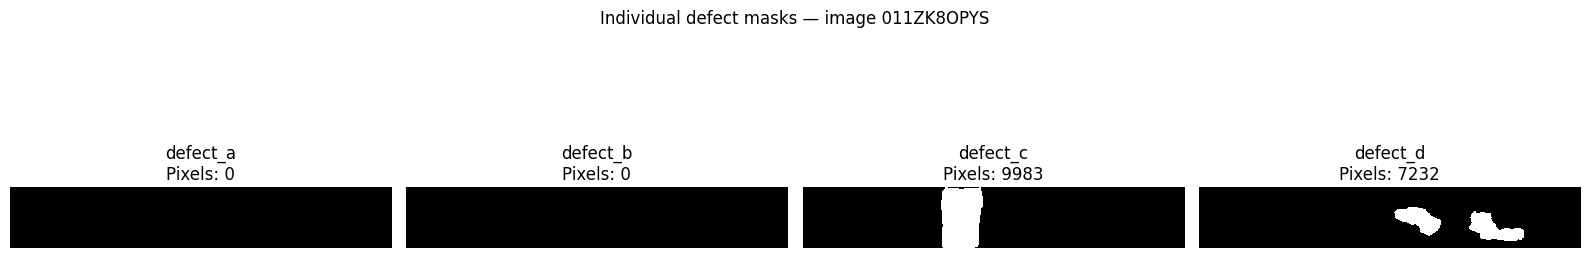

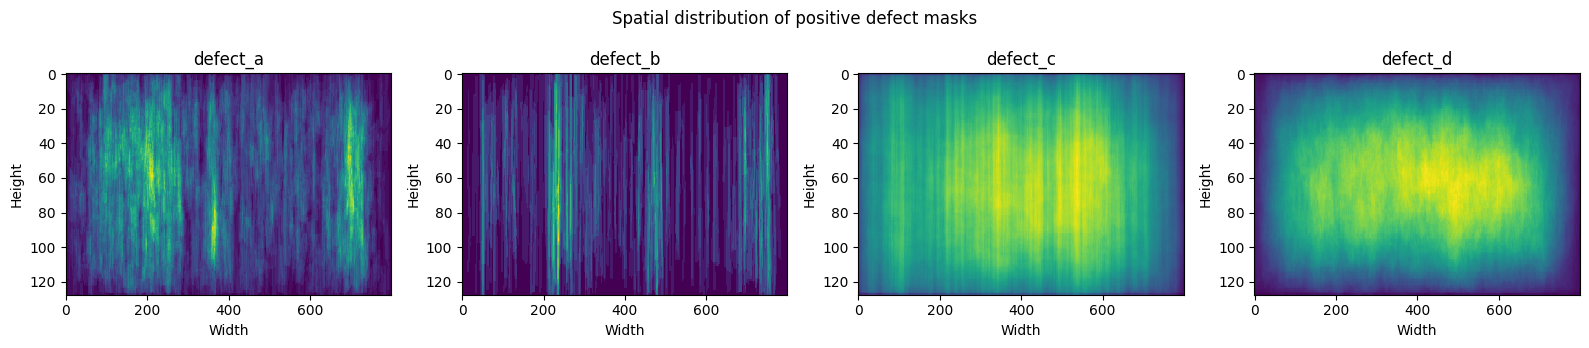

In [16]:

import matplotlib.pyplot as plt
import numpy as np

# Find an image containing at least two defect classes
multi_ids = (
    df.groupby("image_id")["has_defect"]
      .sum()
      .loc[lambda s: s > 1]
      .index
)

image_id = multi_ids[0]
group = df[df["image_id"] == image_id]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, (_, row) in zip(axes, group.iterrows()):
    mask = decode_rle(row["mask_rle"])
    ax.imshow(mask, cmap="gray", interpolation="nearest")
    ax.set_title(f'{row["defect_type"]}\nPixels: {int(mask.sum())}')
    ax.axis("off")

fig.suptitle(f"Individual defect masks — image {image_id}")
plt.tight_layout()
plt.show()

# Aggregate spatial heatmaps for each defect class
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))

for ax, defect_type in zip(
    axes, ["defect_a", "defect_b", "defect_c", "defect_d"]
):
    rows = df[
        (df["defect_type"] == defect_type) & df["has_defect"]
    ]

    heatmap = np.zeros((HEIGHT, WIDTH), dtype=np.float64)

    for rle in rows["mask_rle"]:
        heatmap += decode_rle(rle)

    ax.imshow(heatmap, aspect="auto", interpolation="nearest")
    ax.set_title(defect_type)
    ax.set_xlabel("Width")
    ax.set_ylabel("Height")

fig.suptitle("Spatial distribution of positive defect masks")
plt.tight_layout()
plt.show()


In [17]:

MAX_PIXELS = HEIGHT * WIDTH

rows_with_overrun = 0
runs_with_overrun = 0
max_end_index = 0
total_runs = 0

for rle in df["mask_rle"].dropna():
    rle = str(rle).strip()

    if not rle:
        continue

    values = np.fromstring(rle, sep=" ", dtype=np.int64)

    if len(values) % 2 != 0:
        print("WARNING: Odd number of RLE values:", rle[:100])
        continue

    starts = values[0::2]
    lengths = values[1::2]
    end_indices = starts + lengths - 1

    total_runs += len(end_indices)

    if len(end_indices) > 0:
        max_end_index = max(max_end_index, int(end_indices.max()))

    bad_runs = end_indices > MAX_PIXELS
    runs_with_overrun += int(bad_runs.sum())

    if bad_runs.any():
        rows_with_overrun += 1

print("Valid canvas pixel count:", MAX_PIXELS)
print("Total RLE runs checked:", total_runs)
print("Rows containing at least one overrun:", rows_with_overrun)
print("Individual runs exceeding the canvas:", runs_with_overrun)
print("Maximum RLE end index encountered:", max_end_index)


Valid canvas pixel count: 102400
Total RLE runs checked: 797406
Rows containing at least one overrun: 0
Individual runs exceeding the canvas: 0
Maximum RLE end index encountered: 102400


In [18]:

original_height, original_width = 128, 800
target_height, target_width = 256, 256

scale_y = target_height / original_height
scale_x = target_width / original_width
ratio = scale_y / scale_x

print("Vertical scale (sy):", scale_y)
print("Horizontal scale (sx):", scale_x)
print("Vertical stretch / horizontal compression ratio:", ratio)


Vertical scale (sy): 2.0
Horizontal scale (sx): 0.32
Vertical stretch / horizontal compression ratio: 6.25


In [19]:

import cv2
import numpy as np
from pathlib import Path

image_dir = base / "train"
classes = ["defect_a", "defect_b", "defect_c", "defect_d"]

# Accumulate intensity statistics without storing every pixel.
stats = {
    c: {
        "defect_n": 0, "defect_sum": 0.0, "defect_sq": 0.0,
        "bg_n": 0, "bg_sum": 0.0, "bg_sq": 0.0
    }
    for c in classes
}

missing_images = []
image_extensions = [".jpg", ".jpeg", ".png", ".tif", ".tiff"]

for image_id, group in df.groupby("image_id", sort=False):
    image_path = next(
        (image_dir / f"{image_id}{ext}"
         for ext in image_extensions
         if (image_dir / f"{image_id}{ext}").exists()),
        None
    )

    if image_path is None:
        missing_images.append(image_id)
        continue

    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    if image is None or image.shape != (HEIGHT, WIDTH):
        print("WARNING: Could not load expected-size image:", image_path)
        continue

    for _, row in group.iterrows():
        c = row["defect_type"]
        mask = decode_rle(row["mask_rle"]).astype(bool)

        defect_pixels = image[mask].astype(np.float64)
        bg_pixels = image[~mask].astype(np.float64)

        s = stats[c]
        s["defect_n"] += defect_pixels.size
        s["defect_sum"] += defect_pixels.sum()
        s["defect_sq"] += np.square(defect_pixels).sum()
        s["bg_n"] += bg_pixels.size
        s["bg_sum"] += bg_pixels.sum()
        s["bg_sq"] += np.square(bg_pixels).sum()

def get_mean_var(n, total, total_sq):
    mean = total / n
    variance = max(0.0, (total_sq - total**2 / n) / (n - 1)) if n > 1 else 0.0
    return mean, variance

print("Missing image files:", len(missing_images))
print("\nCohen's d results (defect intensity minus background intensity):")

for c in classes:
    s = stats[c]
    n1, n2 = s["defect_n"], s["bg_n"]

    if n1 < 2 or n2 < 2:
        print(c, "Insufficient pixels")
        continue

    mean1, var1 = get_mean_var(n1, s["defect_sum"], s["defect_sq"])
    mean2, var2 = get_mean_var(n2, s["bg_sum"], s["bg_sq"])

    pooled_var = ((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2)
    pooled_std = np.sqrt(pooled_var)
    d = (mean1 - mean2) / pooled_std if pooled_std > 0 else np.nan

    print(
        f"{c}: d={d:.6f}, "
        f"defect_mean={mean1:.3f}, background_mean={mean2:.3f}"
    )


Missing image files: 0

Cohen's d results (defect intensity minus background intensity):
defect_a: d=0.176553, defect_mean=96.957, background_mean=88.474
defect_b: d=0.111320, defect_mean=93.828, background_mean=88.479
defect_c: d=0.383041, defect_mean=106.499, background_mean=88.121
defect_d: d=0.007413, defect_mean=88.833, background_mean=88.476


In [20]:
def dice_score(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=bool)
    y_pred = np.asarray(y_pred, dtype=bool)

    if y_true.sum() == 0 and y_pred.sum() == 0:
        return 1.0

    intersection = np.logical_and(y_true, y_pred).sum()
    return 2.0 * intersection / (y_true.sum() + y_pred.sum())

empty_gt = np.zeros((128, 800), dtype=bool)

# Model 1 predicts an empty mask
pred_empty = np.zeros_like(empty_gt)

# Model 2 predicts two stray pixels
pred_two_pixels = np.zeros_like(empty_gt)
pred_two_pixels[10, 10] = True
pred_two_pixels[20, 20] = True

print("Model 1 Dice:", dice_score(empty_gt, pred_empty))
print("Model 2 Dice:", dice_score(empty_gt, pred_two_pixels))

Model 1 Dice: 1.0
Model 2 Dice: 0.0


In [21]:

import cv2
import numpy as np
import pandas as pd

# Collect ground-truth connected-component areas for each defect class.
component_areas = {name: [] for name in ["defect_a", "defect_b",
                                         "defect_c", "defect_d"]}
total_gt_pixels = {name: 0 for name in component_areas}

for _, row in df.iterrows():
    defect = row["defect_type"]
    mask = decode_rle(row["mask_rle"])

    total_gt_pixels[defect] += int(mask.sum())

    if mask.sum() == 0:
        continue

    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        mask.astype(np.uint8), connectivity=8
    )

    # Label 0 is the background; process labels 1 onward.
    areas = stats[1:, cv2.CC_STAT_AREA]
    component_areas[defect].extend(areas.tolist())

# Q10: smallest component for defect_b
area_min_b = min(component_areas["defect_b"])

# Pixel-loss percentage for components strictly smaller than N.
def lost_pixel_percentage(defect, threshold):
    areas = np.asarray(component_areas[defect], dtype=np.int64)
    lost_pixels = areas[areas < threshold].sum()
    total_pixels = total_gt_pixels[defect]
    return 100.0 * lost_pixels / total_pixels

lost_b_50 = lost_pixel_percentage("defect_b", 50)
lost_a_200 = lost_pixel_percentage("defect_a", 200)

print("Smallest defect_b component area:", area_min_b)
print(f"defect_b pixels lost at N=50: {lost_b_50:.4f}%")
print(f"defect_a pixels lost at N=200: {lost_a_200:.4f}%")


Smallest defect_b component area: 93
defect_b pixels lost at N=50: 0.0000%
defect_a pixels lost at N=200: 15.2171%


In [22]:

from pathlib import Path
import pandas as pd

root = Path("/kaggle/input")

sample_files = list(root.rglob("sample_submission.csv"))
train_files = list(root.rglob("train.csv"))
test_dirs = [
    path for path in root.rglob("test")
    if path.is_dir()
]

print("SAMPLE SUBMISSION FILES")
for path in sample_files:
    print(path)

print("\nTRAIN ANNOTATION FILES")
for path in train_files:
    print(path)

print("\nTEST IMAGE DIRECTORIES")
for directory in test_dirs:
    count = sum(
        1 for path in directory.rglob("*")
        if path.is_file()
        and path.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )
    print(f"{directory} | images: {count}")

if not sample_files:
    raise FileNotFoundError(
        "sample_submission.csv not found under /kaggle/input"
    )

sample = pd.read_csv(
    sample_files[0],
    keep_default_na=False
)

print("\nSAMPLE SUBMISSION SHAPE:", sample.shape)
print("COLUMNS:", sample.columns.tolist())
print(sample.head(8).to_string(index=False))


SAMPLE SUBMISSION FILES
/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv

TRAIN ANNOTATION FILES
/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv

TEST IMAGE DIRECTORIES
/kaggle/input/competitions/industrial-surface-defect-detection/public/test | images: 3000

SAMPLE SUBMISSION SHAPE: (12000, 4)
COLUMNS: ['ID', 'image_id', 'defect_type', 'mask_rle']
 ID   image_id defect_type mask_rle
  1 WAFNKCRR7Q    defect_a         
  2 WAFNKCRR7Q    defect_b         
  3 WAFNKCRR7Q    defect_c         
  4 WAFNKCRR7Q    defect_d         
  5 YZXKEWSUDD    defect_a         
  6 YZXKEWSUDD    defect_b         
  7 YZXKEWSUDD    defect_c         
  8 YZXKEWSUDD    defect_d         


In [23]:
from pathlib import Path

for name in ["best.pt", "model_config.json"]:
    matches = list(Path("/kaggle/input").rglob(name))
    print(f"\n{name}:")
    if matches:
        for path in matches:
            print(f"FOUND: {path} ({path.stat().st_size:,} bytes)")
    else:
        print("NOT FOUND")


best.pt:
FOUND: /kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/best.pt (97,880,383 bytes)

model_config.json:
FOUND: /kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/model_config.json (813 bytes)


In [24]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [25]:
from pathlib import Path
import importlib.util
import subprocess
import sys
import json
import numpy as np
import pandas as pd
import torch
from PIL import Image

if importlib.util.find_spec("segmentation_models_pytorch") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "segmentation-models-pytorch"
    ])

import segmentation_models_pytorch as smp

MODEL_ROOT = Path("/kaggle/input/models")
TEST_DIR = Path(
    "/kaggle/input/competitions/"
    "industrial-surface-defect-detection/public/test"
)
SAMPLE_PATH = Path(
    "/kaggle/input/competitions/"
    "industrial-surface-defect-detection/public/sample_submission.csv"
)

CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
HEIGHT, WIDTH = 128, 800

checkpoint_matches = list(MODEL_ROOT.rglob("best.pt"))
if len(checkpoint_matches) != 1:
    raise RuntimeError(
        f"Expected one attached checkpoint, found {len(checkpoint_matches)}"
    )

CHECKPOINT_PATH = checkpoint_matches[0]
CONFIG_PATH = CHECKPOINT_PATH.parent / "model_config.json"

if not CONFIG_PATH.is_file():
    raise FileNotFoundError(f"Missing model config: {CONFIG_PATH}")

with CONFIG_PATH.open() as f:
    model_config = json.load(f)

if model_config["class_order"] != CLASSES:
    raise ValueError("Model class order does not match the expected order.")

if (model_config["height"], model_config["width"]) != (HEIGHT, WIDTH):
    raise ValueError("Model input dimensions do not match.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Checkpoint:", CHECKPOINT_PATH)
print("Checkpoint size:", f"{CHECKPOINT_PATH.stat().st_size:,} bytes")
print("SMP version:", __import__("importlib.metadata").metadata.version(
    "segmentation-models-pytorch"
))

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=1,
    classes=4,
    activation=None,
)

try:
    state_dict = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=True
    )
except TypeError:
    state_dict = torch.load(CHECKPOINT_PATH, map_location="cpu")

model.load_state_dict(state_dict, strict=True)
model = model.to(device).eval()

sample = pd.read_csv(SAMPLE_PATH, keep_default_na=False)
image_ids = sample["image_id"].drop_duplicates().head(4).tolist()
extensions = [".jpg", ".jpeg", ".png", ".tif", ".tiff"]

batch_images = []

for image_id in image_ids:
    image_path = next(
        (
            TEST_DIR / f"{image_id}{ext}"
            for ext in extensions
            if (TEST_DIR / f"{image_id}{ext}").is_file()
        ),
        None
    )

    if image_path is None:
        raise FileNotFoundError(f"Test image not found: {image_id}")

    with Image.open(image_path) as image:
        array = np.asarray(image.convert("L"), dtype=np.float32) / 255.0

    if array.shape != (HEIGHT, WIDTH):
        raise ValueError(
            f"Unexpected dimensions for {image_id}: {array.shape}"
        )

    array = (array - array.mean()) / max(float(array.std()), 0.05)
    batch_images.append(array)

batch = torch.from_numpy(
    np.stack(batch_images)[:, None].copy()
).to(device)

with torch.inference_mode():
    probabilities = torch.sigmoid(model(batch)).cpu().numpy()

if probabilities.shape != (len(image_ids), 4, HEIGHT, WIDTH):
    raise RuntimeError(f"Unexpected output shape: {probabilities.shape}")

if not np.isfinite(probabilities).all():
    raise RuntimeError("Predictions contain NaN or infinite values.")

print("\nInference smoke test passed.")
print("Input tensor shape:", tuple(batch.shape))
print("Output tensor shape:", probabilities.shape)
print("Probability range:", float(probabilities.min()), float(probabilities.max()))

for index, image_id in enumerate(image_ids):
    print(f"\nImage: {image_id}")
    for class_index, defect_type in enumerate(CLASSES):
        fraction = float(
            (probabilities[index, class_index] >= 0.5).mean()
        )
        print(f"  {defect_type}: predicted pixel fraction = {fraction:.6f}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.6/154.6 kB 2.2 MB/s eta 0:00:00
Device: cuda
GPU: Tesla T4
Checkpoint: /kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/best.pt
Checkpoint size: 97,880,383 bytes
SMP version: 0.6.0

Inference smoke test passed.
Input tensor shape: (4, 1, 128, 800)
Output tensor shape: (4, 4, 128, 800)
Probability range: 1.274132355177926e-08 0.9951377511024475

Image: WAFNKCRR7Q
  defect_a: predicted pixel fraction = 0.000000
  defect_b: predicted pixel fraction = 0.000000
  defect_c: predicted pixel fraction = 0.000000
  defect_d: predicted pixel fraction = 0.000000

Image: YZXKEWSUDD
  defect_a: predicted pixel fraction = 0.000137
  defect_b: predicted pixel fraction = 0.000078
  defect_c: predicted pixel fraction = 0.003330
  defect_d: predicted pixel fraction = 0.000000

Image: 0ATN06ZB48
  defect_a: predicted pixel fraction = 0.012666
  defect_b: predicted pixel fraction = 0.011279
  defect_c: predic

In [26]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
from PIL import Image
import segmentation_models_pytorch as smp

ROOT = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")
TEST_DIR = ROOT / "test"
SAMPLE_PATH = ROOT / "sample_submission.csv"
MODEL_DIR = Path("/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2")
CHECKPOINT = MODEL_DIR / "best.pt"
CONFIG_PATH = MODEL_DIR / "model_config.json"
OUTPUT_PATH = Path("/kaggle/working/submission_resnet34_unet_t050.csv")

CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
HEIGHT, WIDTH = 128, 800
THRESHOLD = 0.35
BATCH_SIZE = 8
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for path in [TEST_DIR, SAMPLE_PATH, CHECKPOINT, CONFIG_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Required path not found: {path}")

with CONFIG_PATH.open() as f:
    config = json.load(f)

if config["class_order"] != CLASSES:
    raise ValueError("Checkpoint class order does not match the submission classes.")

if (config["height"], config["width"]) != (HEIGHT, WIDTH):
    raise ValueError("Checkpoint dimensions do not match the expected image size.")

sample = pd.read_csv(SAMPLE_PATH, keep_default_na=False)
required_columns = ["ID", "image_id", "defect_type", "mask_rle"]

if sample.columns.tolist() != required_columns:
    raise ValueError(f"Unexpected submission columns: {sample.columns.tolist()}")

if len(sample) != 12000 or sample["image_id"].nunique() != 3000:
    raise ValueError("Unexpected sample submission dimensions.")

if set(sample["defect_type"].unique()) != set(CLASSES):
    raise ValueError("Sample submission defect classes do not match.")

def encode_rle(mask):
    pixels = np.asarray(mask, dtype=np.uint8).reshape(-1, order="F")
    padded = np.pad(pixels, (1, 1))
    changes = np.flatnonzero(padded[1:] != padded[:-1]) + 1

    if changes.size == 0:
        return ""

    runs = changes.copy()
    runs[1::2] -= runs[::2]
    return " ".join(map(str, runs.tolist()))

def decode_rle(rle, shape):
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)

    if not rle.strip():
        return flat.reshape(shape, order="F")

    values = np.fromstring(rle, sep=" ", dtype=np.int64)

    if len(values) % 2:
        raise ValueError("RLE must contain start-length pairs.")

    starts = values[0::2] - 1
    lengths = values[1::2]

    if np.any(starts < 0) or np.any(lengths <= 0):
        raise ValueError("Invalid RLE start or length.")

    for start, length in zip(starts, lengths):
        end = start + length
        if end > flat.size:
            raise ValueError("RLE exceeds the image dimensions.")
        flat[start:end] = 1

    return flat.reshape(shape, order="F")

toy = np.zeros((7, 9), dtype=np.uint8)
toy[1:4, 2] = 1
toy[5, 7:9] = 1

if not np.array_equal(toy, decode_rle(encode_rle(toy), toy.shape)):
    raise RuntimeError("RLE round-trip test failed.")

extensions = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
image_paths = {
    path.stem: path
    for path in TEST_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in extensions
}

image_ids = sample["image_id"].drop_duplicates().tolist()
missing_ids = [image_id for image_id in image_ids if image_id not in image_paths]

if missing_ids:
    raise FileNotFoundError(
        f"{len(missing_ids)} test images could not be located. "
        f"Examples: {missing_ids[:5]}"
    )

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=1,
    classes=4,
    activation=None,
)

try:
    state_dict = torch.load(
        CHECKPOINT,
        map_location="cpu",
        weights_only=True,
    )
except TypeError:
    state_dict = torch.load(CHECKPOINT, map_location="cpu")

model.load_state_dict(state_dict, strict=True)
model.to(DEVICE).eval()

predictions = {}
positive_pixels = np.zeros(4, dtype=np.int64)
empty_masks = 0

for start in range(0, len(image_ids), BATCH_SIZE):
    batch_ids = image_ids[start:start + BATCH_SIZE]
    arrays = []

    for image_id in batch_ids:
        with Image.open(image_paths[image_id]) as image:
            array = np.asarray(image.convert("L"), dtype=np.float32) / 255.0

        if array.shape != (HEIGHT, WIDTH):
            raise ValueError(
                f"{image_id}: expected {(HEIGHT, WIDTH)}, got {array.shape}"
            )

        array = (array - array.mean()) / max(float(array.std()), 0.05)
        arrays.append(array)

    tensor = torch.from_numpy(
        np.stack(arrays)[:, None].copy()
    ).to(DEVICE)

    with torch.inference_mode():
        probabilities = torch.sigmoid(model(tensor)).cpu().numpy()

    if not np.isfinite(probabilities).all():
        raise RuntimeError("Model produced non-finite predictions.")

    for i, image_id in enumerate(batch_ids):
        for class_index, defect_type in enumerate(CLASSES):
            mask = probabilities[i, class_index] >= THRESHOLD
            positive_pixels[class_index] += int(mask.sum())

            if not mask.any():
                empty_masks += 1

            predictions[(image_id, defect_type)] = encode_rle(mask)

    completed = min(start + len(batch_ids), len(image_ids))

    if completed % 400 == 0 or completed == len(image_ids):
        print(f"Processed {completed}/{len(image_ids)} images")

if len(predictions) != len(sample):
    raise RuntimeError(
        f"Expected {len(sample)} predictions; got {len(predictions)}."
    )

submission = sample.copy()
submission["mask_rle"] = [
    predictions[(image_id, defect_type)]
    for image_id, defect_type in zip(
        sample["image_id"], sample["defect_type"]
    )
]

if submission.isna().any().any():
    raise ValueError("Submission contains missing values.")

if submission[["image_id", "defect_type"]].duplicated().any():
    raise ValueError("Duplicate image/category combinations found.")

submission.to_csv(OUTPUT_PATH, index=False)

check = pd.read_csv(OUTPUT_PATH, keep_default_na=False)

if not check.equals(submission):
    raise RuntimeError("Saved submission does not match the generated dataframe.")

print("\nSubmission created and verified.")
print("Output:", OUTPUT_PATH)
print("Shape:", check.shape)
print("Columns:", check.columns.tolist())
print("Unique images:", check["image_id"].nunique())
print("Threshold:", THRESHOLD)
print("Empty masks:", empty_masks, "of", len(check))
print("Predicted foreground pixels by class:", dict(zip(CLASSES, positive_pixels)))
print(check.head(8).to_string(index=False))

Processed 400/3000 images
Processed 800/3000 images
Processed 1200/3000 images
Processed 1600/3000 images
Processed 2000/3000 images
Processed 2400/3000 images
Processed 2800/3000 images
Processed 3000/3000 images

Submission created and verified.
Output: /kaggle/working/submission_resnet34_unet_t050.csv
Shape: (12000, 4)
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
Unique images: 3000
Threshold: 0.35
Empty masks: 2636 of 12000
Predicted foreground pixels by class: {'defect_a': np.int64(1688526), 'defect_b': np.int64(1588546), 'defect_c': np.int64(4821976), 'defect_d': np.int64(11738910)}
 ID   image_id defect_type                                                                                                                                                                                                                                                                                                              mask_rle
  1 WAFNKCRR7Q    defect_a                               

In [27]:
from pathlib import Path
import pandas as pd

root = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")
working = Path("/kaggle/working")

sample_path = root / "sample_submission.csv"
model_path = working / "submission_resnet34_unet_t050.csv"
final_path = working / "submission.csv"

if not model_path.is_file():
    raise FileNotFoundError(
        f"Trained-model predictions not found: {model_path}"
    )

sample = pd.read_csv(sample_path, keep_default_na=False)
predictions = pd.read_csv(model_path, keep_default_na=False)

expected_columns = ["ID", "image_id", "defect_type", "mask_rle"]

if predictions.columns.tolist() != expected_columns:
    raise ValueError("Trained-model submission has incorrect columns.")

if len(predictions) != 12000 or len(sample) != 12000:
    raise ValueError("Unexpected submission row count.")

if not predictions[expected_columns[:3]].equals(sample[expected_columns[:3]]):
    raise ValueError("Prediction IDs or row order do not match the sample.")

nonempty = predictions["mask_rle"].astype(str).str.strip().ne("").sum()

if nonempty == 0:
    raise ValueError(
        "Every predicted mask is empty. Do not submit this file yet."
    )

predictions.to_csv(final_path, index=False)

verified = pd.read_csv(final_path, keep_default_na=False)

if not verified.equals(predictions):
    raise RuntimeError("Final submission verification failed.")

print("Final trained-model submission created.")
print("File:", final_path)
print("Rows:", len(verified))
print("Non-empty predicted masks:", nonempty)
print("Empty predicted masks:", len(verified) - nonempty)
print("Columns:", verified.columns.tolist())
print(verified.head(8).to_string(index=False))

Final trained-model submission created.
File: /kaggle/working/submission.csv
Rows: 12000
Non-empty predicted masks: 9364
Empty predicted masks: 2636
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
 ID   image_id defect_type                                                                                                                                                                                                                                                                                                              mask_rle
  1 WAFNKCRR7Q    defect_a                                                                                                                                                                                                                                                                                                                      
  2 WAFNKCRR7Q    defect_b                                                                                                

In [28]:
from pathlib import Path
import csv
import pandas as pd

root = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")
sample_path = root / "sample_submission.csv"

source_path = Path("/kaggle/working/submission_resnet34_unet_t050.csv")
output_path = Path("/kaggle/working/submission.csv")

if not source_path.is_file():
    raise FileNotFoundError(f"Trained-model submission not found: {source_path}")

sample = pd.read_csv(sample_path, keep_default_na=False)
submission = pd.read_csv(source_path, keep_default_na=False)

expected_columns = ["ID", "image_id", "defect_type", "mask_rle"]

if submission.columns.tolist() != expected_columns:
    raise ValueError(f"Unexpected columns: {submission.columns.tolist()}")

if len(submission) != len(sample):
    raise ValueError("Submission row count does not match the sample.")

if not submission[["ID", "image_id", "defect_type"]].equals(
    sample[["ID", "image_id", "defect_type"]]
):
    raise ValueError("Submission IDs or row order differ from the sample.")

empty_mask = submission["mask_rle"].astype(str).str.strip().eq("")
submission.loc[empty_mask, "mask_rle"] = " "

submission.to_csv(
    output_path,
    index=False,
    quoting=csv.QUOTE_ALL,
)

verified = pd.read_csv(output_path)

if verified.isna().any().any():
    raise ValueError(
        f"Null values remain:\n{verified.isna().sum()}"
    )

if len(verified) != 12000:
    raise ValueError("Expected exactly 12,000 prediction rows.")

print("Submission validated successfully.")
print("File:", output_path)
print("Rows:", len(verified))
print("Null values:", int(verified.isna().sum().sum()))
print(
    "Empty masks represented by spaces:",
    int(verified["mask_rle"].astype(str).str.strip().eq("").sum())
)
print("Columns:", verified.columns.tolist())

Submission validated successfully.
File: /kaggle/working/submission.csv
Rows: 12000
Null values: 0
Empty masks represented by spaces: 2636
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']


In [29]:

# SurfaceGuard AI — Kaggle GPU training setup

from pathlib import Path
import random
import json
import importlib.util
import subprocess
import sys

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

# Install segmentation library only if needed
if importlib.util.find_spec("segmentation_models_pytorch") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "segmentation-models-pytorch"
    ])

import segmentation_models_pytorch as smp

# Competition dataset paths
DATA_ROOT = Path(
    "/kaggle/input/competitions/"
    "industrial-surface-defect-detection/public"
)

OUTPUT_DIR = Path("/kaggle/working/surfaceguard_training")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Project configuration — matches the existing model
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
HEIGHT, WIDTH = 128, 800
VAL_FRACTION = 0.20
SEED = 42
EPOCHS = 10
BATCH_SIZE = 8
ENCODER = "resnet34"
ENCODER_WEIGHTS = "imagenet"

THRESHOLDS = [
    0.10, 0.15, 0.20, 0.25, 0.30,
    0.35, 0.40, 0.45, 0.50, 0.55,
    0.60, 0.65, 0.70, 0.75, 0.80,
    0.85, 0.90
]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

for path in [
    DATA_ROOT / "train.csv",
    DATA_ROOT / "train",
    DATA_ROOT / "test",
]:
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {path}")

assert DEVICE.type == "cuda", "GPU is not enabled in Kaggle settings."
assert (DATA_ROOT / "train.csv").is_file(), "Training CSV not found."
assert (DATA_ROOT / "train").is_dir(), "Training image folder not found."


Device: cuda
GPU: Tesla T4
FOUND: /kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv
FOUND: /kaggle/input/competitions/industrial-surface-defect-detection/public/train
FOUND: /kaggle/input/competitions/industrial-surface-defect-detection/public/test


In [30]:

# Step 2B: Load annotations and create a reproducible split

annotations = pd.read_csv(
    DATA_ROOT / "train.csv",
    dtype=str,
    keep_default_na=False
)

required = {"image_id", "defect_type", "mask_rle", "height", "width"}

if not required.issubset(annotations.columns):
    raise ValueError(
        f"Missing CSV columns: {required - set(annotations.columns)}"
    )

if set(annotations["defect_type"]) != set(CLASSES):
    raise ValueError("Unexpected defect classes in train.csv")

if annotations.duplicated(["image_id", "defect_type"]).any():
    raise ValueError("Duplicate image-class rows found")

if not (annotations.groupby("image_id").size() == len(CLASSES)).all():
    raise ValueError("Each image must have one row per defect class")

if not (
    (annotations["height"].astype(int) == HEIGHT)
    & (annotations["width"].astype(int) == WIDTH)
).all():
    raise ValueError("Expected image dimensions: 128 × 800")

annotations["mask_rle"] = annotations["mask_rle"].str.strip()

rle_table = (
    annotations.pivot(
        index="image_id",
        columns="defect_type",
        values="mask_rle"
    )
    .reindex(columns=CLASSES)
    .sort_index()
)

presence = rle_table.ne("")

def combination_string(row):
    active = [name for name in CLASSES if row[name]]
    return "+".join(active) if active else "clean"

image_table = presence.copy()
image_table["label_combo"] = presence.apply(
    combination_string, axis=1
)

combination_counts = image_table["label_combo"].value_counts()

print("Annotation rows:", len(annotations))
print("Unique training images:", len(image_table))
print("\nClass presence:")
print(presence.sum().to_string())
print("\nLabel combinations:")
print(combination_counts.to_string())

if combination_counts.min() < 2:
    raise ValueError(
        "At least one label combination occurs fewer than twice. "
        "We need to handle that before splitting."
    )

train_ids, val_ids = train_test_split(
    image_table.index.to_numpy(),
    test_size=VAL_FRACTION,
    random_state=SEED,
    stratify=image_table["label_combo"].to_numpy()
)

assert not set(train_ids) & set(val_ids)
assert set(train_ids) | set(val_ids) == set(image_table.index)

split_table = image_table[["label_combo"]].copy()
split_table["partition"] = "train"
split_table.loc[val_ids, "partition"] = "validation"

split_table.to_csv(
    OUTPUT_DIR / "holdout.csv",
    index_label="image_id"
)

print("\nTraining images:", len(train_ids))
print("Validation images:", len(val_ids))
print("Saved split:", OUTPUT_DIR / "holdout.csv")


Annotation rows: 45572
Unique training images: 11393

Class presence:
defect_type
defect_a    1081
defect_b     313
defect_c    4100
defect_d    1707

Label combinations:
label_combo
clean                         5516
defect_c                      3105
defect_d                       822
defect_a                       601
defect_c+defect_d              598
defect_a+defect_c              215
defect_b                       151
defect_a+defect_d              136
defect_a+defect_c+defect_d      87
defect_b+defect_c               67
defect_b+defect_d               33
defect_a+defect_b               23
defect_b+defect_c+defect_d      20
defect_a+defect_b+defect_d      11
defect_a+defect_b+defect_c       8

Training images: 9114
Validation images: 2279
Saved split: /kaggle/working/surfaceguard_training/holdout.csv


In [31]:

# # Step 3 — Verify the split and image paths

# print("Training images:", len(train_df))
# print("Validation images:", len(val_df))

# print("\nTraining split preview:")
# display(train_df.head())

# print("\nValidation split preview:")
# display(val_df.head())

# # Check that train and validation images do not overlap
# train_ids = set(train_df["image_id"].astype(str))
# val_ids = set(val_df["image_id"].astype(str))

# print("\nOverlapping images:", len(train_ids & val_ids))
# assert len(train_ids & val_ids) == 0, "Data leakage: overlapping images!"

# # Check a few image paths
# for image_id in list(train_ids)[:5]:
#     matches = list((DATA_ROOT / "train").glob(f"{image_id}.*"))
#     print(image_id, "->", matches[0] if matches else "NOT FOUND")


In [32]:

# Step 3A — Inspect the saved split

holdout = pd.read_csv(
    OUTPUT_DIR / "holdout.csv",
    dtype=str,
    keep_default_na=False
)

print("Shape:", holdout.shape)
print("Columns:", holdout.columns.tolist())
display(holdout.head())

for col in holdout.columns:
    if "split" in col.lower():
        print(f"\nValues in {col}:")
        print(holdout[col].value_counts())


Shape: (11393, 3)
Columns: ['image_id', 'label_combo', 'partition']


,image_id,label_combo,partition
0,000HAM628W,defect_c,train
1,005VFS2MW4,defect_d,train
2,0070O9IJVX,defect_d,train
3,00761I10TU,defect_c,train
4,009DUJJXC1,clean,train


In [33]:

# Step 3B — Verify train/validation split

train_df = holdout[holdout["partition"] == "train"].copy()
val_df = holdout[holdout["partition"] == "validation"].copy()

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

print("\nTraining label combinations:")
print(train_df["label_combo"].value_counts())

print("\nValidation label combinations:")
print(val_df["label_combo"].value_counts())

# Verify no image occurs in both partitions
train_ids = set(train_df["image_id"])
val_ids = set(val_df["image_id"])

print("\nOverlapping images:", len(train_ids & val_ids))
assert len(train_ids & val_ids) == 0, "Train/validation overlap detected!"

# Check actual image filenames
image_dir = DATA_ROOT / "train"

for image_id in train_df["image_id"].head(5):
    matches = list(image_dir.glob(f"{image_id}.*"))
    print(image_id, "->", matches[0] if matches else "NOT FOUND")

assert len(train_df) > 0 and len(val_df) > 0


Training images: 9114
Validation images: 2279

Training label combinations:
label_combo
clean                         4413
defect_c                      2484
defect_d                       657
defect_a                       481
defect_c+defect_d              478
defect_a+defect_c              172
defect_b                       121
defect_a+defect_d              109
defect_a+defect_c+defect_d      70
defect_b+defect_c               54
defect_b+defect_d               26
defect_a+defect_b               18
defect_b+defect_c+defect_d      16
defect_a+defect_b+defect_d       9
defect_a+defect_b+defect_c       6
Name: count, dtype: int64

Validation label combinations:
label_combo
clean                         1103
defect_c                       621
defect_d                       165
defect_c+defect_d              120
defect_a                       120
defect_a+defect_c               43
defect_b                        30
defect_a+defect_d               27
defect_a+defect_c+defect_d      17
de

In [34]:

# Step 4 — Build image masks and PyTorch dataset

from collections import defaultdict

annotations = pd.read_csv(
    DATA_ROOT / "train.csv",
    dtype=str,
    keep_default_na=False
)

print("Annotation columns:", annotations.columns.tolist())

def decode_rle(rle, height=HEIGHT, width=WIDTH):
    """Decode a competition RLE mask into a 2D binary mask."""
    mask = np.zeros(height * width, dtype=np.uint8)

    if not rle or not rle.strip():
        return mask.reshape(height, width)

    values = np.asarray(rle.split(), dtype=np.int64)
    starts = values[0::2] - 1
    lengths = values[1::2]

    for start, length in zip(starts, lengths):
        mask[start:start + length] = 1

    # RLE convention: column-major / Fortran order
    return mask.reshape((height, width), order="F")


# One binary mask per image and defect class
mask_lookup = defaultdict(
    lambda: np.zeros((len(CLASSES), HEIGHT, WIDTH), dtype=np.uint8)
)

for row in tqdm(annotations.itertuples(index=False),
                total=len(annotations),
                desc="Decoding masks"):
    image_id = str(row.image_id)
    defect_type = str(row.defect_type)
    rle = str(row.mask_rle)

    if defect_type not in CLASSES:
        continue

    class_idx = CLASSES.index(defect_type)
    decoded = decode_rle(rle)

    mask_lookup[image_id][class_idx] = np.maximum(
        mask_lookup[image_id][class_idx],
        decoded
    )

print("Images with decoded masks:", len(mask_lookup))
print("Mask shape:", next(iter(mask_lookup.values())).shape)
print("Classes:", CLASSES)


Annotation columns: ['image_id', 'defect_type', 'mask_rle', 'width', 'height']


Decoding masks:   0%|          | 0/45572 [00:00<?, ?it/s]

Images with decoded masks: 11393
Mask shape: (4, 128, 800)
Classes: ['defect_a', 'defect_b', 'defect_c', 'defect_d']


In [35]:

# Step 5 — Create the PyTorch dataset (V4)

import random

class SurfaceDefectDataset(Dataset):
    def __init__(self, dataframe, image_dir, mask_lookup, augment=False):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.mask_lookup = mask_lookup
        self.augment = augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image_id = str(row["image_id"])

        image_path = self.image_dir / f"{image_id}.jpg"

        image = Image.open(image_path).convert("L")
        image = image.resize(
            (WIDTH, HEIGHT),
            Image.Resampling.BILINEAR
        )
        image = np.asarray(image, dtype=np.float32) / 255.0

        # Match the original grayscale normalization
        mean = image.mean()
        std = max(float(image.std()), 0.05)
        image = (image - mean) / std

        # Load the four-channel segmentation mask
        mask = self.mask_lookup[image_id].astype(np.float32)

        # Augmentation: transform image and mask together
        if self.augment:
            if random.random() < 0.5:
                image = np.flip(image, axis=1)
                mask = np.flip(mask, axis=2)

            if random.random() < 0.5:
                image = np.flip(image, axis=0)
                mask = np.flip(mask, axis=1)

        # Copy arrays to avoid negative-stride tensor errors
        image = torch.from_numpy(
            image.copy()
        ).unsqueeze(0)

        mask = torch.from_numpy(mask.copy())

        return image, mask


# Augmentation is enabled ONLY for training
train_dataset = SurfaceDefectDataset(
    train_df,
    DATA_ROOT / "train",
    mask_lookup,
    augment=True
)

# Validation data remains unchanged
val_dataset = SurfaceDefectDataset(
    val_df,
    DATA_ROOT / "train",
    mask_lookup,
    augment=False
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

sample_image, sample_mask = train_dataset[0]

print("Image tensor shape:", sample_image.shape)
print("Mask tensor shape:", sample_mask.shape)
print("Image dtype:", sample_image.dtype)
print("Mask dtype:", sample_mask.dtype)
print("Mask values:", torch.unique(sample_mask))

assert sample_image.shape == (1, HEIGHT, WIDTH)
assert sample_mask.shape == (len(CLASSES), HEIGHT, WIDTH)
assert torch.isfinite(sample_image).all()
assert torch.isfinite(sample_mask).all()

print("V4 dataset checks passed.")


Training samples: 9114
Validation samples: 2279
Image tensor shape: torch.Size([1, 128, 800])
Mask tensor shape: torch.Size([4, 128, 800])
Image dtype: torch.float32
Mask dtype: torch.float32
Mask values: tensor([0., 1.])
V4 dataset checks passed.


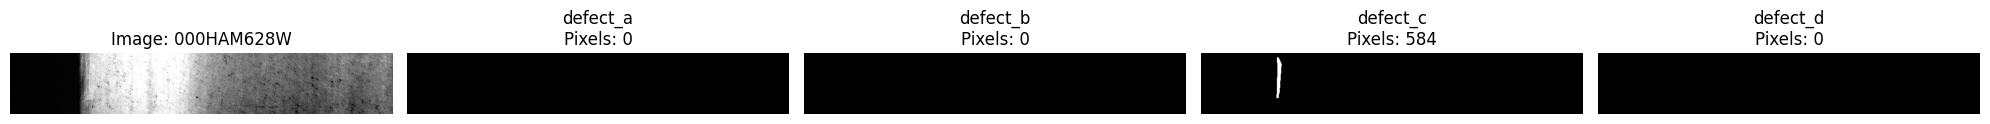

In [36]:

# Step 6 — Visually inspect image and decoded masks

sample_image, sample_mask = train_dataset[0]
image_id = str(train_df.iloc[0]["image_id"])

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

axes[0].imshow(sample_image.squeeze(0).numpy(), cmap="gray")
axes[0].set_title(f"Image: {image_id}")

for i, class_name in enumerate(CLASSES):
    axes[i + 1].imshow(
        sample_mask[i].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i + 1].set_title(
        f"{class_name}\nPixels: {int(sample_mask[i].sum())}"
    )

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


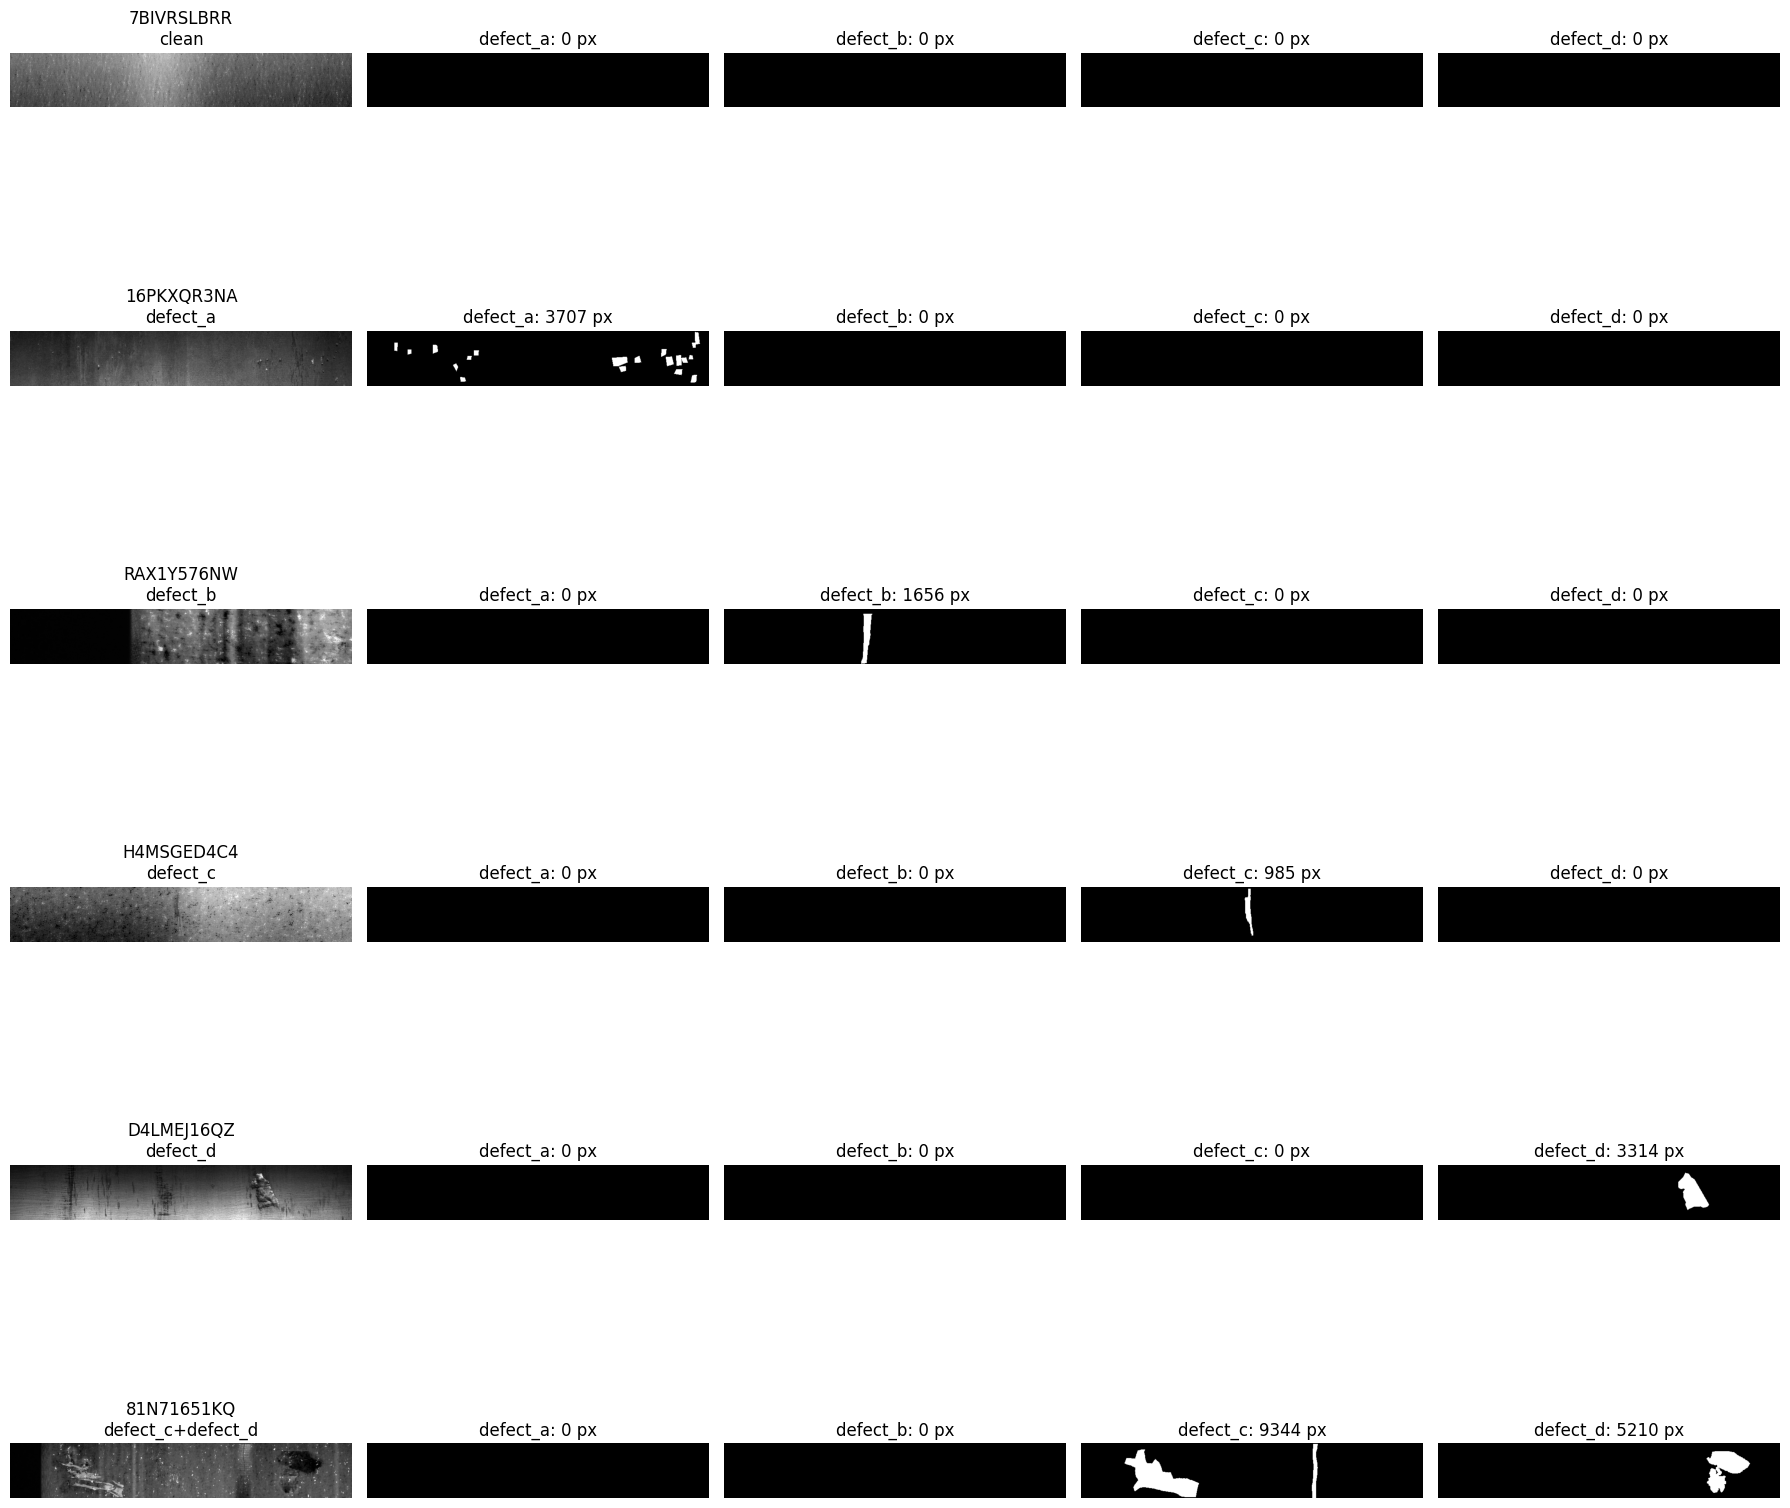

In [37]:

# Step 7 — Inspect different label combinations

import random

random.seed(SEED)

sample_indices = []

# Include a clean image and examples of different defect combinations
for combo in [
    "clean",
    "defect_a",
    "defect_b",
    "defect_c",
    "defect_d",
    "defect_c+defect_d",
]:
    candidates = train_df.index[
        train_df["label_combo"] == combo
    ].tolist()

    if candidates:
        sample_indices.append(random.choice(candidates))

fig, axes = plt.subplots(
    len(sample_indices), 5,
    figsize=(18, 3 * len(sample_indices)),
    squeeze=False
)

for row_idx, df_idx in enumerate(sample_indices):
    image_id = str(train_df.loc[df_idx, "image_id"])
    image_tensor, mask_tensor = train_dataset[
        train_df.index.get_loc(df_idx)
    ]

    axes[row_idx, 0].imshow(
        image_tensor.squeeze(0).numpy(), cmap="gray"
    )
    axes[row_idx, 0].set_title(
        f"{image_id}\n{train_df.loc[df_idx, 'label_combo']}"
    )

    for class_idx, class_name in enumerate(CLASSES):
        axes[row_idx, class_idx + 1].imshow(
            mask_tensor[class_idx].numpy(),
            cmap="gray",
            vmin=0,
            vmax=1,
        )
        axes[row_idx, class_idx + 1].set_title(
            f"{class_name}: {int(mask_tensor[class_idx].sum())} px"
        )

    for ax in axes[row_idx]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [38]:

# Step 8 — Create DataLoaders (V4)

from torch.utils.data import DataLoader, WeightedRandomSampler

BATCH_SIZE = 8
NUM_WORKERS = 2

# Count how many training images contain each defect class
class_image_counts = np.zeros(len(CLASSES), dtype=np.int64)

for image_id in train_df["image_id"].astype(str):
    mask = mask_lookup[image_id]
    present = (mask > 0.5).any(axis=(1, 2))
    class_image_counts += present.astype(np.int64)

print("Training images containing each class:")
for class_name, count in zip(CLASSES, class_image_counts):
    print(f"{class_name}: {count}")

# Calculate a conservative weight for each training image.
# Rare classes get a higher weight, capped at 3x.
sample_weights = []

for image_id in train_df["image_id"].astype(str):
    mask = mask_lookup[image_id]
    present_classes = np.where(
        (mask > 0.5).any(axis=(1, 2))
    )[0]

    if len(present_classes) == 0:
        weight = 1.0  # Clean image
    else:
        class_weights = [
            min(
                3.0,
                np.sqrt(
                    len(train_df) /
                    max(int(class_image_counts[c]), 1)
                )
            )
            for c in present_classes
        ]

        # Use the strongest represented class weight,
        # rather than adding weights for multi-defect images.
        weight = max(class_weights)

    sample_weights.append(weight)

sample_weights = torch.as_tensor(
    sample_weights,
    dtype=torch.double
)

assert len(sample_weights) == len(train_dataset)
assert torch.isfinite(sample_weights).all()
assert (sample_weights > 0).all()

train_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_dataset),
    replacement=True
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=train_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# Test one batch without training
images, masks = next(iter(train_loader))

print("Batch images:", images.shape)
print("Batch masks:", masks.shape)
print("Device:", DEVICE)
print("GPU available:", torch.cuda.is_available())

assert images.shape[1:] == (1, HEIGHT, WIDTH)
assert masks.shape[1:] == (len(CLASSES), HEIGHT, WIDTH)
assert torch.isfinite(images).all()
assert torch.isfinite(masks).all()

del images, masks

print("V4 DataLoader checks passed.")


Training images containing each class:
defect_a: 865
defect_b: 250
defect_c: 3280
defect_d: 1365
Training batches: 1140
Validation batches: 285
Batch images: torch.Size([8, 1, 128, 800])
Batch masks: torch.Size([8, 4, 128, 800])
Device: cuda
GPU available: True
V4 DataLoader checks passed.


In [39]:

# Step 9 — Create the segmentation model

model = smp.Unet(
    encoder_name=ENCODER,
    encoder_weights=ENCODER_WEIGHTS,
    in_channels=1,
    classes=len(CLASSES),
    activation=None,
)

model = model.to(DEVICE)

# Binary segmentation loss for four independent defect classes
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4,
)

print("Model:", ENCODER, "U-Net")
print("Output classes:", len(CLASSES))
print("Device:", next(model.parameters()).device)
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Model: resnet34 U-Net
Output classes: 4
Device: cuda:0
Parameters: 24,430,532


In [40]:

# Step 10 — Training loop with validation and best checkpoint saving

import time
from tqdm.auto import tqdm

EPOCHS = 5
best_val_dice = -1.0
history = []

checkpoint_path = OUTPUT_DIR / "best.pt"

# Mixed precision for faster GPU training
scaler = torch.amp.GradScaler("cuda")

def dice_per_class_from_logits(logits, targets, threshold=0.5, eps=1e-7):
    probs = torch.sigmoid(logits)
    preds = (probs >= threshold).float()

    intersection = (preds * targets).sum(dim=(0, 2, 3))
    denominator = preds.sum(dim=(0, 2, 3)) + targets.sum(dim=(0, 2, 3))

    return (2 * intersection + eps) / (denominator + eps)


for epoch in range(1, EPOCHS + 1):
    start_time = time.time()

    # Training
    model.train()
    train_loss_sum = 0.0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} - train")

    for images, masks in train_bar:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)
            loss = criterion(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss_sum += loss.item()
        train_bar.set_postfix(loss=f"{loss.item():.4f}")

    avg_train_loss = train_loss_sum / len(train_loader)

    # Validation
    model.eval()
    val_loss_sum = 0.0
    dice_sum = torch.zeros(len(CLASSES), device=DEVICE)

    with torch.no_grad():
        for images, masks in tqdm(
            val_loader, desc=f"Epoch {epoch}/{EPOCHS} - val"
        ):
            images = images.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(images)
                loss = criterion(logits, masks)

            val_loss_sum += loss.item()
            dice_sum += dice_per_class_from_logits(
                logits.float(), masks, threshold=0.5
            )

    avg_val_loss = val_loss_sum / len(val_loader)
    class_dice = (dice_sum / len(val_loader)).cpu().numpy()
    mean_dice = float(class_dice.mean())

    epoch_info = {
        "epoch": epoch,
        "train_loss": avg_train_loss,
        "val_loss": avg_val_loss,
        "mean_dice": mean_dice,
    }
    history.append(epoch_info)

    print(f"\nEpoch {epoch}/{EPOCHS}")
    print(f"Train loss: {avg_train_loss:.5f}")
    print(f"Validation loss: {avg_val_loss:.5f}")
    print(f"Mean class Dice @ 0.5: {mean_dice:.5f}")

    for class_name, score in zip(CLASSES, class_dice):
        print(f"  {class_name}: {score:.5f}")

    if mean_dice > best_val_dice:
        best_val_dice = mean_dice
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "epoch": epoch,
                "mean_dice": mean_dice,
                "classes": CLASSES,
                "height": HEIGHT,
                "width": WIDTH,
                "encoder": ENCODER,
            },
            checkpoint_path,
        )
        print("Saved best checkpoint:", checkpoint_path)

    print(f"Epoch time: {(time.time() - start_time) / 60:.1f} minutes")

print("\nTraining finished.")
print("Best validation mean Dice:", best_val_dice)
print("Checkpoint exists:", checkpoint_path.exists())


Epoch 1/5 - train:   0%|          | 0/1140 [00:00<?, ?it/s]

Epoch 1/5 - val:   0%|          | 0/285 [00:00<?, ?it/s]


Epoch 1/5
Train loss: 0.19135
Validation loss: 0.04271
Mean class Dice @ 0.5: 0.46159
  defect_a: 0.44211
  defect_b: 0.78947
  defect_c: 0.35836
  defect_d: 0.25641
Saved best checkpoint: /kaggle/working/surfaceguard_training/best.pt
Epoch time: 2.3 minutes


Epoch 2/5 - train:   0%|          | 0/1140 [00:00<?, ?it/s]

Epoch 2/5 - val:   0%|          | 0/285 [00:00<?, ?it/s]


Epoch 2/5
Train loss: 0.03584
Validation loss: 0.02170
Mean class Dice @ 0.5: 0.54159
  defect_a: 0.44211
  defect_b: 0.78947
  defect_c: 0.41143
  defect_d: 0.52335
Saved best checkpoint: /kaggle/working/surfaceguard_training/best.pt
Epoch time: 2.3 minutes


... (5 outputs left out)


Epoch 4/5
Train loss: 0.02219
Validation loss: 0.01552
Mean class Dice @ 0.5: 0.57588
  defect_a: 0.44211
  defect_b: 0.78947
  defect_c: 0.48541
  defect_d: 0.58651
Saved best checkpoint: /kaggle/working/surfaceguard_training/best.pt
Epoch time: 2.3 minutes


Epoch 5/5 - train:   0%|          | 0/1140 [00:00<?, ?it/s]

Epoch 5/5 - val:   0%|          | 0/285 [00:00<?, ?it/s]


Epoch 5/5
Train loss: 0.02026
Validation loss: 0.01502
Mean class Dice @ 0.5: 0.58318
  defect_a: 0.44211
  defect_b: 0.78947
  defect_c: 0.47850
  defect_d: 0.62264
Saved best checkpoint: /kaggle/working/surfaceguard_training/best.pt
Epoch time: 2.3 minutes

Training finished.
Best validation mean Dice: 0.5831784605979919
Checkpoint exists: True


In [41]:

# Step 11 — Restore the best validation checkpoint

checkpoint = torch.load(
    OUTPUT_DIR / "best.pt",
    map_location=DEVICE,
    weights_only=False,
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best checkpoint epoch:", checkpoint["epoch"])
print("Saved validation Dice:", checkpoint["mean_dice"])
print("Model device:", next(model.parameters()).device)


Best checkpoint epoch: 5
Saved validation Dice: 0.5831784605979919
Model device: cuda:0


In [42]:

# Step 12 — Threshold sweep on validation data

thresholds = THRESHOLDS

num_classes = len(CLASSES)
intersections = torch.zeros(
    len(thresholds), num_classes, dtype=torch.float64
)
unions = torch.zeros_like(intersections)

model.eval()

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Threshold sweep"):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)

        probs = torch.sigmoid(logits.float())
        targets = masks.bool()

        for ti, threshold in enumerate(thresholds):
            preds = probs >= threshold

            intersection = (preds & targets).sum(dim=(0, 2, 3))
            union = (preds | targets).sum(dim=(0, 2, 3))

            intersections[ti] += intersection.cpu().double()
            unions[ti] += union.cpu().double()

# Avoid division by zero for classes with no positive pixels
ious = intersections / unions.clamp_min(1)

print("Validation IoU by threshold:")
for ti, threshold in enumerate(thresholds):
    print(f"{threshold:.2f}: mean IoU = {ious[ti].mean().item():.5f}")

best_indices = ious.argmax(dim=0)
best_thresholds = [
    thresholds[idx.item()] for idx in best_indices
]

print("\nBest threshold per class:")
for i, class_name in enumerate(CLASSES):
    print(
        f"{class_name}: threshold={best_thresholds[i]:.2f}, "
        f"IoU={ious[best_indices[i], i].item():.5f}"
    )

print("\nMean IoU using per-class best thresholds:")
print(
    ious[best_indices, torch.arange(num_classes)].mean().item()
)


Threshold sweep:   0%|          | 0/285 [00:00<?, ?it/s]

Validation IoU by threshold:
0.10: mean IoU = 0.24317
0.15: mean IoU = 0.24988
0.20: mean IoU = 0.24938
0.25: mean IoU = 0.25091
0.30: mean IoU = 0.25227
0.35: mean IoU = 0.25129
0.40: mean IoU = 0.24867
0.45: mean IoU = 0.24363
0.50: mean IoU = 0.23695
0.55: mean IoU = 0.22869
0.60: mean IoU = 0.21872
0.65: mean IoU = 0.20688
0.70: mean IoU = 0.19311
0.75: mean IoU = 0.17650
0.80: mean IoU = 0.15504
0.85: mean IoU = 0.12479
0.90: mean IoU = 0.08242

Best threshold per class:
defect_a: threshold=0.10, IoU=0.09608
defect_b: threshold=0.10, IoU=0.00420
defect_c: threshold=0.40, IoU=0.44634
defect_d: threshold=0.25, IoU=0.57057

Mean IoU using per-class best thresholds:
0.27929575841230725


In [43]:

# Step 13 — Inspect test and submission files

print("Files in competition data directory:")
for path in sorted(DATA_ROOT.iterdir()):
    print(path.name, "(directory)" if path.is_dir() else "")

test_csv_path = DATA_ROOT / "test.csv"

if test_csv_path.exists():
    test_df = pd.read_csv(test_csv_path, dtype=str, keep_default_na=False)
    print("\nTest CSV shape:", test_df.shape)
    print("Test columns:", test_df.columns.tolist())
    display(test_df.head())
else:
    print("\nNo test.csv at DATA_ROOT.")

# Find any sample submission file
for path in DATA_ROOT.rglob("*submission*.csv"):
    print("Submission template:", path)


Files in competition data directory:
sample_submission.csv 
test (directory)
train (directory)
train.csv 

No test.csv at DATA_ROOT.
Submission template: /kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv


In [44]:

# Step 14 — Inspect submission format and test images

sample_submission = pd.read_csv(
    DATA_ROOT / "sample_submission.csv",
    dtype=str,
    keep_default_na=False
)

print("Submission template shape:", sample_submission.shape)
print("Submission columns:", sample_submission.columns.tolist())
display(sample_submission.head())

test_dir = DATA_ROOT / "test"
test_files = sorted(test_dir.glob("*"))

print("\nTest image files:", len(test_files))
print("First 5 test filenames:", [p.name for p in test_files[:5]])

print("\nTemplate rows:", len(sample_submission))
print("Null values:", sample_submission.isna().sum().to_dict())


Submission template shape: (12000, 4)
Submission columns: ['ID', 'image_id', 'defect_type', 'mask_rle']


,ID,image_id,defect_type,mask_rle
0,1,WAFNKCRR7Q,defect_a,
1,2,WAFNKCRR7Q,defect_b,
2,3,WAFNKCRR7Q,defect_c,
3,4,WAFNKCRR7Q,defect_d,
4,5,YZXKEWSUDD,defect_a,



Test image files: 3000
First 5 test filenames: ['00755AT0HO.jpg', '00JDJCJDID.jpg', '013R8BTZDO.jpg', '01FR6RG5CM.jpg', '02BG8UIHZU.jpg']

Template rows: 12000
Null values: {'ID': 0, 'image_id': 0, 'defect_type': 0, 'mask_rle': 0}


In [45]:

# Step 15 — Calculate global per-class validation Dice

model.eval()

tp = torch.zeros(len(CLASSES), dtype=torch.float64)
fp = torch.zeros_like(tp)
fn = torch.zeros_like(tp)

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Global Dice evaluation"):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)

        probs = torch.sigmoid(logits.float())
        preds = probs >= 0.5
        targets = masks >= 0.5

        tp += (preds & targets).sum(dim=(0, 2, 3)).cpu().double()
        fp += (preds & ~targets).sum(dim=(0, 2, 3)).cpu().double()
        fn += (~preds & targets).sum(dim=(0, 2, 3)).cpu().double()

global_dice = (2 * tp) / (2 * tp + fp + fn).clamp_min(1)

print("Global validation Dice @ threshold 0.5:")
for name, score in zip(CLASSES, global_dice.tolist()):
    print(f"{name}: {score:.5f}")

print("Global mean Dice:", global_dice.mean().item())


Global Dice evaluation:   0%|          | 0/285 [00:00<?, ?it/s]

Global validation Dice @ threshold 0.5:
defect_a: 0.00000
defect_b: 0.00000
defect_c: 0.60783
defect_d: 0.67654
Global mean Dice: 0.32109320661394136


In [46]:

# Step 16 — Diagnose class-wise prediction confidence

model.eval()

target_pixels = torch.zeros(len(CLASSES), dtype=torch.float64)
predicted_pixels = {
    t: torch.zeros(len(CLASSES), dtype=torch.float64)
    for t in [0.10, 0.20, 0.30, 0.50]
}
max_probability = torch.zeros(len(CLASSES), dtype=torch.float64)
probability_sum = torch.zeros(len(CLASSES), dtype=torch.float64)
total_pixels = 0

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Diagnosing classes"):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)

        probs = torch.sigmoid(logits.float())

        target_pixels += masks.sum(dim=(0, 2, 3)).cpu().double()
        probability_sum += probs.sum(dim=(0, 2, 3)).cpu().double()
        max_probability = torch.maximum(
            max_probability,
            probs.amax(dim=(0, 2, 3)).cpu().double()
        )

        total_pixels += masks.shape[0] * masks.shape[2] * masks.shape[3]

        for threshold in predicted_pixels:
            predicted_pixels[threshold] += (
                (probs >= threshold).sum(dim=(0, 2, 3)).cpu().double()
            )

print("\nClass-wise pixel diagnosis")
for i, name in enumerate(CLASSES):
    print(f"\n{name}")
    print("  Ground-truth positive pixels:", int(target_pixels[i]))
    print("  Mean predicted probability:", round(
        (probability_sum[i] / total_pixels).item(), 6
    ))
    print("  Maximum predicted probability:", round(
        max_probability[i].item(), 6
    ))

    for threshold, counts in predicted_pixels.items():
        print(
            f"  Predicted pixels at {threshold:.2f}:",
            int(counts[i])
        )


Diagnosing classes:   0%|          | 0/285 [00:00<?, ?it/s]


Class-wise pixel diagnosis

defect_a
  Ground-truth positive pixels: 143242
  Mean predicted probability: 0.001244
  Maximum predicted probability: 0.291586
  Predicted pixels at 0.10: 252194
  Predicted pixels at 0.20: 12924
  Predicted pixels at 0.30: 0
  Predicted pixels at 0.50: 0

defect_b
  Ground-truth positive pixels: 42470
  Mean predicted probability: 0.000494
  Maximum predicted probability: 0.163713
  Predicted pixels at 0.10: 4420
  Predicted pixels at 0.20: 0
  Predicted pixels at 0.30: 0
  Predicted pixels at 0.50: 0

defect_c
  Ground-truth positive pixels: 4466807
  Mean predicted probability: 0.020472
  Maximum predicted probability: 0.995226
  Predicted pixels at 0.10: 9546538
  Predicted pixels at 0.20: 6812698
  Predicted pixels at 0.30: 5360217
  Predicted pixels at 0.50: 3447545

defect_d
  Ground-truth positive pixels: 2527458
  Mean predicted probability: 0.00935
  Maximum predicted probability: 0.989948
  Predicted pixels at 0.10: 3547112
  Predicted pixels a

In [47]:

# Step 17 — Improved model with BCE + Dice loss

import segmentation_models_pytorch as smp
import torch
import torch.nn as nn
from tqdm.auto import tqdm

model_v2 = smp.Unet(
    encoder_name=ENCODER,
    encoder_weights="imagenet",
    in_channels=1,
    classes=len(CLASSES),
    activation=None
).to(DEVICE)

bce_loss = nn.BCEWithLogitsLoss()
dice_loss = smp.losses.DiceLoss(mode="multilabel", from_logits=True)

optimizer_v2 = torch.optim.AdamW(
    model_v2.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scaler_v2 = torch.amp.GradScaler("cuda")

BEST_V2_PATH = OUTPUT_DIR / "best_v2.pt"
EPOCHS_V2 = 8

print("New model ready")
print("Device:", DEVICE)
print("Loss: BCE + Dice")
print("Checkpoint:", BEST_V2_PATH)


New model ready
Device: cuda
Loss: BCE + Dice
Checkpoint: /kaggle/working/surfaceguard_training/best_v2.pt


In [48]:

# Step 18 — Train model v2

best_v2_dice = -1.0
history_v2 = []

for epoch in range(1, EPOCHS_V2 + 1):
    model_v2.train()
    train_loss_sum = 0.0
    train_batches = 0

    for images, masks in tqdm(
        train_loader, desc=f"Epoch {epoch}/{EPOCHS_V2} - train"
    ):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        optimizer_v2.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model_v2(images)
            loss = 0.5 * bce_loss(logits, masks) + 0.5 * dice_loss(logits, masks)

        scaler_v2.scale(loss).backward()
        scaler_v2.step(optimizer_v2)
        scaler_v2.update()

        train_loss_sum += loss.item()
        train_batches += 1

    model_v2.eval()
    val_loss_sum = 0.0
    val_batches = 0

    tp = torch.zeros(len(CLASSES), dtype=torch.float64)
    fp = torch.zeros_like(tp)
    fn = torch.zeros_like(tp)

    with torch.no_grad():
        for images, masks in tqdm(
            val_loader, desc=f"Epoch {epoch}/{EPOCHS_V2} - val"
        ):
            images = images.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model_v2(images)
                loss = 0.5 * bce_loss(logits, masks) + 0.5 * dice_loss(logits, masks)

            val_loss_sum += loss.item()
            val_batches += 1

            probs = torch.sigmoid(logits.float())
            preds = probs >= 0.5
            targets = masks >= 0.5

            tp += (preds & targets).sum(dim=(0, 2, 3)).cpu().double()
            fp += (preds & ~targets).sum(dim=(0, 2, 3)).cpu().double()
            fn += (~preds & targets).sum(dim=(0, 2, 3)).cpu().double()

    class_dice = (2 * tp) / (2 * tp + fp + fn).clamp_min(1)
    mean_dice = class_dice.mean().item()

    train_loss = train_loss_sum / train_batches
    val_loss = val_loss_sum / val_batches

    history_v2.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "mean_dice": mean_dice
    })

    print(f"\nEpoch {epoch}")
    print(f"Train loss: {train_loss:.5f}")
    print(f"Val loss:   {val_loss:.5f}")
    for i, name in enumerate(CLASSES):
        print(f"{name} Dice: {class_dice[i].item():.5f}")
    print(f"Global mean Dice: {mean_dice:.5f}")

    if mean_dice > best_v2_dice:
        best_v2_dice = mean_dice
        torch.save({
            "model_state_dict": model_v2.state_dict(),
            "optimizer_state_dict": optimizer_v2.state_dict(),
            "epoch": epoch,
            "mean_dice": mean_dice,
            "classes": CLASSES,
            "height": HEIGHT,
            "width": WIDTH,
            "encoder": ENCODER
        }, BEST_V2_PATH)
        print("Saved new best model v2")

print("\nTraining complete.")
print("Best v2 mean Dice:", round(best_v2_dice, 5))
print("Checkpoint exists:", BEST_V2_PATH.exists())


Epoch 1/8 - train:   0%|          | 0/1140 [00:00<?, ?it/s]

Epoch 1/8 - val:   0%|          | 0/285 [00:00<?, ?it/s]


Epoch 1
Train loss: 0.38477
Val loss:   0.24711
defect_a Dice: 0.00000
defect_b Dice: 0.00000
defect_c Dice: 0.55575
defect_d Dice: 0.36135
Global mean Dice: 0.22927
Saved new best model v2


Epoch 2/8 - train:   0%|          | 0/1140 [00:00<?, ?it/s]

Epoch 2/8 - val:   0%|          | 0/285 [00:00<?, ?it/s]


Epoch 2
Train loss: 0.28186
Val loss:   0.21156
defect_a Dice: 0.00000
defect_b Dice: 0.00000
defect_c Dice: 0.55605
defect_d Dice: 0.62027
Global mean Dice: 0.29408
Saved new best model v2


... (15 outputs left out)


Epoch 7
Train loss: 0.21379
Val loss:   0.18069
defect_a Dice: 0.29864
defect_b Dice: 0.17120
defect_c Dice: 0.60538
defect_d Dice: 0.67690
Global mean Dice: 0.43803
Saved new best model v2


Epoch 8/8 - train:   0%|          | 0/1140 [00:00<?, ?it/s]

Epoch 8/8 - val:   0%|          | 0/285 [00:00<?, ?it/s]


Epoch 8
Train loss: 0.20900
Val loss:   0.17400
defect_a Dice: 0.36077
defect_b Dice: 0.14992
defect_c Dice: 0.61829
defect_d Dice: 0.68951
Global mean Dice: 0.45462
Saved new best model v2

Training complete.
Best v2 mean Dice: 0.45462
Checkpoint exists: True


In [49]:

# Step 20 — Threshold tuning for the improved model

checkpoint_v2 = torch.load(
    BEST_V2_PATH, map_location=DEVICE, weights_only=False
)
model_v2.load_state_dict(checkpoint_v2["model_state_dict"])
model_v2.eval()

print("Loaded best v2 checkpoint, epoch:", checkpoint_v2["epoch"])
print("Saved validation Dice:", round(checkpoint_v2["mean_dice"], 5))

thresholds_v2 = [0.02, 0.05, 0.08, 0.10, 0.12, 0.15,
                 0.20, 0.25, 0.30, 0.40, 0.50]

# Store global TP, FP and FN for each threshold and class
stats = {
    t: {
        "tp": torch.zeros(len(CLASSES), dtype=torch.float64),
        "fp": torch.zeros(len(CLASSES), dtype=torch.float64),
        "fn": torch.zeros(len(CLASSES), dtype=torch.float64)
    }
    for t in thresholds_v2
}

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Threshold sweep v2"):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model_v2(images)

        probs = torch.sigmoid(logits.float())
        targets = masks >= 0.5

        for t in thresholds_v2:
            preds = probs >= t
            stats[t]["tp"] += (
                (preds & targets).sum(dim=(0, 2, 3)).cpu().double()
            )
            stats[t]["fp"] += (
                (preds & ~targets).sum(dim=(0, 2, 3)).cpu().double()
            )
            stats[t]["fn"] += (
                (~preds & targets).sum(dim=(0, 2, 3)).cpu().double()
            )

rows = []
for t in thresholds_v2:
    tp = stats[t]["tp"]
    fp = stats[t]["fp"]
    fn = stats[t]["fn"]

    dice = (2 * tp) / (2 * tp + fp + fn).clamp_min(1)
    iou = tp / (tp + fp + fn).clamp_min(1)

    row = {
        "threshold": t,
        "mean_dice": dice.mean().item(),
        "mean_iou": iou.mean().item()
    }
    for i, name in enumerate(CLASSES):
        row[f"{name}_dice"] = dice[i].item()
        row[f"{name}_iou"] = iou[i].item()

    rows.append(row)

threshold_results_v2 = pd.DataFrame(rows)
display(threshold_results_v2.round(4))

print("\nBest threshold by class (global validation Dice):")
for name in CLASSES:
    best_idx = threshold_results_v2[f"{name}_dice"].idxmax()
    best_row = threshold_results_v2.loc[best_idx]
    print(
        f"{name}: threshold={best_row['threshold']:.2f}, "
        f"Dice={best_row[f'{name}_dice']:.4f}, "
        f"IoU={best_row[f'{name}_iou']:.4f}"
    )


Loaded best v2 checkpoint, epoch: 8
Saved validation Dice: 0.45462


Threshold sweep v2:   0%|          | 0/285 [00:00<?, ?it/s]

,threshold,mean_dice,mean_iou,defect_a_dice,defect_a_iou,defect_b_dice,defect_b_iou,defect_c_dice,defect_c_iou,defect_d_dice,defect_d_iou
0,0.02,0.4156,0.2884,0.3053,0.1801,0.0942,0.0494,0.6014,0.4300,0.6615,0.4942
1,0.05,0.4319,0.3022,0.3256,0.1945,0.1097,0.0581,0.6163,0.4454,0.6761,0.5107
2,0.08,0.4374,0.3064,0.3343,0.2007,0.1166,0.0619,0.6185,0.4477,0.6801,0.5152
3,0.10,0.4397,0.3082,0.3382,0.2035,0.1198,0.0637,0.6193,0.4485,0.6816,0.5170
4,0.12,0.4415,0.3095,0.3411,0.2056,0.1225,0.0652,0.6196,0.4489,0.6828,0.5184
5,0.15,0.4435,0.3110,0.3440,0.2078,0.1260,0.0672,0.6200,0.4492,0.6841,0.5199
6,0.20,0.4461,0.3129,0.3481,0.2107,0.1307,0.0699,0.6201,0.4493,0.6855,0.5215
7,0.25,0.4481,0.3143,0.3513,0.2130,0.1347,0.0722,0.6199,0.4492,0.6866,0.5227
8,0.30,0.4498,0.3155,0.3537,0.2149,0.1383,0.0743,0.6198,0.4490,0.6874,0.5237
9,0.40,0.4525,0.3173,0.3581,0.2181,0.1443,0.0778,0.6192,0.4484,0.6886,0.5251



Best threshold by class (global validation Dice):
defect_a: threshold=0.50, Dice=0.3608, IoU=0.2201
defect_b: threshold=0.50, Dice=0.1499, IoU=0.0810
defect_c: threshold=0.20, Dice=0.6201, IoU=0.4493
defect_d: threshold=0.50, Dice=0.6895, IoU=0.5261


In [50]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

if not all(name in globals() for name in ["model_v2", "val_loader", "CLASSES", "DEVICE", "BEST_V2_PATH", "HEIGHT", "WIDTH"]):
    raise RuntimeError("Run the model setup, training, and validation cells first.")

checkpoint_path = Path(BEST_V2_PATH)
if not checkpoint_path.is_file():
    raise FileNotFoundError(f"Best v2 checkpoint not found: {checkpoint_path}")

checkpoint_v2 = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
model_v2.load_state_dict(checkpoint_v2["model_state_dict"], strict=True)
model_v2.eval()

thresholds = np.array([
    0.005, 0.01, 0.02, 0.03, 0.04, 0.05, 0.075, 0.10,
    0.125, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45,
    0.50, 0.55, 0.60, 0.70, 0.80, 0.90, 0.95
], dtype=np.float32)

num_thresholds = len(thresholds)
num_classes = len(CLASSES)
positive_dice_sum = np.zeros((num_thresholds, num_classes), dtype=np.float64)
empty_false_pixels_sum = np.zeros((num_thresholds, num_classes), dtype=np.float64)
empty_correct_sum = np.zeros((num_thresholds, num_classes), dtype=np.int64)
positive_pair_counts = np.zeros(num_classes, dtype=np.int64)
empty_pair_counts = np.zeros(num_classes, dtype=np.int64)
threshold_tensor = torch.as_tensor(thresholds, device=DEVICE).view(-1, 1, 1, 1, 1)

with torch.inference_mode():
    for images, masks in tqdm(val_loader, desc="Weighted validation threshold sweep"):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            logits = model_v2(images)
        probabilities = torch.sigmoid(logits.float())
        targets = masks >= 0.5
        target_counts = targets.sum(dim=(-2, -1))
        positive = target_counts > 0
        empty = ~positive
        positive_pair_counts += positive.sum(dim=0).cpu().numpy()
        empty_pair_counts += empty.sum(dim=0).cpu().numpy()
        predictions = probabilities.unsqueeze(0) >= threshold_tensor
        predicted_counts = predictions.sum(dim=(-2, -1))
        intersections = (predictions & targets.unsqueeze(0)).sum(dim=(-2, -1))
        pair_dice = 2.0 * intersections.float() / (predicted_counts + target_counts.unsqueeze(0)).clamp_min(1)
        positive_dice_sum += (pair_dice * positive.unsqueeze(0)).sum(dim=1).cpu().numpy()
        empty_false_pixels_sum += (predicted_counts * empty.unsqueeze(0)).sum(dim=1).cpu().numpy()
        empty_correct_sum += ((predicted_counts == 0) & empty.unsqueeze(0)).sum(dim=1).cpu().numpy()

total_positive_pairs = int(positive_pair_counts.sum())
total_empty_pairs = int(empty_pair_counts.sum())
pixels_per_pair = int(HEIGHT * WIDTH)
if total_positive_pairs == 0 or total_empty_pairs == 0:
    raise RuntimeError("Validation split must contain both positive and empty image-class pairs.")

common_foreground_dice = positive_dice_sum.sum(axis=1) / total_positive_pairs
common_fp_fraction = empty_false_pixels_sum.sum(axis=1) / (total_empty_pairs * pixels_per_pair)
common_fp_score = 1.0 - common_fp_fraction
common_empty_accuracy = empty_correct_sum.sum(axis=1) / total_empty_pairs
common_weighted_score = 0.70 * common_foreground_dice + 0.20 * common_fp_score + 0.10 * common_empty_accuracy

weighted_validation_results = pd.DataFrame({
    "threshold": thresholds,
    "foreground_dice": common_foreground_dice,
    "false_positive_fraction_on_empty_pairs": common_fp_fraction,
    "false_positive_score": common_fp_score,
    "empty_accuracy": common_empty_accuracy,
    "local_weighted_validation_score": common_weighted_score,
})

selected_indices = []
for class_index in range(num_classes):
    class_contribution = (
        0.70 * positive_dice_sum[:, class_index] / total_positive_pairs
        - 0.20 * empty_false_pixels_sum[:, class_index] / (total_empty_pairs * pixels_per_pair)
        + 0.10 * empty_correct_sum[:, class_index] / total_empty_pairs
    )
    selected_indices.append(int(np.argmax(class_contribution)))

CLASS_THRESHOLDS_WEIGHTED = {
    class_name: float(thresholds[selected_indices[class_index]])
    for class_index, class_name in enumerate(CLASSES)
}

selected_foreground_dice = sum(
    positive_dice_sum[selected_indices[c], c] for c in range(num_classes)
) / total_positive_pairs
selected_fp_fraction = sum(
    empty_false_pixels_sum[selected_indices[c], c] for c in range(num_classes)
) / (total_empty_pairs * pixels_per_pair)
selected_fp_score = 1.0 - selected_fp_fraction
selected_empty_accuracy = sum(
    empty_correct_sum[selected_indices[c], c] for c in range(num_classes)
) / total_empty_pairs
selected_weighted_score = (
    0.70 * selected_foreground_dice
    + 0.20 * selected_fp_score
    + 0.10 * selected_empty_accuracy
)

per_class_threshold_results = pd.DataFrame({
    "defect_type": CLASSES,
    "selected_threshold": [CLASS_THRESHOLDS_WEIGHTED[name] for name in CLASSES],
    "positive_validation_pairs": positive_pair_counts,
    "empty_validation_pairs": empty_pair_counts,
})

print("Common-threshold results ranked by local weighted validation score:")
display(weighted_validation_results.sort_values("local_weighted_validation_score", ascending=False).head(10).round(6))
print("\nSelected per-class thresholds:")
display(per_class_threshold_results)
print("\nCombined result using selected per-class thresholds:")
print(f"Foreground chDice: {selected_foreground_dice:.6f}")
print(f"False-positive fraction on empty pairs: {selected_fp_fraction:.8f}")
print(f"False-positive score: {selected_fp_score:.6f}")
print(f"Empty accuracy: {selected_empty_accuracy:.6f}")
print(f"Local weighted validation score: {selected_weighted_score:.6f}")
print("\nThese are local validation calculations using the published component weights, not an official Kaggle score.")

Weighted validation threshold sweep:   0%|          | 0/285 [00:00<?, ?it/s]

Common-threshold results ranked by local weighted validation score:


,threshold,foreground_dice,false_positive_fraction_on_empty_pairs,false_positive_score,empty_accuracy,local_weighted_validation_score
14,0.40,0.468193,0.001205,0.998795,0.843388,0.611833
15,0.45,0.467502,0.001176,0.998824,0.848078,0.611824
13,0.35,0.468661,0.001236,0.998764,0.839218,0.611737
16,0.50,0.466797,0.001149,0.998851,0.851987,0.611727
12,0.30,0.469312,0.001271,0.998729,0.834397,0.611704
17,0.55,0.466146,0.001122,0.998878,0.856156,0.611694
18,0.60,0.465360,0.001094,0.998906,0.860456,0.611579
11,0.25,0.469866,0.001311,0.998689,0.828274,0.611472
10,0.20,0.470567,0.001360,0.998640,0.819805,0.611105
19,0.70,0.463626,0.001036,0.998964,0.866840,0.611015



Selected per-class thresholds:


,defect_type,selected_threshold,positive_validation_pairs,empty_validation_pairs
0,defect_a,0.60,216,2063
1,defect_b,0.95,63,2216
2,defect_c,0.25,820,1459
3,defect_d,0.30,342,1937



Combined result using selected per-class thresholds:
Foreground chDice: 0.468117
False-positive fraction on empty pairs: 0.00109083
False-positive score: 0.998909
Empty accuracy: 0.863844
Local weighted validation score: 0.613848

These are local validation calculations using the published component weights, not an official Kaggle score.


In [51]:
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/surfaceguard_training")

for name in ["best_v2.pt", "best_weighted.pt"]:
    path = OUTPUT_DIR / name
    print(name, "exists:", path.is_file())

best_v2.pt exists: True
best_weighted.pt exists: False


In [52]:
# # Step 20B — Tune thresholds independently for each defect class

# import numpy as np
# import pandas as pd
# import torch
# from tqdm.auto import tqdm

# # Test thresholds on the validation set
# threshold_grid = [
#     0.05, 0.075, 0.10, 0.125, 0.15, 0.20,
#     0.25, 0.30, 0.35, 0.40, 0.45, 0.50,
#     0.55, 0.60, 0.70, 0.80
# ]

# num_classes = len(CLASSES)
# tp = torch.zeros(len(threshold_grid), num_classes, dtype=torch.float64)
# fp = torch.zeros_like(tp)
# fn = torch.zeros_like(tp)

# model_v2.eval()

# with torch.inference_mode():
#     for images, masks in tqdm(val_loader, desc="Tuning thresholds"):
#         images = images.to(DEVICE, non_blocking=True)
#         masks = masks.to(DEVICE, non_blocking=True)

#         with torch.autocast(
#             device_type=DEVICE.type,
#             dtype=torch.float16,
#             enabled=DEVICE.type == "cuda"
#         ):
#             logits = model_v2(images)

#         probabilities = torch.sigmoid(logits.float())
#         targets = masks >= 0.5

#         for i, threshold in enumerate(threshold_grid):
#             predictions = probabilities >= threshold

#             tp[i] += (
#                 predictions & targets
#             ).sum(dim=(0, 2, 3)).cpu().double()

#             fp[i] += (
#                 predictions & ~targets
#             ).sum(dim=(0, 2, 3)).cpu().double()

#             fn[i] += (
#                 ~predictions & targets
#             ).sum(dim=(0, 2, 3)).cpu().double()

# dice_scores = (
#     2 * tp
#     / (2 * tp + fp + fn).clamp_min(1)
# ).numpy()

# results = []

# for class_index, class_name in enumerate(CLASSES):
#     class_scores = dice_scores[:, class_index]
#     best_score = class_scores.max()

#     # If multiple thresholds tie, choose the highest
#     # to avoid unnecessary false-positive predictions.
#     best_indices = np.where(
#         np.isclose(class_scores, best_score)
#     )[0]
#     best_index = best_indices[-1]

#     results.append({
#         "defect_type": class_name,
#         "best_threshold": threshold_grid[best_index],
#         "validation_dice": round(float(best_score), 5),
#         "predicted_pixels": int(
#             tp[best_index, class_index]
#             + fp[best_index, class_index]
#         )
#     })

# threshold_results = pd.DataFrame(results)

# CLASS_THRESHOLDS_TUNED = dict(zip(
#     threshold_results["defect_type"],
#     threshold_results["best_threshold"]
# ))

# print("Validation-selected thresholds:")
# display(threshold_results)

# print("Use these thresholds for the new candidate:")
# print(CLASS_THRESHOLDS_TUNED)

In [53]:
# Step 20B — Weighted validation threshold sweep and per-class selection

from pathlib import Path
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

if not all(name in globals() for name in [
    "model_v2", "val_loader", "CLASSES", "DEVICE",
    "BEST_V2_PATH", "HEIGHT", "WIDTH"
]):
    raise RuntimeError("Run the model setup, training, and validation cells first.")

checkpoint_path = Path(BEST_V2_PATH)
if not checkpoint_path.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")

checkpoint_v2 = torch.load(
    checkpoint_path, map_location=DEVICE, weights_only=False
)
model_v2.load_state_dict(checkpoint_v2["model_state_dict"], strict=True)
model_v2.eval()

thresholds = np.array([
    0.005, 0.01, 0.02, 0.03, 0.04, 0.05, 0.075, 0.10,
    0.125, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45,
    0.50, 0.55, 0.60, 0.70, 0.80, 0.90, 0.95
], dtype=np.float32)

num_thresholds = len(thresholds)
num_classes = len(CLASSES)

positive_dice_sum = np.zeros((num_thresholds, num_classes), dtype=np.float64)
empty_false_pixels_sum = np.zeros((num_thresholds, num_classes), dtype=np.float64)
empty_correct_sum = np.zeros((num_thresholds, num_classes), dtype=np.int64)
positive_pair_counts = np.zeros(num_classes, dtype=np.int64)
empty_pair_counts = np.zeros(num_classes, dtype=np.int64)

threshold_tensor = torch.as_tensor(
    thresholds, device=DEVICE
).view(-1, 1, 1, 1, 1)

with torch.inference_mode():
    for images, masks in tqdm(val_loader, desc="Threshold sweep"):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=DEVICE.type == "cuda"
        ):
            logits = model_v2(images)

        probabilities = torch.sigmoid(logits.float())
        targets = masks >= 0.5

        target_counts = targets.sum(dim=(-2, -1))
        positive = target_counts > 0
        empty = ~positive

        positive_pair_counts += positive.sum(dim=0).cpu().numpy()
        empty_pair_counts += empty.sum(dim=0).cpu().numpy()

        predictions = probabilities.unsqueeze(0) >= threshold_tensor
        predicted_counts = predictions.sum(dim=(-2, -1))
        intersections = (
            predictions & targets.unsqueeze(0)
        ).sum(dim=(-2, -1))

        pair_dice = (
            2.0 * intersections.float()
            / (predicted_counts + target_counts.unsqueeze(0)).clamp_min(1)
        )

        positive_dice_sum += (
            pair_dice * positive.unsqueeze(0)
        ).sum(dim=1).cpu().numpy()

        empty_false_pixels_sum += (
            predicted_counts * empty.unsqueeze(0)
        ).sum(dim=1).cpu().numpy()

        empty_correct_sum += (
            (predicted_counts == 0) & empty.unsqueeze(0)
        ).sum(dim=1).cpu().numpy()

total_positive_pairs = int(positive_pair_counts.sum())
total_empty_pairs = int(empty_pair_counts.sum())
pixels_per_pair = int(HEIGHT * WIDTH)

if total_positive_pairs == 0 or total_empty_pairs == 0:
    raise RuntimeError("Validation needs both positive and empty image-class pairs.")

# Compare a single threshold applied to all classes.
common_foreground_dice = positive_dice_sum.sum(axis=1) / total_positive_pairs
common_fp_fraction = (
    empty_false_pixels_sum.sum(axis=1)
    / (total_empty_pairs * pixels_per_pair)
)
common_fp_score = 1.0 - common_fp_fraction
common_empty_accuracy = empty_correct_sum.sum(axis=1) / total_empty_pairs

common_weighted_score = (
    0.70 * common_foreground_dice
    + 0.20 * common_fp_score
    + 0.10 * common_empty_accuracy
)

weighted_validation_results = pd.DataFrame({
    "threshold": thresholds,
    "foreground_dice": common_foreground_dice,
    "false_positive_fraction_on_empty_pairs": common_fp_fraction,
    "false_positive_score": common_fp_score,
    "empty_accuracy": common_empty_accuracy,
    "local_weighted_validation_score": common_weighted_score
})

# Choose a threshold independently for each class.
# These component weights are a local proxy, not the official Kaggle metric.
selected_indices = []

for class_index in range(num_classes):
    class_contribution = (
        0.70 * positive_dice_sum[:, class_index] / total_positive_pairs
        - 0.20 * empty_false_pixels_sum[:, class_index]
          / (total_empty_pairs * pixels_per_pair)
        + 0.10 * empty_correct_sum[:, class_index] / total_empty_pairs
    )
    selected_indices.append(int(np.argmax(class_contribution)))

CLASS_THRESHOLDS_TUNED = {
    class_name: float(thresholds[selected_indices[i]])
    for i, class_name in enumerate(CLASSES)
}

per_class_threshold_results = pd.DataFrame({
    "defect_type": CLASSES,
    "selected_threshold": [
        CLASS_THRESHOLDS_TUNED[name] for name in CLASSES
    ],
    "positive_validation_pairs": positive_pair_counts,
    "empty_validation_pairs": empty_pair_counts,
    "positive_pair_dice": [
        positive_dice_sum[selected_indices[i], i]
        / max(positive_pair_counts[i], 1)
        for i in range(num_classes)
    ]
})

selected_foreground_dice = sum(
    positive_dice_sum[selected_indices[i], i]
    for i in range(num_classes)
) / total_positive_pairs

selected_fp_fraction = sum(
    empty_false_pixels_sum[selected_indices[i], i]
    for i in range(num_classes)
) / (total_empty_pairs * pixels_per_pair)

selected_fp_score = 1.0 - selected_fp_fraction

selected_empty_accuracy = sum(
    empty_correct_sum[selected_indices[i], i]
    for i in range(num_classes)
) / total_empty_pairs

selected_weighted_score = (
    0.70 * selected_foreground_dice
    + 0.20 * selected_fp_score
    + 0.10 * selected_empty_accuracy
)

print("Common-threshold results:")
display(
    weighted_validation_results
    .sort_values("local_weighted_validation_score", ascending=False)
    .head(10)
    .round(6)
)

print("\nSelected per-class thresholds:")
display(per_class_threshold_results.round(6))

print("\nCombined local validation score:")
print(f"Foreground Dice: {selected_foreground_dice:.6f}")
print(f"False-positive fraction: {selected_fp_fraction:.8f}")
print(f"Empty accuracy: {selected_empty_accuracy:.6f}")
print(f"Local weighted score: {selected_weighted_score:.6f}")

print("\nUse this dictionary in the submission cell:")
print("CLASS_THRESHOLDS = CLASS_THRESHOLDS_TUNED.copy()")
print(CLASS_THRESHOLDS_TUNED)

Threshold sweep:   0%|          | 0/285 [00:00<?, ?it/s]

Common-threshold results:


,threshold,foreground_dice,false_positive_fraction_on_empty_pairs,false_positive_score,empty_accuracy,local_weighted_validation_score
14,0.40,0.468193,0.001205,0.998795,0.843388,0.611833
15,0.45,0.467502,0.001176,0.998824,0.848078,0.611824
13,0.35,0.468661,0.001236,0.998764,0.839218,0.611737
16,0.50,0.466797,0.001149,0.998851,0.851987,0.611727
12,0.30,0.469312,0.001271,0.998729,0.834397,0.611704
17,0.55,0.466146,0.001122,0.998878,0.856156,0.611694
18,0.60,0.465360,0.001094,0.998906,0.860456,0.611579
11,0.25,0.469866,0.001311,0.998689,0.828274,0.611472
10,0.20,0.470567,0.001360,0.998640,0.819805,0.611105
19,0.70,0.463626,0.001036,0.998964,0.866840,0.611015



Selected per-class thresholds:


,defect_type,selected_threshold,positive_validation_pairs,empty_validation_pairs,positive_pair_dice
0,defect_a,0.60,216,2063,0.300312
1,defect_b,0.95,63,2216,0.361977
2,defect_c,0.25,820,1459,0.455671
3,defect_d,0.30,342,1937,0.623492



Combined local validation score:
Foreground Dice: 0.468117
False-positive fraction: 0.00109083
Empty accuracy: 0.863844
Local weighted score: 0.613848

Use this dictionary in the submission cell:
CLASS_THRESHOLDS = CLASS_THRESHOLDS_TUNED.copy()
{'defect_a': 0.6000000238418579, 'defect_b': 0.949999988079071, 'defect_c': 0.25, 'defect_d': 0.30000001192092896}


In [54]:

# Step 21 — Verify original image dimensions and submission format

from PIL import Image

annotations_check = pd.read_csv(DATA_ROOT / "train.csv")

print("Training annotation dimensions:")
print(annotations_check[["width", "height"]].drop_duplicates().head(10))

print("\nSample training image dimensions:")
for path in sorted((DATA_ROOT / "train").glob("*.jpg"))[:3]:
    with Image.open(path) as im:
        print(path.name, im.size)

print("\nSample test image dimensions:")
for path in sorted((DATA_ROOT / "test").glob("*.jpg"))[:5]:
    with Image.open(path) as im:
        print(path.name, im.size)

print("\nCurrent model mask dimensions:", (HEIGHT, WIDTH))
print("Submission columns:", sample_submission.columns.tolist())
print("Submission row count:", len(sample_submission))


Training annotation dimensions:
   width  height
0    800     128

Sample training image dimensions:
000HAM628W.jpg (800, 128)
005VFS2MW4.jpg (800, 128)
0070O9IJVX.jpg (800, 128)

Sample test image dimensions:
00755AT0HO.jpg (800, 128)
00JDJCJDID.jpg (800, 128)
013R8BTZDO.jpg (800, 128)
01FR6RG5CM.jpg (800, 128)
02BG8UIHZU.jpg (800, 128)

Current model mask dimensions: (128, 800)
Submission columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
Submission row count: 12000


In [55]:

# Step 22 — Generate submission using best v2 model

from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm

if "CLASS_THRESHOLDS_TUNED" not in globals():
    raise RuntimeError("Run Step 20B — threshold tuning first.")

CLASS_THRESHOLDS_WEIGHTED = CLASS_THRESHOLDS_TUNED.copy()
print("Using tuned thresholds:", CLASS_THRESHOLDS_WEIGHTED)

DATA_ROOT = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")
TEST_DIR = DATA_ROOT / "test"
TEMPLATE_PATH = DATA_ROOT / "sample_submission.csv"
OUTPUT_DIR = Path("/kaggle/working/surfaceguard_training")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = Path(BEST_V2_PATH)
OUTPUT_PATH = OUTPUT_DIR / "submission_tuned.csv"
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
HEIGHT, WIDTH = 128, 800
BATCH_SIZE_INFERENCE = 8

if set(CLASS_THRESHOLDS_WEIGHTED) != set(CLASSES):
    raise ValueError("Selected thresholds do not match the four expected defect classes.")
if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {CHECKPOINT_PATH}")
if not TEST_DIR.is_dir() or not TEMPLATE_PATH.is_file():
    raise FileNotFoundError("Test directory or sample submission template is missing.")

checkpoint_v2 = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
if checkpoint_v2.get("classes", CLASSES) != CLASSES:
    raise ValueError("Checkpoint class order does not match the submission class order.")
if (checkpoint_v2.get("height", HEIGHT), checkpoint_v2.get("width", WIDTH)) != (HEIGHT, WIDTH):
    raise ValueError("Checkpoint image dimensions do not match.")
model_v2.load_state_dict(checkpoint_v2["model_state_dict"], strict=True)
model_v2.to(DEVICE).eval()

sample = pd.read_csv(TEMPLATE_PATH, dtype=str, keep_default_na=False)
required_columns = ["ID", "image_id", "defect_type", "mask_rle"]
if sample.columns.tolist() != required_columns:
    raise ValueError(f"Unexpected sample submission columns: {sample.columns.tolist()}")
if len(sample) != 12000 or sample["image_id"].nunique() != 3000:
    raise ValueError("Unexpected sample submission shape.")
if set(sample["defect_type"].unique()) != set(CLASSES):
    raise ValueError("Unexpected defect classes in sample submission.")

extensions = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
image_paths = {
    path.stem: path
    for path in TEST_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in extensions
}
image_ids = sample["image_id"].drop_duplicates().tolist()
missing_ids = [image_id for image_id in image_ids if image_id not in image_paths]
if missing_ids:
    raise FileNotFoundError(f"Missing {len(missing_ids)} test images; examples: {missing_ids[:5]}")

def encode_rle(mask):
    pixels = np.asarray(mask, dtype=np.uint8).reshape(-1, order="F")
    padded = np.pad(pixels, (1, 1))
    changes = np.flatnonzero(padded[1:] != padded[:-1]) + 1
    if changes.size == 0:
        return ""
    runs = changes.copy()
    runs[1::2] -= runs[::2]
    return " ".join(map(str, runs.tolist()))

predicted_rles = {}
for start in tqdm(range(0, len(image_ids), BATCH_SIZE_INFERENCE), desc="Generating weighted-threshold submission"):
    batch_ids = image_ids[start:start + BATCH_SIZE_INFERENCE]
    arrays = []
    for image_id in batch_ids:
        with Image.open(image_paths[image_id]) as image:
            array = np.asarray(image.convert("L").resize((WIDTH, HEIGHT), Image.Resampling.BILINEAR), dtype=np.float32) / 255.0
        if array.shape != (HEIGHT, WIDTH):
            raise ValueError(f"Unexpected image shape for {image_id}: {array.shape}")
        array = (array - float(array.mean())) / max(float(array.std()), 0.05)
        arrays.append(array)
    batch = torch.from_numpy(np.stack(arrays)[:, None].copy()).to(DEVICE)
    with torch.inference_mode():
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            logits = model_v2(batch)
        probabilities = torch.sigmoid(logits.float()).cpu().numpy()
    if probabilities.shape != (len(batch_ids), len(CLASSES), HEIGHT, WIDTH):
        raise RuntimeError(f"Unexpected model output shape: {probabilities.shape}")
    if not np.isfinite(probabilities).all():
        raise RuntimeError("Model returned NaN or infinite probabilities.")
    for batch_index, image_id in enumerate(batch_ids):
        for class_index, class_name in enumerate(CLASSES):
            mask = probabilities[batch_index, class_index] >= CLASS_THRESHOLDS_WEIGHTED[class_name]
            predicted_rles[(image_id, class_name)] = encode_rle(mask)

if len(predicted_rles) != 12000:
    raise RuntimeError(f"Expected 12000 image-class predictions; got {len(predicted_rles)}.")

submission = sample.copy()
submission["mask_rle"] = [
    predicted_rles[(image_id, defect_type)]
    for image_id, defect_type in zip(submission["image_id"], submission["defect_type"])
]
if submission.isna().any().any():
    raise ValueError("Submission contains NaN values.")
submission.to_csv(OUTPUT_PATH, index=False)
check = pd.read_csv(OUTPUT_PATH, dtype=str, keep_default_na=False)
if not check[required_columns].equals(submission[required_columns]):
    raise RuntimeError("Saved submission differs from generated submission.")

thresholds_path = OUTPUT_DIR / "weighted_validation_thresholds.json"
thresholds_path.write_text(json.dumps(CLASS_THRESHOLDS_WEIGHTED, indent=2))
print("Saved candidate:", OUTPUT_PATH)
print("Rows:", len(check), "| Images:", check["image_id"].nunique())
print("Selected thresholds:", CLASS_THRESHOLDS_WEIGHTED)
print("Empty masks:", int((check["mask_rle"] == "").sum()))
print("Non-empty masks by class:")
print(check.assign(nonempty=check["mask_rle"].str.strip().ne("")).groupby("defect_type")["nonempty"].sum().to_string())
print("The previous submission files are unchanged.")


Using tuned thresholds: {'defect_a': 0.6000000238418579, 'defect_b': 0.949999988079071, 'defect_c': 0.25, 'defect_d': 0.30000001192092896}


Generating weighted-threshold submission:   0%|          | 0/375 [00:00<?, ?it/s]

Saved candidate: /kaggle/working/surfaceguard_training/submission_tuned.csv
Rows: 12000 | Images: 3000
Selected thresholds: {'defect_a': 0.6000000238418579, 'defect_b': 0.949999988079071, 'defect_c': 0.25, 'defect_d': 0.30000001192092896}
Empty masks: 8830
Non-empty masks by class:
defect_type
defect_a     452
defect_b     536
defect_c    1056
defect_d    1126
The previous submission files are unchanged.


In [56]:

# Step 23 — Verify submission file

from pathlib import Path
import pandas as pd

DATA_ROOT = Path(
    "/kaggle/input/competitions/industrial-surface-defect-detection/public"
)
OUTPUT_DIR = Path("/kaggle/working/surfaceguard_training")
candidate_path = OUTPUT_DIR / "submission_tuned.csv"
template_path = DATA_ROOT / "sample_submission.csv"

if not candidate_path.is_file():
    raise FileNotFoundError(
        f"Missing {candidate_path}. Run Step 22 first."
    )

candidate = pd.read_csv(
    candidate_path, dtype=str, keep_default_na=False
)
template = pd.read_csv(
    template_path, dtype=str, keep_default_na=False
)

required_columns = ["ID", "image_id", "defect_type", "mask_rle"]

checks = {
    "Columns match": candidate.columns.tolist() == required_columns,
    "Rows match template": len(candidate) == len(template),
    "Exactly 12000 rows": len(candidate) == 12000,
    "Exactly 3000 test images": candidate["image_id"].nunique() == 3000,
    "ID order preserved": candidate["ID"].equals(template["ID"]),
    "Image/category order preserved": candidate[
        ["image_id", "defect_type"]
    ].equals(template[["image_id", "defect_type"]]),
    "No missing values": not candidate.isna().any().any(),
    "No duplicate image/category pairs": not candidate[
        ["image_id", "defect_type"]
    ].duplicated().any(),
}

for label, passed in checks.items():
    print(f"{label}: {'PASS' if passed else 'FAIL'}")

if not all(checks.values()):
    raise ValueError("Submission validation failed.")

print("\nCandidate validated:", candidate_path)


Columns match: PASS
Rows match template: PASS
Exactly 12000 rows: PASS
Exactly 3000 test images: PASS
ID order preserved: PASS
Image/category order preserved: PASS
No missing values: PASS
No duplicate image/category pairs: PASS

Candidate validated: /kaggle/working/surfaceguard_training/submission_tuned.csv


In [57]:

# Step 24 — Check submission prediction distribution

print("Prediction counts by class:")

for class_name in ["defect_a", "defect_b", "defect_c", "defect_d"]:
    part = candidate[candidate["defect_type"] == class_name]

    empty = int(part["mask_rle"].str.strip().eq("").sum())
    nonempty = len(part) - empty

    print(
        f"{class_name}: empty={empty}, "
        f"non-empty={nonempty}, total={len(part)}"
    )

print("\nFirst non-empty masks by class:")

for class_name in ["defect_a", "defect_b", "defect_c", "defect_d"]:
    part = candidate[
        (candidate["defect_type"] == class_name)
        & candidate["mask_rle"].str.strip().ne("")
    ]

    print(f"\n{class_name}")
    display(part[["image_id", "mask_rle"]].head(5))


Prediction counts by class:
defect_a: empty=2548, non-empty=452, total=3000
defect_b: empty=2464, non-empty=536, total=3000
defect_c: empty=1944, non-empty=1056, total=3000
defect_d: empty=1874, non-empty=1126, total=3000

First non-empty masks by class:

defect_a


,image_id,mask_rle
8,0ATN06ZB48,62881 13 63007 30 63133 38 63259 42 63342 6 63...
16,56UB5DC8L2,92416 1 92544 1 92672 1
76,GYJ8NV8YCA,39715 12 39840 16 39967 18 40096 17 40225 15
120,32J9VH0SVO,89767 7 89890 14 90014 19 90140 22 90265 26 90...
132,PB46XPR7AR,6334 10 6460 15 6587 17 6714 19 6841 20 6969 2...



defect_b


,image_id,mask_rle
9,0ATN06ZB48,62796 10 62920 17 63033 34 63150 54 63275 73 6...
17,56UB5DC8L2,91547 32 91669 47 91789 66 91914 94 92041 101 ...
45,ZH70Q8M0ZF,37569 12 37591 8 37689 36 37814 37 37943 33 38...
77,GYJ8NV8YCA,39323 23 39450 30 39494 17 39577 66 39704 69 3...
121,32J9VH0SVO,90670 12 90776 2 90796 15 90903 3 90922 18 910...



defect_c


,image_id,mask_rle
34,TDNK5HW0IM,37721 1 37723 1 37846 8 37973 10 38101 11 3822...
46,ZH70Q8M0ZF,86847 8 86965 30 87079 51 87137 8 87204 72 873...
58,KLIAJH1YSR,23945 9 23976 19 24071 15 24099 26 24198 57 24...
62,KY9VSYWNTJ,87503 11 87628 19 87755 22 87881 26 88009 28 8...
70,78PFGS9MXT,8422 6 8546 11 8672 15 8798 19 8924 23 8957 1 ...



defect_d


,image_id,mask_rle
31,7BHMBXMWEG,72619 7 72745 10 72871 12 72998 14 73125 16 73...
51,0FJ5XXFDK4,25506 4 25633 9 25760 12 25888 13 26016 13 261...
59,KLIAJH1YSR,24000 3 24129 1
71,78PFGS9MXT,71608 5 71732 12 71858 16 71984 19 72111 22 72...
75,60A20JEU0Z,32228 5 32353 10 32479 14 32605 17 32732 19 32...


In [58]:

# Step 25 — Count decoded pixels in generated RLE masks

import numpy as np

HEIGHT, WIDTH = 128, 800
NUM_PIXELS = HEIGHT * WIDTH

def rle_pixel_count(rle):
    rle = str(rle).strip()

    if not rle:
        return 0

    values = np.asarray(rle.split(), dtype=np.int64)

    if len(values) % 2 != 0:
        raise ValueError("RLE must contain start-length pairs.")

    starts = values[0::2]
    lengths = values[1::2]

    if (
        np.any(starts < 1)
        or np.any(lengths <= 0)
        or np.any(starts + lengths - 1 > NUM_PIXELS)
    ):
        raise ValueError("RLE contains an invalid pixel range.")

    return int(lengths.sum())

candidate["predicted_pixels"] = candidate["mask_rle"].map(
    rle_pixel_count
)

print("Predicted pixel counts by class:")
display(
    candidate.groupby("defect_type")["predicted_pixels"]
    .agg(["min", "median", "mean", "max"])
    .round(2)
)

print("\nPredicted defect_b masks:")
display(
    candidate[
        (candidate["defect_type"] == "defect_b")
        & (candidate["predicted_pixels"] > 0)
    ][["image_id", "predicted_pixels", "mask_rle"]]
    .sort_values("predicted_pixels")
    .head(10)
)


Predicted pixel counts by class:


,min,median,mean,max
defect_type,,,,
defect_a,0,0.0,45.99,1933
defect_b,0,0.0,65.61,1688
defect_c,0,0.0,1001.98,46561
defect_d,0,0.0,2167.03,39038



Predicted defect_b masks:


,image_id,predicted_pixels,mask_rle
2217,14PBIVEXMY,1,45755 1
8585,95F7X5ZKNU,1,35638 1
3957,ZOZM4VAAYV,1,60487 1
5817,YWC0TUQKTY,1,82868 1
5445,KFUXPSYZ2R,1,49487 1
1445,ZHPYQO9K4Z,1,74649 1
8853,U0MBSHAK2Q,2,41154 2
7765,29HITOZBHI,2,88386 2
3257,JL6ALTWDH4,2,88209 2
8089,LSHTLCPI6Y,2,13975 1 14103 1


In [59]:

# Step 26 — Examine defect_b prediction behavior on validation

import torch
import pandas as pd
from tqdm.auto import tqdm

model_v2.eval()

b_thresholds = [
    0.001, 0.005, 0.01, 0.02, 0.03,
    0.05, 0.08, 0.10, 0.15, 0.20
]

b_results = []

with torch.no_grad():
    for threshold in b_thresholds:
        tp = fp = fn = 0
        images_with_prediction = 0
        total_images = 0
        predicted_pixel_total = 0

        for images, masks in tqdm(
            val_loader, desc=f"defect_b threshold={threshold}"
        ):
            images = images.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda"),
            ):
                logits = model_v2(images)

            probs = torch.sigmoid(logits.float())[:, 1]
            targets = masks[:, 1] >= 0.5
            preds = probs >= threshold

            tp += int((preds & targets).sum().item())
            fp += int((preds & ~targets).sum().item())
            fn += int((~preds & targets).sum().item())

            per_image_counts = preds.sum(dim=(1, 2))
            images_with_prediction += int(
                (per_image_counts > 0).sum().item()
            )
            total_images += images.shape[0]
            predicted_pixel_total += int(per_image_counts.sum().item())

        dice = (2 * tp) / max(2 * tp + fp + fn, 1)
        iou = tp / max(tp + fp + fn, 1)

        b_results.append({
            "threshold": threshold,
            "global_dice": dice,
            "global_iou": iou,
            "images_with_prediction": images_with_prediction,
            "percent_images_with_prediction":
                100 * images_with_prediction / max(total_images, 1),
            "mean_predicted_pixels_per_image":
                predicted_pixel_total / max(total_images, 1),
        })

b_results_df = pd.DataFrame(b_results)
display(b_results_df.round(4))


defect_b threshold=0.001:   0%|          | 0/285 [00:00<?, ?it/s]

defect_b threshold=0.005:   0%|          | 0/285 [00:00<?, ?it/s]

defect_b threshold=0.01:   0%|          | 0/285 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c318af91080>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c318af91080>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

defect_b threshold=0.02:   0%|          | 0/285 [00:10<?, ?it/s]

defect_b threshold=0.03:   0%|          | 0/285 [00:00<?, ?it/s]

... (4 outputs left out)

defect_b threshold=0.15:   0%|          | 0/285 [00:00<?, ?it/s]

defect_b threshold=0.2:   0%|          | 0/285 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c318af91080>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c318af91080>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
      File "/usr/

,threshold,global_dice,global_iou,images_with_prediction,percent_images_with_prediction,mean_predicted_pixels_per_image
0,0.001,0.0558,0.0287,2279,100.0000,427.7380
1,0.005,0.0731,0.0379,1219,53.4884,302.9539
2,0.010,0.0820,0.0427,1078,47.3014,261.6354
3,0.020,0.0942,0.0494,986,43.2646,219.3256
4,0.030,0.1016,0.0535,861,37.7797,198.7530
5,0.050,0.1097,0.0581,655,28.7407,178.9943
6,0.080,0.1166,0.0619,609,26.7222,164.0101
7,0.100,0.1198,0.0637,598,26.2396,157.3265
8,0.150,0.1260,0.0672,574,25.1865,145.7499
9,0.200,0.1307,0.0699,552,24.2211,137.5893


In [60]:

# Step 27 — Prepare a separate final candidate

import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/surfaceguard_training")
DATA_ROOT = Path(
    "/kaggle/input/competitions/industrial-surface-defect-detection/public"
)

source_path = OUTPUT_DIR / "submission_tuned.csv"
template_path = DATA_ROOT / "sample_submission.csv"
final_candidate_path = OUTPUT_DIR / "submission_final_candidate.csv"

if not source_path.is_file():
    raise FileNotFoundError(f"Candidate not found: {source_path}")

source = pd.read_csv(
    source_path, dtype=str, keep_default_na=False
)
template = pd.read_csv(
    template_path, dtype=str, keep_default_na=False
)

required_columns = ["ID", "image_id", "defect_type", "mask_rle"]

assert source.columns.tolist() == required_columns
assert len(source) == len(template) == 12000
assert source["ID"].equals(template["ID"])
assert source[["image_id", "defect_type"]].equals(
    template[["image_id", "defect_type"]]
)
assert not source.isna().any().any()
assert not source[["image_id", "defect_type"]].duplicated().any()

source.to_csv(final_candidate_path, index=False)

final_candidate = pd.read_csv(
    final_candidate_path, dtype=str, keep_default_na=False
)

assert final_candidate.equals(source)

print("Final candidate saved and verified.")
print("File:", final_candidate_path)
print("Rows:", len(final_candidate))
print("Unique images:", final_candidate["image_id"].nunique())
print(
    "Empty masks:",
    int(final_candidate["mask_rle"].str.strip().eq("").sum())
)
print("Original submission files have not been overwritten.")


Final candidate saved and verified.
File: /kaggle/working/surfaceguard_training/submission_final_candidate.csv
Rows: 12000
Unique images: 3000
Empty masks: 8830
Original submission files have not been overwritten.


In [61]:

# Step 28 — Final validation of the saved candidate

import numpy as np
import pandas as pd
from pathlib import Path

final_candidate_path = (
    Path("/kaggle/working/surfaceguard_training")
    / "submission_final_candidate.csv"
)

check = pd.read_csv(
    final_candidate_path, dtype=str, keep_default_na=False
)
template = pd.read_csv(
    DATA_ROOT / "sample_submission.csv",
    dtype=str,
    keep_default_na=False
)

assert check.columns.tolist() == [
    "ID", "image_id", "defect_type", "mask_rle"
]
assert len(check) == 12000
assert check["image_id"].nunique() == 3000
assert check["ID"].equals(template["ID"])
assert check[["image_id", "defect_type"]].equals(
    template[["image_id", "defect_type"]]
)
assert not check.isna().any().any()
assert not check[["image_id", "defect_type"]].duplicated().any()

HEIGHT, WIDTH = 128, 800
NUM_PIXELS = HEIGHT * WIDTH

for row_number, rle in enumerate(check["mask_rle"], start=1):
    rle = rle.strip()

    if not rle:
        continue

    tokens = rle.split()

    if len(tokens) % 2:
        raise ValueError(
            f"Odd number of RLE values at row {row_number}"
        )

    try:
        values = np.asarray(tokens, dtype=np.int64)
    except ValueError as exc:
        raise ValueError(
            f"Non-integer RLE value at row {row_number}"
        ) from exc

    starts = values[0::2]
    lengths = values[1::2]
    ends = starts + lengths - 1

    if (
        np.any(starts < 1)
        or np.any(lengths <= 0)
        or np.any(ends > NUM_PIXELS)
    ):
        raise ValueError(
            f"Invalid RLE pixel range at row {row_number}"
        )

print("ALL FINAL CANDIDATE CHECKS PASSED")
print("Rows:", len(check))
print("Images:", check["image_id"].nunique())
print("Empty masks:", int(check["mask_rle"].str.strip().eq("").sum()))
print(
    "Non-empty masks:",
    int(check["mask_rle"].str.strip().ne("").sum())
)
print("Validated file:", final_candidate_path)


ALL FINAL CANDIDATE CHECKS PASSED
Rows: 12000
Images: 3000
Empty masks: 8830
Non-empty masks: 3170
Validated file: /kaggle/working/surfaceguard_training/submission_final_candidate.csv


In [62]:

# Step 29 — Create an upload copy without blank mask fields

from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("/kaggle/working/surfaceguard_training")

source_path = OUTPUT_DIR / "submission_final_candidate.csv"
upload_path = OUTPUT_DIR / "submission_upload_candidate.csv"

upload = pd.read_csv(
    source_path, dtype=str, keep_default_na=False
)

# Replace empty or whitespace-only masks in this copy only.
empty_mask = upload["mask_rle"].str.strip().eq("")
upload.loc[empty_mask, "mask_rle"] = " "

upload.to_csv(upload_path, index=False)

# Read back and validate the saved upload copy.
upload_check = pd.read_csv(
    upload_path, dtype=str, keep_default_na=False
)
original_check = pd.read_csv(
    source_path, dtype=str, keep_default_na=False
)
template = pd.read_csv(
    DATA_ROOT / "sample_submission.csv",
    dtype=str,
    keep_default_na=False
)

assert len(upload_check) == 12000
assert upload_check.columns.tolist() == [
    "ID", "image_id", "defect_type", "mask_rle"
]
assert upload_check["ID"].equals(template["ID"])
assert upload_check[["image_id", "defect_type"]].equals(
    template[["image_id", "defect_type"]]
)
assert not upload_check.isna().any().any()

# Whitespace normalization should recover the original masks exactly.
assert upload_check["mask_rle"].str.strip().equals(
    original_check["mask_rle"].str.strip()
)

print("Upload copy created:", upload_path)
print("Rows:", len(upload_check))
print("Null values:", int(upload_check.isna().sum().sum()))
print(
    "Empty masks after trimming:",
    int(upload_check["mask_rle"].str.strip().eq("").sum())
)
print("Original candidate preserved.")


Upload copy created: /kaggle/working/surfaceguard_training/submission_upload_candidate.csv
Rows: 12000
Null values: 0
Empty masks after trimming: 8830
Original candidate preserved.


In [63]:
# V4-A — Combined BCE and Focal Tversky loss

import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
from pathlib import Path

V4_CHECKPOINT_PATH = OUTPUT_DIR / "best_v4.pt"
EPOCHS_V4 = 8

def focal_tversky_loss(
    logits,
    targets,
    alpha=0.3,
    beta=0.7,
    gamma=0.75,
    eps=1e-6
):
    probabilities = torch.sigmoid(logits.float())
    targets = targets.float()

    dims = (0, 2, 3)

    true_positive = (probabilities * targets).sum(dim=dims)
    false_positive = (
        probabilities * (1 - targets)
    ).sum(dim=dims)
    false_negative = (
        (1 - probabilities) * targets
    ).sum(dim=dims)

    tversky = (true_positive + eps) / (
        true_positive
        + alpha * false_positive
        + beta * false_negative
        + eps
    )

    return ((1 - tversky).clamp_min(0) ** gamma).mean()


def combined_loss(logits, targets):
    bce = nn.functional.binary_cross_entropy_with_logits(
        logits.float(),
        targets.float()
    )

    tversky = focal_tversky_loss(logits, targets)

    return 0.5 * bce + 0.5 * tversky


model_v4 = smp.Unet(
    encoder_name=ENCODER,
    encoder_weights="imagenet",
    in_channels=1,
    classes=len(CLASSES),
    activation=None
).to(DEVICE)

optimizer_v4 = torch.optim.AdamW(
    model_v4.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scaler_v4 = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda")
)

print("V4 model created.")
print("Loss: 0.5 BCE + 0.5 Focal Tversky")
print("Checkpoint:", V4_CHECKPOINT_PATH)

V4 model created.
Loss: 0.5 BCE + 0.5 Focal Tversky
Checkpoint: /kaggle/working/surfaceguard_training/best_v4.pt


In [64]:

# V4-B — Train combined-loss model

from tqdm.auto import tqdm
import numpy as np
import pandas as pd

best_v4_dice = -1.0
history_v4 = []

for epoch in range(1, EPOCHS_V4 + 1):
    model_v4.train()
    train_loss_sum = 0.0
    train_batches = 0

    for images, masks in tqdm(
        train_loader,
        desc=f"V4 Epoch {epoch}/{EPOCHS_V4} — train"
    ):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        optimizer_v4.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            logits = model_v4(images)
            loss = combined_loss(logits, masks)

        scaler_v4.scale(loss).backward()
        scaler_v4.step(optimizer_v4)
        scaler_v4.update()

        train_loss_sum += loss.item()
        train_batches += 1

    model_v4.eval()

    tp = torch.zeros(len(CLASSES), dtype=torch.float64, device=DEVICE)
    fp = torch.zeros_like(tp)
    fn = torch.zeros_like(tp)

    with torch.inference_mode():
        for images, masks in tqdm(
            val_loader,
            desc=f"V4 Epoch {epoch}/{EPOCHS_V4} — validation"
        ):
            images = images.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda")
            ):
                logits = model_v4(images)

            predictions = torch.sigmoid(logits.float()) >= 0.5
            targets = masks >= 0.5

            tp += (predictions & targets).sum(
                dim=(0, 2, 3)
            ).double()
            
            fp += (predictions & ~targets).sum(
                dim=(0, 2, 3)
            ).double()
            
            fn += (~predictions & targets).sum(
                dim=(0, 2, 3)
            ).double()

    class_dice = (
        2 * tp / (2 * tp + fp + fn).clamp_min(1)
    )

    mean_dice = class_dice.mean().item()
    train_loss = train_loss_sum / max(train_batches, 1)

    history_v4.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "mean_dice_at_0.5": mean_dice
    })

    print(f"\nV4 Epoch {epoch}/{EPOCHS_V4}")
    print(f"Training loss: {train_loss:.5f}")
    print(f"Mean validation Dice @ 0.5: {mean_dice:.5f}")

    for i, name in enumerate(CLASSES):
        print(f"  {name}: {class_dice[i].item():.5f}")

    if mean_dice > best_v4_dice:
        best_v4_dice = mean_dice

        torch.save({
            "model_state_dict": model_v4.state_dict(),
            "optimizer_state_dict": optimizer_v4.state_dict(),
            "epoch": epoch,
            "mean_dice": mean_dice,
            "classes": CLASSES,
            "height": HEIGHT,
            "width": WIDTH,
            "encoder": ENCODER,
            "loss": "0.5_bce_0.5_focal_tversky"
        }, V4_CHECKPOINT_PATH)

        print("Saved best V4 checkpoint.")

print("\nV4 training finished.")
print("Best mean validation Dice @ 0.5:", round(best_v4_dice, 5))
print("Checkpoint exists:", V4_CHECKPOINT_PATH.exists())

display(pd.DataFrame(history_v4).round(5))

V4 Epoch 1/8 — train:   0%|          | 0/1140 [00:00<?, ?it/s]

V4 Epoch 1/8 — validation:   0%|          | 0/285 [00:00<?, ?it/s]


V4 Epoch 1/8
Training loss: 0.50338
Mean validation Dice @ 0.5: 0.28038
  defect_a: 0.00000
  defect_b: 0.00000
  defect_c: 0.54374
  defect_d: 0.57780
Saved best V4 checkpoint.


V4 Epoch 2/8 — train:   0%|          | 0/1140 [00:00<?, ?it/s]

V4 Epoch 2/8 — validation:   0%|          | 0/285 [00:00<?, ?it/s]


V4 Epoch 2/8
Training loss: 0.41912
Mean validation Dice @ 0.5: 0.21305
  defect_a: 0.10510
  defect_b: 0.00000
  defect_c: 0.37681
  defect_d: 0.37030


... (20 outputs left out)

V4 Epoch 8/8 — validation:   0%|          | 0/285 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c318af91080>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process



V4 Epoch 8/8
Training loss: 0.34540
Mean validation Dice @ 0.5: 0.44863
  defect_a: 0.29592
  defect_b: 0.18939
  defect_c: 0.64179
  defect_d: 0.66741
Saved best V4 checkpoint.

V4 training finished.
Best mean validation Dice @ 0.5: 0.44863
Checkpoint exists: True


,epoch,train_loss,mean_dice_at_0.5
0,1,0.50338,0.28038
1,2,0.41912,0.21305
2,3,0.39426,0.36015
3,4,0.38127,0.38629
4,5,0.36974,0.38556
5,6,0.36440,0.39937
6,7,0.35813,0.40478
7,8,0.34540,0.44863


In [65]:

# V4-C — Save and review training history

import pandas as pd

history_v4_df = pd.DataFrame(history_v4)

display(history_v4_df.round(5))

history_path = OUTPUT_DIR / "v4_training_history.csv"
history_v4_df.to_csv(history_path, index=False)

print("Training history saved to:", history_path)
print("Best checkpoint exists:", V4_CHECKPOINT_PATH.exists())

assert V4_CHECKPOINT_PATH.exists(), (
    "Best V4 checkpoint was not found. Check the training cell."
)

print("V4 training artifacts verified.")


,epoch,train_loss,mean_dice_at_0.5
0,1,0.50338,0.28038
1,2,0.41912,0.21305
2,3,0.39426,0.36015
3,4,0.38127,0.38629
4,5,0.36974,0.38556
5,6,0.36440,0.39937
6,7,0.35813,0.40478
7,8,0.34540,0.44863


Training history saved to: /kaggle/working/surfaceguard_training/v4_training_history.csv
Best checkpoint exists: True
V4 training artifacts verified.


In [66]:
# V4-D — Competition-aligned threshold selection

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

# --------------------------------------------------
# 1. Load the best trained V4 checkpoint
# --------------------------------------------------

assert V4_CHECKPOINT_PATH.exists(), (
    f"V4 checkpoint not found: {V4_CHECKPOINT_PATH}. "
    "Run the V4 training cell first."
)

checkpoint_v4 = torch.load(
    V4_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model_v4.load_state_dict(
    checkpoint_v4["model_state_dict"],
    strict=True
)

model_v4.eval()

print("Loaded V4 checkpoint:", V4_CHECKPOINT_PATH)
print("Best training epoch:", checkpoint_v4["epoch"])
print(
    "Best validation Dice @ 0.5:",
    round(checkpoint_v4["mean_dice"], 5)
)

# --------------------------------------------------
# 2. Define the threshold grid
# --------------------------------------------------

thresholds = np.array([
    0.005, 0.01, 0.02, 0.03, 0.05,
    0.075, 0.10, 0.125, 0.15, 0.20,
    0.25, 0.30, 0.35, 0.40, 0.45,
    0.50, 0.60, 0.70, 0.80, 0.90,
    0.95, 0.98, 0.99
], dtype=np.float32)

num_thresholds = len(thresholds)
num_classes = len(CLASSES)
pixels_per_pair = HEIGHT * WIDTH

# --------------------------------------------------
# 3. Initialize metric accumulators
# --------------------------------------------------

positive_dice_sum = np.zeros(
    (num_thresholds, num_classes),
    dtype=np.float64
)

empty_false_pixels_sum = np.zeros_like(
    positive_dice_sum
)

empty_correct_sum = np.zeros_like(
    positive_dice_sum
)

positive_pair_counts = np.zeros(
    num_classes,
    dtype=np.int64
)

empty_pair_counts = np.zeros(
    num_classes,
    dtype=np.int64
)

threshold_tensor = torch.as_tensor(
    thresholds,
    device=DEVICE
).view(-1, 1, 1, 1, 1)

# --------------------------------------------------
# 4. Evaluate every threshold on the validation set
# --------------------------------------------------

with torch.inference_mode():
    for images, masks in tqdm(
        val_loader,
        desc="V4 threshold evaluation"
    ):
        images = images.to(
            DEVICE,
            non_blocking=True
        )

        masks = masks.to(
            DEVICE,
            non_blocking=True
        )

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            logits = model_v4(images)

        probabilities = torch.sigmoid(logits.float())
        targets = masks >= 0.5

        # Determine which image/class pairs contain defects.
        target_counts = targets.sum(dim=(-2, -1))

        positive = target_counts > 0
        empty = ~positive

        positive_pair_counts += (
            positive.sum(dim=0).cpu().numpy()
        )

        empty_pair_counts += (
            empty.sum(dim=0).cpu().numpy()
        )

        # Shape: thresholds x batch x classes x height x width
        predictions = (
            probabilities.unsqueeze(0)
            >= threshold_tensor
        )

        predicted_counts = predictions.sum(
            dim=(-2, -1)
        )

        intersections = (
            predictions & targets.unsqueeze(0)
        ).sum(dim=(-2, -1))

        # Dice for each threshold, image, and class.
        pair_dice = (
            2.0 * intersections.float()
            / (
                predicted_counts
                + target_counts.unsqueeze(0)
            ).clamp_min(1)
        )

        positive_dice_sum += (
            pair_dice * positive.unsqueeze(0)
        ).sum(dim=1).cpu().numpy()

        # False-positive pixels on empty image/class pairs.
        empty_false_pixels_sum += (
            predicted_counts
            * empty.unsqueeze(0)
        ).sum(dim=1).cpu().numpy()

        # Empty image/class pairs predicted completely empty.
        empty_correct_sum += (
            (
                (predicted_counts == 0)
                & empty.unsqueeze(0)
            )
            .sum(dim=1)
            .cpu()
            .numpy()
        )

# --------------------------------------------------
# 5. Validate evaluation counts
# --------------------------------------------------

total_positive_pairs = int(
    positive_pair_counts.sum()
)

total_empty_pairs = int(
    empty_pair_counts.sum()
)

assert total_positive_pairs > 0, (
    "No positive validation image/class pairs found."
)

assert total_empty_pairs > 0, (
    "No empty validation image/class pairs found."
)

assert np.all(positive_pair_counts > 0), (
    "At least one class has no positive validation pairs."
)

assert np.all(empty_pair_counts > 0), (
    "At least one class has no empty validation pairs."
)

print("Positive image/class pairs:", total_positive_pairs)
print("Empty image/class pairs:", total_empty_pairs)

# --------------------------------------------------
# 6. Calculate the approximate competition-aligned score
# --------------------------------------------------
# This uses the assumed weighting:
# 70% positive-pair Dice
# 20% empty-pair false-positive penalty
# 10% empty-pair accuracy
#
# Verify the official metric's aggregation rules before
# treating this as the actual competition score.

contributions = (
    0.70 * positive_dice_sum / total_positive_pairs
    - 0.20 * empty_false_pixels_sum
      / (total_empty_pairs * pixels_per_pair)
    + 0.10 * empty_correct_sum / total_empty_pairs
)

# Choose the best threshold separately for each class.
selected_indices = contributions.argmax(axis=0)

V4_CLASS_THRESHOLDS = {
    CLASSES[c]: float(thresholds[selected_indices[c]])
    for c in range(num_classes)
}

# --------------------------------------------------
# 7. Create a per-class threshold results table
# --------------------------------------------------

rows = []

for c, name in enumerate(CLASSES):
    idx = selected_indices[c]

    rows.append({
        "class": name,
        "threshold": float(thresholds[idx]),
        "positive_pair_dice": (
            positive_dice_sum[idx, c]
            / positive_pair_counts[c]
        ),
        "empty_fp_fraction": (
            empty_false_pixels_sum[idx, c]
            / (
                empty_pair_counts[c]
                * pixels_per_pair
            )
        ),
        "empty_accuracy": (
            empty_correct_sum[idx, c]
            / empty_pair_counts[c]
        ),
        "grid_edge": (
            idx == 0
            or idx == num_thresholds - 1
        )
    })

threshold_results_v4 = pd.DataFrame(rows)

print("\nSelected V4 class thresholds:")
print(V4_CLASS_THRESHOLDS)

display(
    threshold_results_v4.round(6)
)

if threshold_results_v4["grid_edge"].any():
    print(
        "\nWARNING: At least one class selected a threshold "
        "at the edge of the search grid. Treat that threshold "
        "as provisional."
    )

# --------------------------------------------------
# 8. Save the selected thresholds and results
# --------------------------------------------------

threshold_path = OUTPUT_DIR / "v4_threshold_results.csv"
threshold_results_v4.to_csv(
    threshold_path,
    index=False
)

thresholds_path = OUTPUT_DIR / "v4_class_thresholds.csv"

pd.DataFrame([
    {
        "class": class_name,
        "threshold": threshold
    }
    for class_name, threshold
    in V4_CLASS_THRESHOLDS.items()
]).to_csv(
    thresholds_path,
    index=False
)

print("\nThreshold results saved to:", threshold_path)
print("Class thresholds saved to:", thresholds_path)
print("V4 threshold selection completed.")

Loaded V4 checkpoint: /kaggle/working/surfaceguard_training/best_v4.pt
Best training epoch: 8
Best validation Dice @ 0.5: 0.44863


V4 threshold evaluation:   0%|          | 0/285 [00:00<?, ?it/s]

Positive image/class pairs: 1441
Empty image/class pairs: 7675

Selected V4 class thresholds:
{'defect_a': 0.8999999761581421, 'defect_b': 0.9800000190734863, 'defect_c': 0.6000000238418579, 'defect_d': 0.949999988079071}


,class,threshold,positive_pair_dice,empty_fp_fraction,empty_accuracy,grid_edge
0,defect_a,0.90,0.337558,0.000498,0.830344,False
1,defect_b,0.98,0.328466,0.000191,0.893953,False
2,defect_c,0.60,0.523075,0.003222,0.762851,False
3,defect_d,0.95,0.648461,0.002862,0.914300,False



Threshold results saved to: /kaggle/working/surfaceguard_training/v4_threshold_results.csv
Class thresholds saved to: /kaggle/working/surfaceguard_training/v4_class_thresholds.csv
V4 threshold selection completed.


In [67]:
# # V3-C — Load best checkpoint and tune validation thresholds

# import numpy as np
# import pandas as pd
# import torch
# from tqdm.auto import tqdm

# # 1. Load the best checkpoint
# assert V3_CHECKPOINT_PATH.exists(), (
#     f"Checkpoint not found: {V3_CHECKPOINT_PATH}"
# )

# checkpoint_v3 = torch.load(
#     V3_CHECKPOINT_PATH,
#     map_location=DEVICE,
#     weights_only=False
# )

# assert checkpoint_v3["classes"] == CLASSES, (
#     "Checkpoint classes do not match the current notebook."
# )

# model_v3.load_state_dict(
#     checkpoint_v3["model_state_dict"],
#     strict=True
# )
# model_v3.eval()

# print("Checkpoint loaded:", V3_CHECKPOINT_PATH)
# print("Best saved epoch:", checkpoint_v3["epoch"])
# print("Saved mean validation Dice:", round(
#     checkpoint_v3["mean_dice"], 5
# ))


# # 2. Define candidate thresholds
# THRESHOLD_GRID = np.array([
#     0.01, 0.02, 0.03, 0.04, 0.05,
#     0.075, 0.10, 0.125, 0.15, 0.175,
#     0.20, 0.25, 0.30, 0.35, 0.40,
#     0.45, 0.50, 0.55, 0.60, 0.70,
#     0.80, 0.90
# ], dtype=np.float32)

# num_classes = len(CLASSES)
# num_thresholds = len(THRESHOLD_GRID)

# tp_grid = torch.zeros(
#     (num_thresholds, num_classes), dtype=torch.float64
# )
# fp_grid = torch.zeros_like(tp_grid)
# fn_grid = torch.zeros_like(tp_grid)

# # 3. Collect validation predictions once.
# # Evaluate all candidate thresholds using the same predictions.
# with torch.inference_mode():
#     for images, masks in tqdm(
#         val_loader,
#         desc="V3 threshold tuning"
#     ):
#         images = images.to(DEVICE, non_blocking=True)
#         masks = masks.to(DEVICE, non_blocking=True)

#         with torch.autocast(
#             device_type=DEVICE.type,
#             dtype=torch.float16,
#             enabled=(DEVICE.type == "cuda")
#         ):
#             logits = model_v3(images)

#         probabilities = torch.sigmoid(logits.float())
#         targets = masks >= 0.5

#         for t_idx, threshold in enumerate(THRESHOLD_GRID):
#             predictions = probabilities >= float(threshold)

#             tp_grid[t_idx] += (
#                 predictions & targets
#             ).sum(dim=(0, 2, 3)).cpu().double()

#             fp_grid[t_idx] += (
#                 predictions & ~targets
#             ).sum(dim=(0, 2, 3)).cpu().double()

#             fn_grid[t_idx] += (
#                 ~predictions & targets
#             ).sum(dim=(0, 2, 3)).cpu().double()


# # 4. Calculate Dice at each threshold and select
# # the best threshold separately for each class.
# dice_grid = (
#     2 * tp_grid /
#     (2 * tp_grid + fp_grid + fn_grid).clamp_min(1)
# )

# best_threshold_indices = dice_grid.argmax(dim=0)

# V3_CLASS_THRESHOLDS = {
#     CLASSES[class_idx]: float(
#         THRESHOLD_GRID[
#             best_threshold_indices[class_idx].item()
#         ]
#     )
#     for class_idx in range(num_classes)
# }

# best_class_dice = [
#     float(
#         dice_grid[
#             best_threshold_indices[class_idx].item(),
#             class_idx
#         ].item()
#     )
#     for class_idx in range(num_classes)
# ]

# threshold_results = pd.DataFrame({
#     "defect_type": CLASSES,
#     "best_threshold": [
#         V3_CLASS_THRESHOLDS[name] for name in CLASSES
#     ],
#     "best_validation_dice": best_class_dice
# })

# print("\nBest threshold for each class:")
# display(threshold_results.round(5))

# print("V3 class thresholds:", V3_CLASS_THRESHOLDS)

In [68]:
# # V3-D — Generate the V3 threshold-tuned submission

# from pathlib import Path
# from PIL import Image
# import numpy as np
# import pandas as pd
# import torch
# from tqdm.auto import tqdm

# V3_SUBMISSION_PATH = OUTPUT_DIR / "submission_v4_candidate.csv"

# # Load the competition's submission template
# template = pd.read_csv(
#     TEMPLATE_PATH,
#     dtype=str,
#     keep_default_na=False
# )

# required_columns = [
#     "ID", "image_id", "defect_type", "mask_rle"
# ]

# assert list(template.columns) == required_columns, (
#     f"Unexpected template columns: {list(template.columns)}"
# )

# assert set(template["defect_type"].unique()) == set(CLASSES), (
#     "Template defect classes do not match CLASSES."
# )

# # RLE encoding: column-major order
# def encode_rle(mask):
#     pixels = np.asarray(mask, dtype=np.uint8).flatten(order="F")
#     pixels = np.concatenate([[0], pixels, [0]])

#     changes = np.where(pixels[1:] != pixels[:-1])[0] + 1
#     changes[1::2] -= changes[::2]

#     return " ".join(map(str, changes))


# # IMPORTANT:
# # This preprocessing must match the preprocessing used by
# # your training dataset. If your dataset class uses a different
# # normalization or image-loading method, reuse that exact method.
# def preprocess_test_image(image_path):
#     image = Image.open(image_path).convert("L")

#     image = image.resize(
#         (WIDTH, HEIGHT),
#         Image.Resampling.BILINEAR
#     )

#     image = np.asarray(image, dtype=np.float32) / 255.0

#     mean = image.mean()
#     std = image.std()

#     image = (image - mean) / max(float(std), 0.05)

#     return torch.from_numpy(image).unsqueeze(0)

# # Resolve image paths by filename.
# # Supports test images with common image extensions.
# test_image_paths = {}

# for path in TEST_DIR.iterdir():
#     if path.is_file() and path.suffix.lower() in {
#         ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
#     }:
#         test_image_paths[path.name] = path
#         test_image_paths[path.stem] = path


# # Predict each unique test image only once.
# unique_image_ids = template["image_id"].drop_duplicates().tolist()
# predicted_masks = {}

# model_v3.eval()

# with torch.inference_mode():
#     for image_id in tqdm(unique_image_ids, desc="V3 test predictions"):
#         image_path = test_image_paths.get(image_id)

#         if image_path is None:
#             # Try matching by filename stem.
#             image_path = next(
#                 (
#                     path for path in TEST_DIR.iterdir()
#                     if path.is_file() and path.stem == Path(image_id).stem
#                 ),
#                 None
#             )

#         assert image_path is not None, (
#             f"Test image not found for image_id: {image_id}"
#         )

#         image_tensor = preprocess_test_image(image_path)
#         image_tensor = image_tensor.unsqueeze(0).to(
#             DEVICE, non_blocking=True
#         )

#         with torch.autocast(
#             device_type=DEVICE.type,
#             dtype=torch.float16,
#             enabled=(DEVICE.type == "cuda")
#         ):
#             logits = model_v3(image_tensor)

#         probabilities = torch.sigmoid(logits.float())[0].cpu().numpy()

#         for class_idx, class_name in enumerate(CLASSES):
#             threshold = V4_CLASS_THRESHOLDS[class_name]

#             binary_mask = (
#                 probabilities[class_idx] >= threshold
#             ).astype(np.uint8)

#             predicted_masks[(image_id, class_name)] = encode_rle(
#                 binary_mask
#             )


# # Preserve the original template's row order and IDs.
# submission_v3 = template.copy()

# submission_v3["mask_rle"] = [
#     predicted_masks[(image_id, defect_type)]
#     for image_id, defect_type in zip(
#         submission_v3["image_id"],
#         submission_v3["defect_type"]
#     )
# ]

# submission_v3.to_csv(V3_SUBMISSION_PATH, index=False)

# print("\nV3 submission saved:", V3_SUBMISSION_PATH)
# print("Rows:", len(submission_v3))
# print("Unique test images predicted:", len(unique_image_ids))
# print("Submission shape:", submission_v3.shape)
# display(submission_v3.head())

In [69]:

# V4-E — Generate the V4 threshold-tuned submission

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

V4_SUBMISSION_PATH = OUTPUT_DIR / "submission_v4_candidate.csv"

# --------------------------------------------------
# 1. Verify the V4 checkpoint and selected thresholds
# --------------------------------------------------

assert V4_CHECKPOINT_PATH.exists(), (
    f"V4 checkpoint not found: {V4_CHECKPOINT_PATH}"
)

assert set(V4_CLASS_THRESHOLDS.keys()) == set(CLASSES), (
    "V4 class thresholds do not match CLASSES. "
    "Run V4-D threshold selection first."
)

# Ensure the best V4 checkpoint is loaded.
checkpoint_v4 = torch.load(
    V4_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model_v4.load_state_dict(
    checkpoint_v4["model_state_dict"],
    strict=True
)
model_v4.eval()

print("Loaded V4 checkpoint:", V4_CHECKPOINT_PATH)
print("Class thresholds:", V4_CLASS_THRESHOLDS)

# --------------------------------------------------
# 2. Load and validate the competition template
# --------------------------------------------------

template = pd.read_csv(
    TEMPLATE_PATH,
    dtype=str,
    keep_default_na=False
)

required_columns = [
    "ID", "image_id", "defect_type", "mask_rle"
]

assert list(template.columns) == required_columns, (
    f"Unexpected template columns: {list(template.columns)}"
)

assert set(template["defect_type"].unique()) == set(CLASSES), (
    "Template defect classes do not match CLASSES."
)

# --------------------------------------------------
# 3. Convert binary masks to column-major RLE
# --------------------------------------------------

def encode_rle(mask):
    pixels = np.asarray(mask, dtype=np.uint8).flatten(order="F")
    pixels = np.concatenate(([0], pixels, [0]))

    changes = np.where(pixels[1:] != pixels[:-1])[0] + 1
    changes[1::2] -= changes[::2]

    return " ".join(map(str, changes))

# --------------------------------------------------
# 4. Preprocess test images
# This must match the training preprocessing.
# --------------------------------------------------

def preprocess_test_image(image_path):
    image = Image.open(image_path).convert("L")

    image = image.resize(
        (WIDTH, HEIGHT),
        Image.Resampling.BILINEAR
    )

    image = np.asarray(image, dtype=np.float32) / 255.0

    mean = image.mean()
    std = image.std()

    image = (image - mean) / max(float(std), 0.05)

    return torch.from_numpy(image).unsqueeze(0)

# --------------------------------------------------
# 5. Build an image filename lookup
# --------------------------------------------------

supported_extensions = {
    ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
}

test_image_paths = {}

for path in TEST_DIR.iterdir():
    if path.is_file() and path.suffix.lower() in supported_extensions:
        test_image_paths[path.name] = path
        test_image_paths[path.stem] = path

# --------------------------------------------------
# 6. Predict each unique test image once
# --------------------------------------------------

unique_image_ids = template["image_id"].drop_duplicates().tolist()
predicted_masks = {}

with torch.inference_mode():
    for image_id in tqdm(
        unique_image_ids,
        desc="V4 test predictions"
    ):
        image_path = test_image_paths.get(image_id)

        if image_path is None:
            image_path = test_image_paths.get(
                Path(image_id).stem
            )

        assert image_path is not None, (
            f"Test image not found for image_id: {image_id}"
        )

        image_tensor = preprocess_test_image(image_path)
        image_tensor = image_tensor.unsqueeze(0).to(
            DEVICE,
            non_blocking=True
        )

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            logits = model_v4(image_tensor)

        probabilities = (
            torch.sigmoid(logits.float())[0]
            .cpu()
            .numpy()
        )

        for class_idx, class_name in enumerate(CLASSES):
            threshold = V4_CLASS_THRESHOLDS[class_name]

            binary_mask = (
                probabilities[class_idx] >= threshold
            ).astype(np.uint8)

            predicted_masks[(image_id, class_name)] = encode_rle(
                binary_mask
            )

# --------------------------------------------------
# 7. Fill the template without changing its row order
# --------------------------------------------------

submission_v4 = template.copy()

submission_v4["mask_rle"] = [
    predicted_masks[(image_id, defect_type)]
    for image_id, defect_type in zip(
        submission_v4["image_id"],
        submission_v4["defect_type"]
    )
]

submission_v4.to_csv(
    V4_SUBMISSION_PATH,
    index=False
)

print("\nV4 submission saved:", V4_SUBMISSION_PATH)
print("Rows:", len(submission_v4))
print("Unique test images predicted:", len(unique_image_ids))
print("Submission shape:", submission_v4.shape)
print("Empty masks:", (
    submission_v4["mask_rle"].str.strip() == ""
).sum())

display(submission_v4.head())


Loaded V4 checkpoint: /kaggle/working/surfaceguard_training/best_v4.pt
Class thresholds: {'defect_a': 0.8999999761581421, 'defect_b': 0.9800000190734863, 'defect_c': 0.6000000238418579, 'defect_d': 0.949999988079071}


V4 test predictions:   0%|          | 0/3000 [00:00<?, ?it/s]


V4 submission saved: /kaggle/working/surfaceguard_training/submission_v4_candidate.csv
Rows: 12000
Unique test images predicted: 3000
Submission shape: (12000, 4)
Empty masks: 8134


,ID,image_id,defect_type,mask_rle
0,1,WAFNKCRR7Q,defect_a,
1,2,WAFNKCRR7Q,defect_b,
2,3,WAFNKCRR7Q,defect_c,
3,4,WAFNKCRR7Q,defect_d,
4,5,YZXKEWSUDD,defect_a,


In [70]:
# # V3-FIX — Export submission without parser-detected nulls

# import pandas as pd

# FIXED_SUBMISSION_PATH = OUTPUT_DIR / "submission_v3_fixed.csv"

# fixed_submission = pd.read_csv(
#     V3_SUBMISSION_PATH,
#     dtype=str,
#     keep_default_na=False
# )

# # Replace only empty masks with a quoted single-space string.
# # This is a diagnostic workaround for CSV parsers that treat
# # empty fields as null; verify the competition accepts it.
# empty_mask = fixed_submission["mask_rle"].str.strip().eq("")
# fixed_submission.loc[empty_mask, "mask_rle"] = " "

# fixed_submission.to_csv(
#     FIXED_SUBMISSION_PATH,
#     index=False,
#     quoting=1  # csv.QUOTE_ALL
# )

# # Verify using pandas' default CSV parsing behavior
# check = pd.read_csv(FIXED_SUBMISSION_PATH, dtype=str)

# print("File created:", FIXED_SUBMISSION_PATH)
# print("Rows:", len(check))
# print("Null values:", check.isna().sum().sum())
# print("Empty-mask rows exported:", int(empty_mask.sum()))

# assert len(check) == len(fixed_submission)
# assert check.isna().sum().sum() == 0, (
#     "The exported file still contains null values."
# )

# print("CSV parser check passed.")

In [71]:
# # Check how empty masks appear in the original template
# import pandas as pd

# template_check = pd.read_csv(
#     TEMPLATE_PATH,
#     dtype=str,
#     keep_default_na=False
# )

# submission_check = pd.read_csv(
#     V3_SUBMISSION_PATH,
#     dtype=str,
#     keep_default_na=False
# )

# print("Template empty masks:",
#       (template_check["mask_rle"].str.strip() == "").sum())

# print("Submission empty masks:",
#       (submission_check["mask_rle"].str.strip() == "").sum())

# print("\nSample original template rows:")
# display(template_check.head(8))

# print("\nSample empty predictions:")
# display(
#     submission_check[
#         submission_check["mask_rle"].str.strip() == ""
#     ].head(8)
# )

In [72]:
# # V3-E — Validate the generated submission

# import pandas as pd

# assert V3_SUBMISSION_PATH.exists(), (
#     f"Submission file not found: {V3_SUBMISSION_PATH}"
# )

# original_template = pd.read_csv(
#     TEMPLATE_PATH,
#     dtype=str,
#     keep_default_na=False
# )

# candidate = pd.read_csv(
#     V3_SUBMISSION_PATH,
#     dtype=str,
#     keep_default_na=False
# )

# # Check file structure
# assert list(candidate.columns) == list(original_template.columns), (
#     "Submission columns do not match the template."
# )

# assert len(candidate) == len(original_template), (
#     "Submission row count does not match the template."
# )

# # Check that row ordering and identifiers are unchanged
# for column in ["ID", "image_id", "defect_type"]:
#     assert candidate[column].equals(original_template[column]), (
#         f"Mismatch in template column: {column}"
#     )

# # Check for missing values
# assert not candidate.isna().any().any(), (
#     "Submission contains missing values."
# )

# assert set(candidate["defect_type"].unique()) == set(CLASSES), (
#     "Submission contains unexpected defect classes."
# )

# # Inspect empty and non-empty masks
# empty_masks = (candidate["mask_rle"].str.strip() == "").sum()
# nonempty_masks = len(candidate) - empty_masks

# print("Submission validation passed.")
# print("Rows:", len(candidate))
# print("Columns:", list(candidate.columns))
# print("Empty masks:", empty_masks)
# print("Non-empty masks:", nonempty_masks)

# print("\nMask counts by class:")
# display(
#     candidate.assign(
#         is_empty=candidate["mask_rle"].str.strip() == ""
#     ).groupby("defect_type")["is_empty"].value_counts().unstack(
#         fill_value=0
#     )
# )

# print("\nSample submission rows:")
# display(candidate.head())

In [73]:
# # V3-E2 — Final submission integrity check

# import pandas as pd

# submission = pd.read_csv(
#     V3_SUBMISSION_PATH,
#     dtype=str,
#     keep_default_na=False
# )

# # Check null values
# assert submission.isna().sum().sum() == 0, (
#     "Null values found in the submission."
# )

# # Metadata columns must not be blank.
# metadata_columns = ["ID", "image_id", "defect_type"]

# for column in metadata_columns:
#     assert submission[column].str.strip().ne("").all(), (
#         f"Blank values found in {column}."
#     )

# # Empty mask_rle values are valid: they represent empty masks.
# assert set(submission["defect_type"].unique()) == set(CLASSES)

# assert len(submission) == 12000
# assert list(submission.columns) == [
#     "ID", "image_id", "defect_type", "mask_rle"
# ]

# print("Submission integrity check passed.")
# print("File:", V3_SUBMISSION_PATH)
# print("Rows:", len(submission))
# print("Null values:", submission.isna().sum().sum())
# print("Empty RLE masks:", (
#     submission["mask_rle"].str.strip() == ""
# ).sum())
# print("Non-empty RLE masks:", (
#     submission["mask_rle"].str.strip() != ""
# ).sum())
# print("Blank metadata values:", (
#     submission[metadata_columns]
#     .apply(lambda col: col.str.strip().eq("").sum())
#     .sum()
# ))

In [74]:
# # V3-F — Save the V3 experiment summary

# V3_SUMMARY_PATH = OUTPUT_DIR / "v3_experiment_summary.csv"

# v3_summary = threshold_results.copy()

# v3_summary["checkpoint"] = str(V3_CHECKPOINT_PATH)
# v3_summary["best_epoch"] = int(checkpoint_v3["epoch"])
# v3_summary["dice_at_training_threshold"] = float(
#     checkpoint_v3["mean_dice"]
# )
# v3_summary["submission_file"] = str(V3_SUBMISSION_PATH)

# v3_summary.to_csv(V3_SUMMARY_PATH, index=False)

# print("Experiment summary saved:", V3_SUMMARY_PATH)
# display(v3_summary.round(5))

In [75]:

# V4-F — Validate the generated V4 submission

import pandas as pd

assert V4_SUBMISSION_PATH.exists(), (
    f"V4 submission not found: {V4_SUBMISSION_PATH}"
)

original_template = pd.read_csv(
    TEMPLATE_PATH,
    dtype=str,
    keep_default_na=False
)

candidate = pd.read_csv(
    V4_SUBMISSION_PATH,
    dtype=str,
    keep_default_na=False
)

# 1. Check columns and row count
assert list(candidate.columns) == list(original_template.columns), (
    "Submission columns do not match the original template."
)

assert len(candidate) == len(original_template), (
    "Submission row count does not match the template."
)

# 2. Ensure original IDs, classes and row order are preserved
for column in ["ID", "image_id", "defect_type"]:
    assert candidate[column].equals(original_template[column]), (
        f"Mismatch in template column: {column}"
    )

# 3. Check missing values
# keep_default_na=False preserves valid empty RLE fields as empty strings.
assert not candidate.isna().any().any(), (
    "Submission contains missing values."
)

# 4. Check metadata
metadata_columns = ["ID", "image_id", "defect_type"]

for column in metadata_columns:
    assert candidate[column].str.strip().ne("").all(), (
        f"Blank values found in {column}."
    )

assert set(candidate["defect_type"].unique()) == set(CLASSES), (
    "Submission contains unexpected defect classes."
)

# 5. Check RLE values
# Empty mask_rle strings are valid representations of empty masks.
assert candidate["mask_rle"].notna().all(), (
    "Missing mask_rle values found."
)

empty_masks = candidate["mask_rle"].str.strip().eq("").sum()
nonempty_masks = len(candidate) - empty_masks

print("V4 submission validation passed.")
print("File:", V4_SUBMISSION_PATH)
print("Rows:", len(candidate))
print("Columns:", list(candidate.columns))
print("Missing values:", int(candidate.isna().sum().sum()))
print("Empty masks:", int(empty_masks))
print("Non-empty masks:", int(nonempty_masks))

print("\nMask counts by class:")
display(
    candidate.assign(
        is_empty=candidate["mask_rle"].str.strip().eq("")
    )
    .groupby("defect_type")["is_empty"]
    .value_counts()
    .unstack(fill_value=0)
)

print("\nSample submission rows:")
display(candidate.head())

print("\nValidation completed. The original template order is preserved.")


V4 submission validation passed.
File: /kaggle/working/surfaceguard_training/submission_v4_candidate.csv
Rows: 12000
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
Missing values: 0
Empty masks: 8134
Non-empty masks: 3866

Mask counts by class:


is_empty,False,True
defect_type,,
defect_a,742,2258
defect_b,459,2541
defect_c,1582,1418
defect_d,1083,1917



Sample submission rows:


,ID,image_id,defect_type,mask_rle
0,1,WAFNKCRR7Q,defect_a,
1,2,WAFNKCRR7Q,defect_b,
2,3,WAFNKCRR7Q,defect_c,
3,4,WAFNKCRR7Q,defect_d,
4,5,YZXKEWSUDD,defect_a,



Validation completed. The original template order is preserved.


In [76]:

# V4-G — Save the V4 experiment summary

import pandas as pd

V4_SUMMARY_PATH = OUTPUT_DIR / "v4_experiment_summary.csv"

assert V4_CHECKPOINT_PATH.exists(), (
    f"V4 checkpoint not found: {V4_CHECKPOINT_PATH}"
)

assert V4_SUBMISSION_PATH.exists(), (
    f"V4 submission not found: {V4_SUBMISSION_PATH}"
)

assert "threshold_results_v4" in globals(), (
    "V4 threshold results not found. Run V4-D first."
)

v4_summary = threshold_results_v4.copy()

v4_summary["checkpoint"] = str(V4_CHECKPOINT_PATH)
v4_summary["best_epoch"] = int(checkpoint_v4["epoch"])
v4_summary["best_validation_dice_at_0.5"] = float(
    checkpoint_v4["mean_dice"]
)
v4_summary["threshold_method"] = (
    "Per-class threshold selection on validation set"
)
v4_summary["submission_file"] = str(V4_SUBMISSION_PATH)

v4_summary.to_csv(
    V4_SUMMARY_PATH,
    index=False
)

print("V4 experiment summary saved:", V4_SUMMARY_PATH)
display(v4_summary.round(5))


V4 experiment summary saved: /kaggle/working/surfaceguard_training/v4_experiment_summary.csv


,class,threshold,positive_pair_dice,empty_fp_fraction,empty_accuracy,grid_edge,checkpoint,best_epoch,best_validation_dice_at_0.5,threshold_method,submission_file
0,defect_a,0.90,0.33756,0.00050,0.83034,False,/kaggle/working/surfaceguard_training/best_v4.pt,8,0.44863,Per-class threshold selection on validation set,/kaggle/working/surfaceguard_training/submissi...
1,defect_b,0.98,0.32847,0.00019,0.89395,False,/kaggle/working/surfaceguard_training/best_v4.pt,8,0.44863,Per-class threshold selection on validation set,/kaggle/working/surfaceguard_training/submissi...
2,defect_c,0.60,0.52307,0.00322,0.76285,False,/kaggle/working/surfaceguard_training/best_v4.pt,8,0.44863,Per-class threshold selection on validation set,/kaggle/working/surfaceguard_training/submissi...
3,defect_d,0.95,0.64846,0.00286,0.91430,False,/kaggle/working/surfaceguard_training/best_v4.pt,8,0.44863,Per-class threshold selection on validation set,/kaggle/working/surfaceguard_training/submissi...


In [77]:
# V4-H — Create an upload copy without blank mask fields

import csv
import pandas as pd

V4_UPLOAD_PATH = OUTPUT_DIR / "submission_v4_upload.csv"

# Read the generated V4 submission while preserving empty strings.
upload_df = pd.read_csv(
    V4_SUBMISSION_PATH,
    dtype=str,
    keep_default_na=False
)

# Replace only empty masks with a single space.
# This avoids writing a truly blank CSV field.
empty_mask = upload_df["mask_rle"].str.strip().eq("")
empty_count = int(empty_mask.sum())

upload_df.loc[empty_mask, "mask_rle"] = " "

# Export every field quoted.
upload_df.to_csv(
    V4_UPLOAD_PATH,
    index=False,
    quoting=csv.QUOTE_ALL
)

# Verify the exported file using default CSV parsing.
check = pd.read_csv(
    V4_UPLOAD_PATH,
    dtype=str
)

print("Upload file:", V4_UPLOAD_PATH)
print("Rows:", len(check))
print("Null values:", int(check.isna().sum().sum()))
print("Empty masks converted:", empty_count)

assert len(check) == len(upload_df), "Row count mismatch."
assert check.isna().sum().sum() == 0, (
    "Null values remain in the upload file."
)

assert list(check.columns) == [
    "ID", "image_id", "defect_type", "mask_rle"
], "Unexpected submission columns."

print("Upload file passed the CSV null-value check.")


Upload file: /kaggle/working/surfaceguard_training/submission_v4_upload.csv
Rows: 12000
Null values: 0
Empty masks converted: 8134
Upload file passed the CSV null-value check.


In [78]:
# V4-H — Create an upload copy without blank mask fields

import csv
import pandas as pd

V4_UPLOAD_PATH = OUTPUT_DIR / "submission_v4_upload.csv"

# Read the generated V4 submission while preserving empty strings.
upload_df = pd.read_csv(
    V4_SUBMISSION_PATH,
    dtype=str,
    keep_default_na=False
)

# Replace only empty masks with a single space.
# This avoids writing a truly blank CSV field.
empty_mask = upload_df["mask_rle"].str.strip().eq("")
empty_count = int(empty_mask.sum())

upload_df.loc[empty_mask, "mask_rle"] = " "

# Export every field quoted.
upload_df.to_csv(
    V4_UPLOAD_PATH,
    index=False,
    quoting=csv.QUOTE_ALL
)

# Verify the exported file using default CSV parsing.
check = pd.read_csv(
    V4_UPLOAD_PATH,
    dtype=str
)

print("Upload file:", V4_UPLOAD_PATH)
print("Rows:", len(check))
print("Null values:", int(check.isna().sum().sum()))
print("Empty masks converted:", empty_count)

assert len(check) == len(upload_df), "Row count mismatch."
assert check.isna().sum().sum() == 0, (
    "Null values remain in the upload file."
)

assert list(check.columns) == [
    "ID", "image_id", "defect_type", "mask_rle"
], "Unexpected submission columns."

print("Upload file passed the CSV null-value check.")


Upload file: /kaggle/working/surfaceguard_training/submission_v4_upload.csv
Rows: 12000
Null values: 0
Empty masks converted: 8134
Upload file passed the CSV null-value check.


In [79]:

# V5-A — Setup and initialize SegFormer-B0

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm

try:
    from transformers import SegformerForSemanticSegmentation
except ImportError as exc:
    raise ImportError(
        "Transformers is not installed. In Kaggle, enable Internet "
        "and install transformers in a separate cell, then rerun V5-A."
    ) from exc

V5_CHECKPOINT_PATH = OUTPUT_DIR / "best_v5.pt"
V5_HISTORY_PATH = OUTPUT_DIR / "v5_training_history.csv"
V5_EPOCHS = 8
V5_BATCH_SIZE = 4
V5_LEARNING_RATE = 5e-5

V5_MODEL_NAME = "nvidia/segformer-b0-finetuned-ade-512-512"

assert len(CLASSES) == 4, (
    f"Expected four defect classes, found: {CLASSES}"
)
assert len(train_loader.dataset) > 0
assert len(val_loader.dataset) > 0

# Load the pretrained SegFormer encoder and decoder.
# Replace the ADE 150-class head with a new four-class head.
model_v5 = SegformerForSemanticSegmentation.from_pretrained(
    V5_MODEL_NAME,
    num_labels=len(CLASSES),
    ignore_mismatched_sizes=True
).to(DEVICE)

optimizer_v5 = torch.optim.AdamW(
    model_v5.parameters(),
    lr=V5_LEARNING_RATE,
    weight_decay=1e-4
)

scaler_v5 = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda")
)

print("V5 SegFormer initialized.")
print("Pretrained model:", V5_MODEL_NAME)
print("Classes:", CLASSES)
print("Device:", DEVICE)
print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Checkpoint:", V5_CHECKPOINT_PATH)
print("Epochs:", V5_EPOCHS)
print("Batch size:", V5_BATCH_SIZE)


config.json:   0%|          | 0.00/6.88k [00:00<?, ?B/s]

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `150`.


model.safetensors: reconstructing file:   0%|          |  0.00B / 15.0MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([4])                      
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([4, 256, 1, 1])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


V5 SegFormer initialized.
Pretrained model: nvidia/segformer-b0-finetuned-ade-512-512
Classes: ['defect_a', 'defect_b', 'defect_c', 'defect_d']
Device: cuda
Training images: 9114
Validation images: 2279
Checkpoint: /kaggle/working/surfaceguard_training/best_v5.pt
Epochs: 8
Batch size: 4


In [80]:

# V5-B — Train SegFormer with the existing split

best_v5_dice = -1.0
history_v5 = []

def v5_forward(images, masks=None):
    # Existing dataset returns B x 1 x H x W.
    # SegFormer expects B x 3 x H x W.
    rgb_images = images.repeat(1, 3, 1, 1)

    outputs = model_v5(pixel_values=rgb_images)
    logits = outputs.logits

    # SegFormer outputs lower-resolution logits.
    target_size = (
        masks.shape[-2:] if masks is not None
        else (HEIGHT, WIDTH)
    )

    logits = F.interpolate(
        logits,
        size=target_size,
        mode="bilinear",
        align_corners=False
    )

    return logits


for epoch in range(1, V5_EPOCHS + 1):
    model_v5.train()
    train_loss_sum = 0.0
    train_batches = 0

    for images, masks in tqdm(
        train_loader,
        desc=f"V5 Epoch {epoch}/{V5_EPOCHS} — train"
    ):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        optimizer_v5.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            logits = v5_forward(images, masks)
            loss = combined_loss(logits, masks)

        scaler_v5.scale(loss).backward()
        scaler_v5.step(optimizer_v5)
        scaler_v5.update()

        train_loss_sum += float(loss.item())
        train_batches += 1

    model_v5.eval()

    tp = torch.zeros(
        len(CLASSES), dtype=torch.float64, device=DEVICE
    )
    fp = torch.zeros_like(tp)
    fn = torch.zeros_like(tp)

    with torch.inference_mode():
        for images, masks in tqdm(
            val_loader,
            desc=f"V5 Epoch {epoch}/{V5_EPOCHS} — validation"
        ):
            images = images.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda")
            ):
                logits = v5_forward(images, masks)

            predictions = torch.sigmoid(logits.float()) >= 0.5
            targets = masks >= 0.5

            tp += (predictions & targets).sum(
                dim=(0, 2, 3)
            ).double()
            fp += (predictions & ~targets).sum(
                dim=(0, 2, 3)
            ).double()
            fn += (~predictions & targets).sum(
                dim=(0, 2, 3)
            ).double()

    class_dice = (
        2 * tp / (2 * tp + fp + fn).clamp_min(1)
    )
    mean_dice = float(class_dice.mean().item())
    train_loss = train_loss_sum / max(train_batches, 1)

    history_row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "mean_dice_at_0.5": mean_dice
    }

    for i, class_name in enumerate(CLASSES):
        history_row[f"{class_name}_dice"] = float(
            class_dice[i].item()
        )

    history_v5.append(history_row)

    print(f"\nV5 Epoch {epoch}/{V5_EPOCHS}")
    print(f"Training loss: {train_loss:.5f}")
    print(f"Mean validation Dice @ 0.5: {mean_dice:.5f}")

    for i, class_name in enumerate(CLASSES):
        print(f"  {class_name}: {class_dice[i].item():.5f}")

    if mean_dice > best_v5_dice:
        best_v5_dice = mean_dice

        torch.save({
            "model_state_dict": model_v5.state_dict(),
            "optimizer_state_dict": optimizer_v5.state_dict(),
            "epoch": epoch,
            "mean_dice": mean_dice,
            "classes": list(CLASSES),
            "height": HEIGHT,
            "width": WIDTH,
            "model_name": V5_MODEL_NAME,
            "loss": "0.5_bce_0.5_focal_tversky",
            "learning_rate": V5_LEARNING_RATE
        }, V5_CHECKPOINT_PATH)

        print("Saved best V5 checkpoint.")

print("\nV5 training finished.")
print("Best validation Dice @ 0.5:", round(best_v5_dice, 5))
print("Checkpoint exists:", V5_CHECKPOINT_PATH.exists())

assert V5_CHECKPOINT_PATH.exists(), (
    "V5 checkpoint was not created."
)


V5 Epoch 1/8 — train:   0%|          | 0/1140 [00:00<?, ?it/s]

V5 Epoch 1/8 — validation:   0%|          | 0/285 [00:00<?, ?it/s]


V5 Epoch 1/8
Training loss: 0.54635
Mean validation Dice @ 0.5: 0.29229
  defect_a: 0.00000
  defect_b: 0.00000
  defect_c: 0.55267
  defect_d: 0.61648
Saved best V5 checkpoint.


V5 Epoch 2/8 — train:   0%|          | 0/1140 [00:00<?, ?it/s]

V5 Epoch 2/8 — validation:   0%|          | 0/285 [00:00<?, ?it/s]


V5 Epoch 2/8
Training loss: 0.41580
Mean validation Dice @ 0.5: 0.36622
  defect_a: 0.12472
  defect_b: 0.00000
  defect_c: 0.63795
  defect_d: 0.70220
Saved best V5 checkpoint.


... (15 outputs left out)


V5 Epoch 7/8
Training loss: 0.33208
Mean validation Dice @ 0.5: 0.50340
  defect_a: 0.35813
  defect_b: 0.18862
  defect_c: 0.70016
  defect_d: 0.76670
Saved best V5 checkpoint.


V5 Epoch 8/8 — train:   0%|          | 0/1140 [00:00<?, ?it/s]

V5 Epoch 8/8 — validation:   0%|          | 0/285 [00:00<?, ?it/s]


V5 Epoch 8/8
Training loss: 0.32426
Mean validation Dice @ 0.5: 0.48177
  defect_a: 0.32825
  defect_b: 0.16025
  defect_c: 0.69836
  defect_d: 0.74024

V5 training finished.
Best validation Dice @ 0.5: 0.5034
Checkpoint exists: True


In [81]:

# V5-C — Save and review training history

history_v5_df = pd.DataFrame(history_v5)

display(history_v5_df.round(5))

history_v5_df.to_csv(V5_HISTORY_PATH, index=False)

print("V5 history saved:", V5_HISTORY_PATH)
print("V5 checkpoint exists:", V5_CHECKPOINT_PATH.exists())

assert V5_CHECKPOINT_PATH.exists()
assert len(history_v5_df) > 0

print("V5 training artifacts verified.")


,epoch,train_loss,mean_dice_at_0.5,defect_a_dice,defect_b_dice,defect_c_dice,defect_d_dice
0,1,0.54635,0.29229,0.00000,0.00000,0.55267,0.61648
1,2,0.41580,0.36622,0.12472,0.00000,0.63795,0.70220
2,3,0.38180,0.38469,0.22927,0.00000,0.59540,0.71410
3,4,0.35833,0.43079,0.24842,0.07854,0.67129,0.72492
4,5,0.34506,0.43360,0.22107,0.07191,0.68728,0.75415
5,6,0.33860,0.47748,0.36615,0.16151,0.66976,0.71249
6,7,0.33208,0.50340,0.35813,0.18862,0.70016,0.76670
7,8,0.32426,0.48177,0.32825,0.16025,0.69836,0.74024


V5 history saved: /kaggle/working/surfaceguard_training/v5_training_history.csv
V5 checkpoint exists: True
V5 training artifacts verified.


In [82]:

# V5-D — Select per-class thresholds on validation data

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

assert V5_CHECKPOINT_PATH.exists(), (
    f"V5 checkpoint not found: {V5_CHECKPOINT_PATH}"
)

checkpoint_v5 = torch.load(
    V5_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

assert checkpoint_v5["classes"] == list(CLASSES)

model_v5.load_state_dict(
    checkpoint_v5["model_state_dict"],
    strict=True
)
model_v5.eval()

thresholds_v5 = np.array([
    0.005, 0.01, 0.02, 0.03, 0.05,
    0.075, 0.10, 0.125, 0.15, 0.20,
    0.25, 0.30, 0.35, 0.40, 0.45,
    0.50, 0.60, 0.70, 0.80, 0.90,
    0.95, 0.98, 0.99
], dtype=np.float32)

n_t = len(thresholds_v5)
n_c = len(CLASSES)
pixels_per_pair = HEIGHT * WIDTH

positive_dice_sum_v5 = np.zeros((n_t, n_c), dtype=np.float64)
empty_fp_pixels_v5 = np.zeros((n_t, n_c), dtype=np.float64)
empty_correct_v5 = np.zeros((n_t, n_c), dtype=np.float64)

positive_counts_v5 = np.zeros(n_c, dtype=np.int64)
empty_counts_v5 = np.zeros(n_c, dtype=np.int64)

with torch.inference_mode():
    for images, masks in tqdm(
        val_loader,
        desc="V5 threshold evaluation"
    ):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            logits = v5_forward(images, masks)

        probabilities = torch.sigmoid(logits.float())
        targets = masks >= 0.5

        target_counts = targets.sum(dim=(-2, -1))
        positive = target_counts > 0
        empty = ~positive

        positive_counts_v5 += positive.sum(dim=0).cpu().numpy()
        empty_counts_v5 += empty.sum(dim=0).cpu().numpy()

        # Process one threshold at a time to limit GPU memory.
        for t_idx, threshold in enumerate(thresholds_v5):
            predictions = probabilities >= float(threshold)

            predicted_counts = predictions.sum(dim=(-2, -1))
            intersections = (
                predictions & targets
            ).sum(dim=(-2, -1))

            pair_dice = (
                2.0 * intersections.float()
                / (predicted_counts + target_counts).clamp_min(1)
            )

            positive_dice_sum_v5[t_idx] += (
                pair_dice * positive
            ).sum(dim=0).cpu().numpy()

            empty_fp_pixels_v5[t_idx] += (
                predicted_counts * empty
            ).sum(dim=0).cpu().numpy()

            empty_correct_v5[t_idx] += (
                (predicted_counts == 0) & empty
            ).sum(dim=0).cpu().numpy()

assert np.all(positive_counts_v5 > 0), (
    f"Missing positive validation pairs: {positive_counts_v5}"
)
assert np.all(empty_counts_v5 > 0), (
    f"Missing empty validation pairs: {empty_counts_v5}"
)

total_positive_v5 = int(positive_counts_v5.sum())
total_empty_v5 = int(empty_counts_v5.sum())

# Approximation using the 70/20/10 weighting used in V4.
# Positive Dice and empty-pair components are aggregated over
# all image/class pairs, not independently normalized per class.
score_components_v5 = (
    0.70 * positive_dice_sum_v5 / total_positive_v5
    - 0.20 * empty_fp_pixels_v5
      / (total_empty_v5 * pixels_per_pair)
    + 0.10 * empty_correct_v5 / total_empty_v5
)

selected_indices_v5 = score_components_v5.argmax(axis=0)

V5_CLASS_THRESHOLDS = {
    CLASSES[c]: float(thresholds_v5[selected_indices_v5[c]])
    for c in range(n_c)
}

rows_v5 = []

for c, class_name in enumerate(CLASSES):
    idx = selected_indices_v5[c]

    rows_v5.append({
        "class": class_name,
        "threshold": float(thresholds_v5[idx]),
        "positive_pair_dice": (
            positive_dice_sum_v5[idx, c]
            / positive_counts_v5[c]
        ),
        "empty_fp_fraction": (
            empty_fp_pixels_v5[idx, c]
            / (empty_counts_v5[c] * pixels_per_pair)
        ),
        "empty_accuracy": (
            empty_correct_v5[idx, c]
            / empty_counts_v5[c]
        ),
        "grid_edge": idx in (0, n_t - 1)
    })

threshold_results_v5 = pd.DataFrame(rows_v5)

V5_THRESHOLD_RESULTS_PATH = OUTPUT_DIR / "v5_threshold_results.csv"
V5_THRESHOLDS_PATH = OUTPUT_DIR / "v5_class_thresholds.csv"

threshold_results_v5.to_csv(
    V5_THRESHOLD_RESULTS_PATH,
    index=False
)

pd.DataFrame([
    {"class": name, "threshold": value}
    for name, value in V5_CLASS_THRESHOLDS.items()
]).to_csv(V5_THRESHOLDS_PATH, index=False)

print("V5 checkpoint epoch:", checkpoint_v5["epoch"])
print("V5 validation Dice @ 0.5:", round(
    checkpoint_v5["mean_dice"], 5
))
print("Positive validation pairs:", total_positive_v5)
print("Empty validation pairs:", total_empty_v5)
print("V5 class thresholds:", V5_CLASS_THRESHOLDS)

display(threshold_results_v5.round(6))

if threshold_results_v5["grid_edge"].any():
    print(
        "WARNING: At least one threshold is at the grid edge. "
        "Treat that threshold as provisional."
    )

print("Threshold results saved:", V5_THRESHOLD_RESULTS_PATH)
print("Thresholds saved:", V5_THRESHOLDS_PATH)


V5 threshold evaluation:   0%|          | 0/285 [00:00<?, ?it/s]

V5 checkpoint epoch: 7
V5 validation Dice @ 0.5: 0.5034
Positive validation pairs: 1441
Empty validation pairs: 7675
V5 class thresholds: {'defect_a': 0.6000000238418579, 'defect_b': 0.699999988079071, 'defect_c': 0.125, 'defect_d': 0.20000000298023224}


,class,threshold,positive_pair_dice,empty_fp_fraction,empty_accuracy,grid_edge
0,defect_a,0.600,0.332386,0.000392,0.893359,False
1,defect_b,0.700,0.294182,0.000271,0.930957,False
2,defect_c,0.125,0.542106,0.002305,0.810144,False
3,defect_d,0.200,0.679589,0.001146,0.944244,False


Threshold results saved: /kaggle/working/surfaceguard_training/v5_threshold_results.csv
Thresholds saved: /kaggle/working/surfaceguard_training/v5_class_thresholds.csv


In [83]:

# V5-E — Generate the SegFormer submission

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

V5_SUBMISSION_PATH = OUTPUT_DIR / "submission_v5_candidate.csv"

assert V5_CHECKPOINT_PATH.exists()
assert set(V5_CLASS_THRESHOLDS) == set(CLASSES)

checkpoint_v5 = torch.load(
    V5_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)
model_v5.load_state_dict(
    checkpoint_v5["model_state_dict"],
    strict=True
)
model_v5.eval()

template_v5 = pd.read_csv(
    TEMPLATE_PATH,
    dtype=str,
    keep_default_na=False
)

required_columns = ["ID", "image_id", "defect_type", "mask_rle"]

assert list(template_v5.columns) == required_columns
assert set(template_v5["defect_type"].unique()) == set(CLASSES)

def encode_rle_v5(mask):
    pixels = np.asarray(mask, dtype=np.uint8).flatten(order="F")
    pixels = np.concatenate(([0], pixels, [0]))
    changes = np.where(pixels[1:] != pixels[:-1])[0] + 1
    changes[1::2] -= changes[::2]
    return " ".join(map(str, changes))

def preprocess_test_image_v5(image_path):
    image = Image.open(image_path).convert("L")
    image = image.resize(
        (WIDTH, HEIGHT),
        Image.Resampling.BILINEAR
    )
    image = np.asarray(image, dtype=np.float32) / 255.0

    mean = image.mean()
    std = max(float(image.std()), 0.05)
    image = (image - mean) / std

    return torch.from_numpy(image.copy()).unsqueeze(0)

supported_extensions = {
    ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
}

test_image_paths_v5 = {}

for path in TEST_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in supported_extensions:
        test_image_paths_v5[path.name] = path
        test_image_paths_v5[path.stem] = path

unique_image_ids_v5 = (
    template_v5["image_id"].drop_duplicates().tolist()
)

predicted_masks_v5 = {}

with torch.inference_mode():
    for image_id in tqdm(
        unique_image_ids_v5,
        desc="V5 test predictions"
    ):
        image_path = test_image_paths_v5.get(image_id)

        if image_path is None:
            image_path = test_image_paths_v5.get(
                Path(image_id).stem
            )

        assert image_path is not None, (
            f"Test image not found for image_id: {image_id}"
        )

        image_tensor = preprocess_test_image_v5(image_path)
        image_tensor = image_tensor.unsqueeze(0).to(
            DEVICE, non_blocking=True
        )

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            logits = v5_forward(image_tensor)

        probabilities = torch.sigmoid(logits.float())[0].cpu().numpy()

        for class_idx, class_name in enumerate(CLASSES):
            threshold = V5_CLASS_THRESHOLDS[class_name]
            binary_mask = (
                probabilities[class_idx] >= threshold
            ).astype(np.uint8)

            predicted_masks_v5[(image_id, class_name)] = (
                encode_rle_v5(binary_mask)
            )

submission_v5 = template_v5.copy()
submission_v5["mask_rle"] = [
    predicted_masks_v5[(image_id, defect_type)]
    for image_id, defect_type in zip(
        submission_v5["image_id"],
        submission_v5["defect_type"]
    )
]

submission_v5.to_csv(V5_SUBMISSION_PATH, index=False)

print("V5 submission saved:", V5_SUBMISSION_PATH)
print("Rows:", len(submission_v5))
print("Unique test images:", len(unique_image_ids_v5))
print("Empty masks:", int(
    submission_v5["mask_rle"].str.strip().eq("").sum()
))
print("Non-empty masks:", int(
    submission_v5["mask_rle"].str.strip().ne("").sum()
))

display(submission_v5.head())


V5 test predictions:   0%|          | 0/3000 [00:00<?, ?it/s]

V5 submission saved: /kaggle/working/surfaceguard_training/submission_v5_candidate.csv
Rows: 12000
Unique test images: 3000
Empty masks: 8336
Non-empty masks: 3664


,ID,image_id,defect_type,mask_rle
0,1,WAFNKCRR7Q,defect_a,
1,2,WAFNKCRR7Q,defect_b,
2,3,WAFNKCRR7Q,defect_c,
3,4,WAFNKCRR7Q,defect_d,
4,5,YZXKEWSUDD,defect_a,


In [84]:

# V5-F — Validate the generated SegFormer submission

import numpy as np
import pandas as pd

assert V5_SUBMISSION_PATH.exists(), (
    f"V5 submission not found: {V5_SUBMISSION_PATH}"
)

original_template_v5 = pd.read_csv(
    TEMPLATE_PATH,
    dtype=str,
    keep_default_na=False
)

candidate_v5 = pd.read_csv(
    V5_SUBMISSION_PATH,
    dtype=str,
    keep_default_na=False
)

# 1. Exact format and row count
assert candidate_v5.columns.tolist() == [
    "ID", "image_id", "defect_type", "mask_rle"
]
assert candidate_v5.columns.tolist() == original_template_v5.columns.tolist()
assert len(candidate_v5) == len(original_template_v5)

# 2. Original template order and identifiers must be unchanged
for column in ["ID", "image_id", "defect_type"]:
    assert candidate_v5[column].equals(
        original_template_v5[column]
    ), f"Template mismatch in {column}"

assert candidate_v5["image_id"].nunique() == 3000
assert not candidate_v5[["image_id", "defect_type"]].duplicated().any()
assert set(candidate_v5["defect_type"].unique()) == set(CLASSES)

# 3. Check missing values and metadata
assert not candidate_v5.isna().any().any(), (
    "Missing values found in V5 submission."
)

metadata_columns = ["ID", "image_id", "defect_type"]
for column in metadata_columns:
    assert candidate_v5[column].str.strip().ne("").all(), (
        f"Blank metadata in {column}"
    )

# 4. Validate RLE ranges.
# Empty strings are valid empty masks.
num_pixels_v5 = HEIGHT * WIDTH

for row_number, rle in enumerate(candidate_v5["mask_rle"], start=1):
    rle = rle.strip()

    if not rle:
        continue

    tokens = rle.split()

    if len(tokens) % 2 != 0:
        raise ValueError(
            f"Odd number of RLE values at row {row_number}"
        )

    values = np.asarray(tokens, dtype=np.int64)
    starts = values[0::2]
    lengths = values[1::2]
    ends = starts + lengths - 1

    if (
        np.any(starts < 1)
        or np.any(lengths <= 0)
        or np.any(ends > num_pixels_v5)
    ):
        raise ValueError(
            f"Invalid RLE range at row {row_number}"
        )

empty_v5 = int(candidate_v5["mask_rle"].str.strip().eq("").sum())
nonempty_v5 = len(candidate_v5) - empty_v5

print("V5 submission validation PASSED.")
print("File:", V5_SUBMISSION_PATH)
print("Rows:", len(candidate_v5))
print("Unique images:", candidate_v5["image_id"].nunique())
print("Missing values:", int(candidate_v5.isna().sum().sum()))
print("Empty masks:", empty_v5)
print("Non-empty masks:", nonempty_v5)

print("\nMask counts by class:")
display(
    candidate_v5.assign(
        is_empty=candidate_v5["mask_rle"].str.strip().eq("")
    )
    .groupby("defect_type")["is_empty"]
    .value_counts()
    .unstack(fill_value=0)
)

display(candidate_v5.head())


V5 submission validation PASSED.
File: /kaggle/working/surfaceguard_training/submission_v5_candidate.csv
Rows: 12000
Unique images: 3000
Missing values: 0
Empty masks: 8336
Non-empty masks: 3664

Mask counts by class:


is_empty,False,True
defect_type,,
defect_a,622,2378
defect_b,396,2604
defect_c,1571,1429
defect_d,1075,1925


,ID,image_id,defect_type,mask_rle
0,1,WAFNKCRR7Q,defect_a,
1,2,WAFNKCRR7Q,defect_b,
2,3,WAFNKCRR7Q,defect_c,
3,4,WAFNKCRR7Q,defect_d,
4,5,YZXKEWSUDD,defect_a,


In [85]:

# V5-G — Validate dependencies and save the V5 experiment summary

from pathlib import Path
import pandas as pd

V5_SUMMARY_PATH = OUTPUT_DIR / "v5_experiment_summary.csv"

# 1. Check that the required files exist
assert V5_CHECKPOINT_PATH.exists(), (
    f"V5 checkpoint not found: {V5_CHECKPOINT_PATH}. "
    "Run the V5 training cell first."
)

assert V5_SUBMISSION_PATH.exists(), (
    f"V5 submission not found: {V5_SUBMISSION_PATH}. "
    "Run the V5 submission-generation cell first."
)

# 2. Check threshold results
assert "threshold_results_v5" in globals(), (
    "threshold_results_v5 is missing. "
    "Run the V5 threshold-search cell first."
)

assert isinstance(threshold_results_v5, pd.DataFrame), (
    "threshold_results_v5 must be a pandas DataFrame."
)

# 3. Load the checkpoint if it is not already in memory
if "checkpoint_v5" not in globals():
    checkpoint_v5 = torch.load(
        V5_CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False
    )

assert isinstance(checkpoint_v5, dict), (
    "The V5 checkpoint must contain a dictionary."
)

assert "epoch" in checkpoint_v5, (
    "The V5 checkpoint is missing the 'epoch' field."
)

assert "mean_dice" in checkpoint_v5, (
    "The V5 checkpoint is missing the 'mean_dice' field."
)

# 4. Load the candidate submission if it is not in memory
if "candidate_v5" not in globals():
    candidate_v5 = pd.read_csv(
        V5_SUBMISSION_PATH,
        dtype=str,
        keep_default_na=False
    )

assert isinstance(candidate_v5, pd.DataFrame), (
    "candidate_v5 must be a pandas DataFrame."
)

assert "mask_rle" in candidate_v5.columns, (
    "The V5 submission is missing the 'mask_rle' column."
)

assert len(candidate_v5) > 0, (
    "The V5 submission contains no rows."
)

# 5. Build and save the summary
summary_v5 = threshold_results_v5.copy()

summary_v5["model"] = "SegFormer-B0"
summary_v5["pretrained_model"] = V5_MODEL_NAME
summary_v5["checkpoint"] = str(V5_CHECKPOINT_PATH)
summary_v5["best_epoch"] = int(checkpoint_v5["epoch"])
summary_v5["best_validation_dice_at_0.5"] = float(
    checkpoint_v5["mean_dice"]
)
summary_v5["threshold_method"] = (
    "Per-class threshold search on existing validation split; "
    "70/20/10 approximate objective"
)
summary_v5["submission_file"] = str(V5_SUBMISSION_PATH)
summary_v5["submission_rows"] = int(len(candidate_v5))
summary_v5["empty_masks"] = int(
    candidate_v5["mask_rle"].str.strip().eq("").sum()
)

summary_v5.to_csv(V5_SUMMARY_PATH, index=False)

print("V5 summary saved:", V5_SUMMARY_PATH)
print("Checkpoint epoch:", checkpoint_v5["epoch"])
print("Validation Dice:", checkpoint_v5["mean_dice"])
print("Submission rows:", len(candidate_v5))
print("Empty masks:", summary_v5["empty_masks"].iloc[0])

display(summary_v5.round(5))


V5 summary saved: /kaggle/working/surfaceguard_training/v5_experiment_summary.csv
Checkpoint epoch: 7
Validation Dice: 0.5034020691225941
Submission rows: 12000
Empty masks: 8336


,class,threshold,positive_pair_dice,empty_fp_fraction,empty_accuracy,grid_edge,model,pretrained_model,checkpoint,best_epoch,best_validation_dice_at_0.5,threshold_method,submission_file,submission_rows,empty_masks
0,defect_a,0.600,0.33239,0.00039,0.89336,False,SegFormer-B0,nvidia/segformer-b0-finetuned-ade-512-512,/kaggle/working/surfaceguard_training/best_v5.pt,7,0.5034,Per-class threshold search on existing validat...,/kaggle/working/surfaceguard_training/submissi...,12000,8336
1,defect_b,0.700,0.29418,0.00027,0.93096,False,SegFormer-B0,nvidia/segformer-b0-finetuned-ade-512-512,/kaggle/working/surfaceguard_training/best_v5.pt,7,0.5034,Per-class threshold search on existing validat...,/kaggle/working/surfaceguard_training/submissi...,12000,8336
2,defect_c,0.125,0.54211,0.00231,0.81014,False,SegFormer-B0,nvidia/segformer-b0-finetuned-ade-512-512,/kaggle/working/surfaceguard_training/best_v5.pt,7,0.5034,Per-class threshold search on existing validat...,/kaggle/working/surfaceguard_training/submissi...,12000,8336
3,defect_d,0.200,0.67959,0.00115,0.94424,False,SegFormer-B0,nvidia/segformer-b0-finetuned-ade-512-512,/kaggle/working/surfaceguard_training/best_v5.pt,7,0.5034,Per-class threshold search on existing validat...,/kaggle/working/surfaceguard_training/submissi...,12000,8336


In [86]:

# V5-H — Create an upload copy without blank mask fields

import csv
import pandas as pd

V5_UPLOAD_PATH = OUTPUT_DIR / "submission_v5_upload.csv"

assert V5_SUBMISSION_PATH.exists(), (
    f"V5 submission not found: {V5_SUBMISSION_PATH}. "
    "Run V5-E first."
)

# Read the generated V5 submission while preserving empty strings.
upload_df_v5 = pd.read_csv(
    V5_SUBMISSION_PATH,
    dtype=str,
    keep_default_na=False
)

expected_columns_v5 = [
    "ID", "image_id", "defect_type", "mask_rle"
]

assert list(upload_df_v5.columns) == expected_columns_v5, (
    f"Unexpected submission columns: {list(upload_df_v5.columns)}"
)

# Replace only empty masks with a single space.
empty_mask_v5 = upload_df_v5["mask_rle"].str.strip().eq("")
empty_count_v5 = int(empty_mask_v5.sum())

upload_df_v5.loc[empty_mask_v5, "mask_rle"] = " "

# Export every field quoted.
upload_df_v5.to_csv(
    V5_UPLOAD_PATH,
    index=False,
    quoting=csv.QUOTE_ALL
)

# Verify the exported file using default CSV parsing.
check_v5 = pd.read_csv(
    V5_UPLOAD_PATH,
    dtype=str
)

print("Upload file:", V5_UPLOAD_PATH)
print("Rows:", len(check_v5))
print("Null values:", int(check_v5.isna().sum().sum()))
print("Empty masks converted:", empty_count_v5)

assert len(check_v5) == len(upload_df_v5), (
    "Row count mismatch."
)

assert check_v5.isna().sum().sum() == 0, (
    "Null values remain in the upload file."
)

assert list(check_v5.columns) == expected_columns_v5, (
    "Unexpected submission columns."
)

print("V5 upload copy passed the CSV null-value check.")
print("Note: CSV validation does not confirm that whitespace masks")
print("are accepted as valid empty RLE masks by the competition.")


Upload file: /kaggle/working/surfaceguard_training/submission_v5_upload.csv
Rows: 12000
Null values: 0
Empty masks converted: 8336
V5 upload copy passed the CSV null-value check.
Note: CSV validation does not confirm that whitespace masks
are accepted as valid empty RLE masks by the competition.


In [87]:
# import pandas as pd
# from pathlib import Path

# OUTPUT_DIR = Path("/kaggle/working/surfaceguard_training")
# old_path = OUTPUT_DIR / "submission_v3.csv"
# final_path = OUTPUT_DIR / "submission_final.csv"

# # Preserve blank masks as strings while reading
# sub = pd.read_csv(old_path, keep_default_na=False)

# # Replace empty RLE values with one space
# sub["mask_rle"] = sub["mask_rle"].apply(
#     lambda value: " " if value == "" else value
# )

# # Save the new submission
# sub.to_csv(final_path, index=False)

# # Verify the saved file
# check = pd.read_csv(final_path, keep_default_na=False)

# print("Rows:", len(check))
# print("Missing values:", check.isna().sum().sum())
# print("Empty strings:", (check["mask_rle"] == "").sum())
# print("Whitespace masks:", (check["mask_rle"] == " ").sum())
# print("File:", final_path)

# assert len(check) == 12000
# assert check.isna().sum().sum() == 0
# assert (check["mask_rle"] == "").sum() == 0

# print("Local validation passed.")

In [88]:
# # Diagnose defect imbalance in the training split

# import numpy as np
# import pandas as pd

# print("Training rows:", len(train_df))
# print("\nRows per defect class:")
# print(train_df["defect_type"].value_counts())

# print("\nMask examples:")
# print(train_df[["image_id", "defect_type", "mask_rle"]].head())

In [89]:

# from pathlib import Path
# import pandas as pd

# root = Path("/kaggle/input")

# sample_files = list(root.rglob("sample_submission.csv"))
# train_files = list(root.rglob("train.csv"))
# test_dirs = [
#     path for path in root.rglob("test")
#     if path.is_dir()
# ]

# print("SAMPLE SUBMISSION FILES")
# for path in sample_files:
#     print(path)

# print("\nTRAIN ANNOTATION FILES")
# for path in train_files:
#     print(path)

# print("\nTEST IMAGE DIRECTORIES")
# for directory in test_dirs:
#     count = sum(
#         1 for path in directory.rglob("*")
#         if path.is_file()
#         and path.suffix.lower() in {".jpg", ".jpeg", ".png"}
#     )
#     print(f"{directory} | images: {count}")

# if not sample_files:
#     raise FileNotFoundError(
#         "sample_submission.csv not found under /kaggle/input"
#     )

# sample = pd.read_csv(
#     sample_files[0],
#     keep_default_na=False
# )

# print("\nSAMPLE SUBMISSION SHAPE:", sample.shape)
# print("COLUMNS:", sample.columns.tolist())
# print(sample.head(8).to_string(index=False))
